# TP 3 - Regularización en TNG
### Redes Neuronales / Deep Learning

**Alumno**: Facundo Ortega

**Legajo**: 65560

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet en 20 categorías), con el mismo pipeline de preprocesamiento y TF-IDF del TP1.

> **Aclaracion:** Este TP extiende el **TP2** (MLP sobre 20 Newsgroups, que a su vez se comparaba contra la regresión softmax del **TP1**) incorporando **regularización**. Las secciones 1–8 reproducen el TP2 como punto de partida: el modelo, la búsqueda de hiperparámetros y el experimento de sobreajuste son la referencia contra la que se mide la regularización. **La contribución del TP3 está en la sección 9** y en el primer bloque de conclusiones (sección 11).

## Objetivos

### Base heredada del TP2 (secciones 1–8)
1. Reemplazar la regresión softmax por un **MLP** y buscar hiperparámetros con Optuna incluyendo:
   - funciones de activación,
   - cantidad de capas ocultas (1, 2 o 3),
   - neuronas por capa,
   - optimizador (Adam, RMSprop, SGD) con sus parámetros de **momento de orden 1 y 2**,
   - los hiperparámetros del TP1 (preprocesamiento, TF-IDF, learning rate, batch size).
2. Usar **pruning** de Optuna para ahorrar tiempo de búsqueda.
3. Encontrar una arquitectura que **sobreajuste** el problema.
4. Analizar y comparar performance y tiempos de **todos** los entrenamientos.

### TP3 (sección 9)
5. Incluir como hiperparámetros las técnicas de **regularización** vistas en clase:
   - regularización **L1, L2 y L1+L2**,
   - **Dropout** (en capas ocultas y en la entrada),
   - **Batch Normalization**.
6. Para cada técnica, siguiendo las recomendaciones de clase, analizar:
   - los **valores absolutos de los pesos**,
   - los **tiempos de entrenamiento**,
   - el **learning rate**,
   - el **ruido en las curvas de aprendizaje**.
7. Justificar con la teoría vista en clase los fenómenos observados.

## Evolución del trabajo

| | TP1 | TP2 | TP3 |
|---|---|---|---|
| Modelo | Regresión softmax (1 capa lineal) | MLP: 1–3 capas ocultas + activación no lineal | MLP con capa de regularización configurable (`RegMLP`) |
| Regularización | — | Dropout en capas ocultas (como hiperparámetro) | **L1, L2, L1+L2**, dropout oculto y **de entrada**, **BatchNorm**, AdamW |
| Optimizador | Adam fijo | Adam / RMSprop / SGD con sus momentos | Adam / RMSprop (SGD descartado por los resultados del TP2) |
| Búsqueda (Optuna) | val_acc de la última época | mejor val_acc en hasta 15 épocas + **pruning** + early stopping | segunda búsqueda con los hiperparámetros de regularización |
| Experimentos | Búsqueda con Optuna (15 trials de 5 épocas) sobre preprocesamiento, TF-IDF, lr y batch; entrenamiento final de 20 épocas | Experimento de **sobreajuste** (capacidad creciente) | **Experimento controlado**: una técnica por vez sobre el modelo que sobreajustaba |
| Métricas extra | — | Tiempo por época, parámetros, fANOVA | \|w\| de la 1ra capa, esparsidad y poda, ruido por batch, lr por época |
| Test | 0.668 (0.646 en las salidas guardadas; ver sección 7) | 0.695 | 0.682 (modelo regularizado) |
| MLflow / reproducibilidad | runs en un run implícito, sampler sin semilla | un run por trial, `TPESampler(seed)` | ídem, experimentos separados para la regularización |


## 0. Setup

Mismos frameworks que en el TP1 (PyTorch, scikit-learn, NLTK, TensorBoard, MLflow, Optuna), más `pandas` para las tablas de análisis y `time` para medir tiempos.

In [1]:
!pip install -q mlflow optuna


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import os
import re
import math
import time
import glob
import random
from functools import lru_cache

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)

In [3]:
for recurso in ["stopwords", "wordnet", "omw-1.4", "punkt", "punkt_tab"]:
    nltk.download(recurso, quiet=True)

## 1. Datos, preprocesamiento y TF-IDF

> **Secciones 1–8: base heredada del TP2.** Se reproducen sin cambios como punto de partida del TP3; sus resultados (mejor MLP, experimento de sobreajuste) son la referencia contra la que se evalúa la regularización en la sección 9.

Reutilizamos el pipeline del TP1:
- carga de 20 Newsgroups sin headers, footers ni citas;
- `preprocess_text` (minúsculas, tokenización, stopwords opcionales, stem o lemmatize);
- precálculo de las 6 combinaciones de preprocesamiento.

Mejora de velocidad: `lru_cache` memoriza el stem o lema de cada palabra, así que el preprocesamiento da el mismo resultado pero es varias veces más rápido.

In [4]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"Train: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']
Train: 11314 documentos | Test: 7532 documentos


In [5]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()

# Memorizamos stem/lemmatize por palabra: el vocabulario se repite muchísimo, así que la
# segunda vez que aparece una palabra no se recalcula. Mismo resultado que en el TP1, más rápido.
_stem = lru_cache(maxsize=None)(STEMMER.stem)
_lemmatize = lru_cache(maxsize=None)(LEMMATIZER.lemmatize)


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())             # minúsculas + tokenización
    tokens = [t for t in tokens if t.isalpha()]      # sólo tokens alfabéticos
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if normalization == "stem":
        tokens = [_stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [_lemmatize(t) for t in tokens]
    return " ".join(tokens)


print("Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)

Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


In [6]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)   # aprende vocabulario + idf SÓLO con train
    X_test = vectorizer.transform(test_texts)         # aplica lo aprendido a test (sin data leakage)
    return X_train, X_test, vectorizer


# Split fijo train/validación (80/20 estratificado), el mismo para todos los trials -> comparables
y_train_all = np.asarray(newsgroups_train.target)
y_test = np.asarray(newsgroups_test.target)
idx_tr, idx_val = train_test_split(np.arange(len(y_train_all)), test_size=0.2,
                                   random_state=SEED, stratify=y_train_all)
y_tr, y_val = y_train_all[idx_tr], y_train_all[idx_val]

# Caché de representaciones TF-IDF: si dos trials piden la misma combinación de
# preprocesamiento + vectorización, la segunda vez no se recalcula.
_repr_cache = {}


def get_representation(remove_stopwords, normalization, ngram_range, max_features, min_df):
    """Devuelve (X_tr, X_val, segundos_de_vectorización) como matrices dispersas."""
    key = (remove_stopwords, normalization, ngram_range, max_features, min_df)
    if key not in _repr_cache:
        texts, _ = preprocessed_cache[(remove_stopwords, normalization)]
        t0 = time.perf_counter()
        X_tr, X_val, _ = vectorize_data([texts[i] for i in idx_tr], [texts[i] for i in idx_val],
                                        ngram_range, max_features, min_df)
        _repr_cache[key] = (X_tr, X_val, time.perf_counter() - t0)
    return _repr_cache[key]


print(f"Train de búsqueda: {len(idx_tr)} docs | Validación: {len(idx_val)} docs")

Train de búsqueda: 9051 docs | Validación: 2263 docs


**Novedad: caché de representaciones TF-IDF.** En el TP1 cada trial re-vectorizaba. Ahora `get_representation` guarda las matrices TF-IDF (dispersas) por combinación de `(stopwords, normalización, n-gramas, max_features, min_df)`. Si dos trials piden la misma representación, la segunda vez es instantánea.

El split train/validación es **fijo** (80/20 estratificado, `random_state=SEED`): todos los trials se evalúan sobre los mismos 2.263 documentos de validación, así que son comparables. El **test no se usa en la búsqueda**.

## 2. Modelo: Perceptrón Multicapa (MLP)

### De la regresión softmax al MLP

La regresión softmax del TP1 calcula los logits como una función **lineal** de la entrada, $z = Wx + b$, y por eso sólo puede trazar fronteras de decisión lineales (hiperplanos). Un MLP agrega **capas ocultas**: cada una aplica una transformación lineal seguida de una **función de activación no lineal** $\phi$:

$$h^{(1)} = \phi\big(W^{(1)}x + b^{(1)}\big),\quad h^{(2)} = \phi\big(W^{(2)}h^{(1)} + b^{(2)}\big),\quad \dots,\quad z = W^{(L+1)}h^{(L)} + b^{(L+1)}$$

y la salida $z$ (logits) va a `CrossEntropyLoss` igual que antes.

**Por qué hace falta la no linealidad**: sin $\phi$, componer capas lineales da otra capa lineal, $W^{(2)}(W^{(1)}x) = (W^{(2)}W^{(1)})x$. No se gana nada. Con $\phi$, el MLP puede aprender representaciones intermedias y fronteras no lineales. Por el **teorema de aproximación universal**, con suficientes neuronas puede aproximar cualquier función continua.

**Cantidad de parámetros**: para capas de tamaños $d \to h_1 \to h_2 \to K$ es $(d+1)h_1 + (h_1+1)h_2 + (h_2+1)K$.

Con TF-IDF, $d$ es grande (hasta 10.000), así que **la primera capa concentra casi todos los parámetros**. Por ejemplo, con $d=10.000$ y $h_1=512$, la primera capa sola tiene ~5,1 M de parámetros, contra 200.020 de toda la regresión softmax del TP1.

### Funciones de activación incluidas en la búsqueda

| Activación | Fórmula | Derivada | Características |
|---|---|---|---|
| **Sigmoid** | $\sigma(u)=\frac{1}{1+e^{-u}}$ | $\sigma(1-\sigma)\le 0.25$ | Salida en (0,1), no centrada en 0. Se **satura** para $\lvert u\rvert$ grande (derivada ≈ 0) → *vanishing gradient*: con varias capas, el gradiente se multiplica por ≤0.25 en cada una |
| **Tanh** | $\tanh(u)$ | $1-\tanh^2(u)\le 1$ | Centrada en 0 (mejor que sigmoid), pero también se satura |
| **ReLU** | $\max(0,u)$ | 1 si $u>0$, 0 si no | No se satura para $u>0$, barata. Neuronas "muertas" si quedan siempre en $u<0$ |
| **Leaky ReLU** | $\max(0.01u,u)$ | 1 ó 0.01 | Como ReLU, pero con gradiente pequeño para $u<0$ (evita neuronas muertas) |
| **ELU** | $u$ si $u>0$; $e^{u}-1$ si no | 1 ó $e^{u}$ | Suave, con salidas negativas → activaciones con media cercana a 0 |
| **GELU** | $u\,\Phi(u)$ ($\Phi$: CDF normal) | suave | Versión "suave" de ReLU, usada en transformers |

**Dropout** (también en la búsqueda: 0, 0.2, 0.5): durante el entrenamiento apaga al azar una fracción $p$ de las neuronas de cada capa oculta, y escala las demás por $1/(1-p)$. Obliga a la red a no depender de neuronas puntuales y funciona como **regularización** contra el sobreajuste. En `model.eval()` se desactiva.

`MLP(input_dim, [], K)` (sin capas ocultas) es exactamente la regresión softmax del TP1. Lo usamos como **baseline** en el experimento de sobreajuste.

In [7]:
# Funciones de activación disponibles en la búsqueda
ACTIVATIONS = {
    "relu": nn.ReLU,
    "leaky_relu": nn.LeakyReLU,
    "elu": nn.ELU,
    "gelu": nn.GELU,
    "tanh": nn.Tanh,
    "sigmoid": nn.Sigmoid,
}


class MLP(nn.Module):
    """Perceptrón multicapa: [Linear -> activación -> (Dropout)] x n_capas_ocultas -> Linear.
    Con hidden_sizes=[] es exactamente la regresión softmax del TP1 (una sola capa lineal)."""

    def __init__(self, input_dim, hidden_sizes, num_classes, activation="relu", dropout=0.0):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_sizes:
            layers.append(nn.Linear(prev, h))          # transformación lineal: z = W x + b
            layers.append(ACTIVATIONS[activation]())   # no linealidad
            if dropout > 0:
                layers.append(nn.Dropout(dropout))     # apaga neuronas al azar (sólo en train)
            prev = h
        layers.append(nn.Linear(prev, num_classes))    # capa de salida: logits (sin softmax)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Sanity checks
_m = MLP(50, [32, 16], NUM_CLASSES, activation="gelu", dropout=0.2)
assert _m(torch.randn(4, 50)).shape == (4, NUM_CLASSES)
print(_m)
print("Parámetros:", count_params(_m), "=", 50*32+32, "+", 32*16+16, "+", 16*20+20)
print("MLP sin capas ocultas = softmax:", count_params(MLP(50, [], NUM_CLASSES)), "parámetros =", 50*20+20)

MLP(
  (net): Sequential(
    (0): Linear(in_features=50, out_features=32, bias=True)
    (1): GELU(approximate='none')
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): GELU(approximate='none')
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=16, out_features=20, bias=True)
  )
)
Parámetros: 2500 = 1632 + 528 + 340
MLP sin capas ocultas = softmax: 1020 parámetros = 1020


## 3. Optimizadores y momentos de orden 1 y 2

Todos actualizan los pesos $\theta$ usando el gradiente $g_t=\nabla_\theta L$ del mini-batch $t$. Se diferencian en cuánta "memoria" del pasado usan.

**SGD** (sin momento): $\theta_{t+1}=\theta_t-\eta\,g_t$. Usa sólo el gradiente actual, que es ruidoso. El paso es proporcional a la magnitud del gradiente, y con TF-IDF los gradientes son chicos (features de ~0.01–0.2). Por eso SGD necesita learning rates mucho más grandes, y en la búsqueda le damos un rango propio ($10^{-2}$ a $1$).

**SGD con momento (momento de orden 1)**:
$$v_{t+1}=\mu\,v_t+g_t,\qquad \theta_{t+1}=\theta_t-\eta\,v_{t+1}$$
- $v$ es un promedio exponencial de los gradientes pasados: la **media móvil del gradiente**, que es el *momento de orden 1*.
- Acelera en direcciones consistentes (el paso efectivo es ≈ $\eta/(1-\mu)$, o sea ×10 con $\mu=0.9$ y ×100 con $\mu=0.99$) y amortigua oscilaciones.
- **Nesterov** evalúa el gradiente "un paso adelante", en la posición a la que llevaría el momento, y corrige antes.

**RMSprop (momento de orden 2)**:
$$s_{t+1}=\alpha\,s_t+(1-\alpha)\,g_t^2,\qquad \theta_{t+1}=\theta_t-\eta\,\frac{g_t}{\sqrt{s_{t+1}}+\epsilon}$$
- $s$ es la **media móvil del gradiente al cuadrado**: el *momento de orden 2* (no centrado).
- Cada parámetro se divide por la raíz de su $s$, así que **el paso queda normalizado por la escala típica de su gradiente**. Los parámetros con gradientes chicos o poco frecuentes (como los pesos de palabras raras en TF-IDF) reciben pasos relativamente más grandes.
- $\alpha$ controla cuánta memoria tiene (0.9 = memoria corta, 0.999 = larga).
- El `momentum` de RMSprop agrega además un momento de orden 1 sobre el paso normalizado.

**Adam (momentos de orden 1 y 2, con corrección de sesgo)**:
$$m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t,\qquad v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^2$$
$$\hat m_t=\frac{m_t}{1-\beta_1^t},\quad \hat v_t=\frac{v_t}{1-\beta_2^t},\qquad \theta_{t+1}=\theta_t-\eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$$
- $\beta_1$ es el momento de orden 1 (como el momentum), y $\beta_2$ el de orden 2 (como RMSprop).
- Como $m$ y $v$ arrancan en 0, al principio están sesgados hacia 0. Dividir por $1-\beta^t$ corrige ese sesgo.
- El paso por parámetro queda del orden de $\eta$ **sin importar la escala del gradiente**, y por eso Adam suele funcionar con lr "normales" ($10^{-3}$).

| Optimizador | Orden 1 (dirección) | Orden 2 (escala por parámetro) | Parámetros buscados |
|---|---|---|---|
| SGD | opcional (`momentum`, Nesterov) | no | lr, momentum ∈ {0, 0.5, 0.9, 0.99}, nesterov |
| RMSprop | opcional (`momentum`) | sí ($\alpha$) | lr, α ∈ {0.9, 0.99, 0.999}, momentum ∈ {0, 0.5, 0.9} |
| Adam | sí ($\beta_1$) | sí ($\beta_2$) | lr, β₁ ∈ {0.8, 0.9, 0.95}, β₂ ∈ {0.99, 0.999, 0.9999} |

In [8]:
def make_optimizer(name, params, lr, beta1=0.9, beta2=0.999, alpha=0.99, momentum=0.0, nesterov=False):
    """Crea el optimizador con sus hiperparámetros.
    - Adam:    betas=(beta1, beta2) -> beta1 = momento de orden 1, beta2 = momento de orden 2
    - RMSprop: alpha = decaimiento del momento de orden 2, momentum = momento de orden 1
    - SGD:     momentum = momento de orden 1 (no tiene momento de orden 2), nesterov opcional"""
    if name == "adam":
        return optim.Adam(params, lr=lr, betas=(beta1, beta2))
    if name == "rmsprop":
        return optim.RMSprop(params, lr=lr, alpha=alpha, momentum=momentum)
    if name == "sgd":
        return optim.SGD(params, lr=lr, momentum=momentum, nesterov=bool(nesterov and momentum > 0))
    raise ValueError(f"Optimizador desconocido: {name}")

## 4. Entrenamiento

`train_model` es la función del TP1 con cuatro agregados:

1. **Tiempo por época** (`epoch_time`), para comparar costos.
2. **Pruning**: si recibe un `trial`, después de cada época llama a `trial.report(val_acc, epoch)` y a `trial.should_prune()`. Si el pruner decide que el trial no promete, corta.
3. **Early stopping** (`patience`): si la val_acc no mejora en `patience` épocas seguidas, corta. Así no se gastan épocas en un modelo que ya convergió o ya empezó a sobreajustar.
4. **Divergencia**: si la loss se vuelve NaN o infinita (típico de SGD con lr y momentum altos), corta.

Además, sólo loguea en MLflow si hay un run abierto (`mlflow.active_run()`). Eso evita el run "implícito" que en el TP1 mezclaba todos los trials y causaba el error *"Run already active"*.

`to_tensor_dataset` convierte a float32 **antes** de densificar, y así evita una copia intermedia en float64 que ocupaba el doble de memoria.

`graficar_tensorboard` lee los logs de TensorBoard y los grafica con matplotlib, para que las curvas queden como imagen en el notebook y se vean en GitHub.

In [9]:
def to_tensor_dataset(X, y):
    # astype(float32) ANTES de toarray: evita crear una matriz densa float64 (el doble de memoria)
    X_dense = torch.from_numpy(X.astype(np.float32).toarray())
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def _sync():
    if device.type == "cuda":
        torch.cuda.synchronize()   # en GPU las operaciones son asíncronas: sincronizar antes de medir tiempo


def train_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="mlp",
                trial=None, patience=None, verbose=True):
    """Entrena y evalúa por época. Novedades respecto del TP1:
    - mide el tiempo de cada época;
    - trial: si se pasa un trial de Optuna, reporta la val_acc de cada época y corta si el pruner lo indica;
    - patience: early stopping si la val_acc no mejora en `patience` épocas seguidas;
    - corta si la loss diverge (NaN/inf, típico de SGD con lr muy alto);
    - sólo loguea en MLflow si hay un run abierto (evita el run 'implícito' del TP1)."""
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": [],
               "pruned": False, "stop_reason": "max_epochs"}
    best_acc, epochs_sin_mejora = -1.0, 0

    for epoch in range(epochs):
        _sync(); t0 = time.perf_counter()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                running_loss += criterion(logits, yb).item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total
        _sync(); dt = time.perf_counter() - t0

        for k, v in zip(["train_loss", "val_loss", "train_acc", "val_acc", "epoch_time"],
                        [train_loss, val_loss, train_acc, val_acc, dt]):
            history[k].append(float(v))

        if verbose:
            print(f"[{run_name}] Epoch {epoch+1}/{epochs} - train_loss: {train_loss:.4f} train_acc: {train_acc:.4f}"
                  f" - val_loss: {val_loss:.4f} val_acc: {val_acc:.4f} - {dt:.1f}s")
        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        if mlflow.active_run() is not None:
            mlflow.log_metrics({"train_loss": train_loss, "val_loss": val_loss,
                                "train_acc": train_acc, "val_acc": val_acc, "epoch_time_s": dt}, step=epoch)

        # 1) divergencia
        if not math.isfinite(train_loss):
            history["stop_reason"] = "diverged"
            break
        # 2) pruning de Optuna: reportamos la métrica intermedia y preguntamos si conviene seguir
        if trial is not None:
            trial.report(val_acc, step=epoch)
            if trial.should_prune():
                history["pruned"], history["stop_reason"] = True, "pruned"
                break
        # 3) early stopping
        if val_acc > best_acc:
            best_acc, epochs_sin_mejora = val_acc, 0
        else:
            epochs_sin_mejora += 1
        if patience is not None and epochs_sin_mejora >= patience:
            history["stop_reason"] = "early_stopping"
            break

    return history

In [10]:
def leer_scalars_tensorboard(log_dir):
    """Lee las métricas escalares que guardó SummaryWriter en log_dir: {curva: (épocas, valores)}."""
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
    curvas = {}
    carpetas = {os.path.dirname(f) for f in glob.glob(os.path.join(log_dir, "**", "events.out.tfevents.*"), recursive=True)}
    for carpeta in sorted(carpetas):
        acc = EventAccumulator(carpeta)
        acc.Reload()
        sufijo = os.path.relpath(carpeta, log_dir)
        for tag in acc.Tags()["scalars"]:
            ev = acc.Scalars(tag)
            curvas[tag if sufijo == "." else sufijo] = (np.array([e.step for e in ev]) + 1, np.array([e.value for e in ev]))
    return curvas


def graficar_tensorboard(log_dir, titulo=""):
    """Replica el panel 'Scalars' de TensorBoard como imagen estática (se ve en GitHub)."""
    curvas = leer_scalars_tensorboard(log_dir)
    if not curvas:
        print(f"No se encontraron logs en {log_dir}")
        return
    grupos = sorted({n.split("_")[0] for n in curvas})
    fig, axes = plt.subplots(1, len(grupos), figsize=(7 * len(grupos), 4.2), squeeze=False)
    for ax, g in zip(axes[0], grupos):
        for nombre, (x, y) in sorted(curvas.items()):
            if nombre.split("_")[0] == g:
                ax.plot(x, y, "-o", ms=3, label=nombre[len(g) + 1:] or nombre)
        ax.set_title(g); ax.set_xlabel("época"); ax.grid(alpha=0.3); ax.legend()
    fig.suptitle(titulo or f"TensorBoard: {log_dir}")
    plt.tight_layout(); plt.show()

## 5. Búsqueda de hiperparámetros con Optuna (con pruning)

### Espacio de búsqueda

| Grupo | Hiperparámetro | Valores |
|---|---|---|
| Preprocesamiento (TP1) | `remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df` | igual que el TP1 |
| Entrenamiento (TP1) | `batch_size` | 32, 64, 128, 256 |
| | learning rate | Adam/RMSprop: $10^{-4}$–$3\cdot10^{-2}$ (log); SGD: $10^{-2}$–$1$ (log) |
| Arquitectura | `n_layers` | 1, 2, 3 |
| | `n_units_l1`, `n_units_l2`, `n_units_l3` | 64, 128, 256, 512 (cada capa por separado) |
| | `activation` | relu, leaky_relu, elu, gelu, tanh, sigmoid |
| | `dropout` | 0, 0.2, 0.5 |
| Optimizador | `optimizer` | adam, rmsprop, sgd |
| | momentos | ver tabla de la sección 3 |

**Espacio condicional**: Optuna permite que los hiperparámetros dependan de otros.
- `n_units_l2` sólo existe si `n_layers ≥ 2`.
- `adam_beta1` sólo si el optimizador es Adam.
- `sgd_nesterov` sólo si el momentum de SGD es mayor que 0.

Así no se gastan trials en combinaciones sin sentido. El learning rate tiene un nombre por optimizador (`lr_adam`, `lr_rmsprop`, `lr_sgd`) porque sus rangos razonables son distintos.

**Objetivo**: la **mejor** val_acc alcanzada en hasta 15 épocas (en el TP1 era la de la última época). Así no se penaliza a configuraciones que sobreajustan después de llegar a un buen valor, y la época donde se alcanzó (`best_epoch`) se reutiliza en el entrenamiento final.

### Bonus: pruning con `MedianPruner`

Después de cada época, el trial reporta su val_acc. El `MedianPruner` compara ese valor con la **mediana** de las val_acc que los trials anteriores tenían **en la misma época**. Si el trial actual está por debajo de la mediana, se **poda**: se corta y se pasa al siguiente.
- `n_startup_trials=8`: los primeros 8 trials nunca se podan (hace falta una referencia para calcular la mediana).
- `n_warmup_steps=2`: no se poda en las épocas 1 y 2 de cada trial, porque al principio las curvas son muy ruidosas.

**Ventaja**: los trials malos (lr inadecuado, sigmoid con muchas capas, SGD sin momento...) se descartan en 3–4 épocas en vez de 15. **Riesgo**: puede podar configuraciones que arrancan lento pero terminarían bien (por ejemplo, lr chicos). La celda de "ahorro del pruning" cuantifica cuánto tiempo se ganó.

Cada trial es un **run separado de MLflow** (experimento `mlp_20newsgroups_optuna`) con sus hiperparámetros, métricas por época y motivo de corte.

In [11]:
MAX_EPOCHS_SEARCH = 15   # máximo de épocas por trial (el pruner y el early stopping suelen cortar antes)
PATIENCE_SEARCH = 3      # early stopping: épocas sin mejorar la val_acc antes de cortar
N_TRIALS = 40            # cantidad de trials (bajalo si tarda demasiado en tu máquina)

mlflow.end_run()                                  # por si quedó algún run abierto
mlflow.set_experiment("mlp_20newsgroups_optuna")  # cada trial va a ser un run de este experimento


def objective(trial):
    # ---------- Hiperparámetros de preprocesamiento (los mismos del TP1) ----------
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128, 256])

    # ---------- Arquitectura ----------
    n_layers = trial.suggest_int("n_layers", 1, 3)                       # 1, 2 o 3 capas ocultas
    hidden = [trial.suggest_categorical(f"n_units_l{i+1}", [64, 128, 256, 512])
              for i in range(n_layers)]                                  # neuronas de CADA capa
    activation = trial.suggest_categorical("activation", list(ACTIVATIONS))
    dropout = trial.suggest_categorical("dropout", [0.0, 0.2, 0.5])

    # ---------- Optimizador y sus parámetros (espacio condicional) ----------
    opt_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop", "sgd"])
    opt_kw = {}
    if opt_name == "adam":
        lr = trial.suggest_float("lr_adam", 1e-4, 3e-2, log=True)
        opt_kw["beta1"] = trial.suggest_categorical("adam_beta1", [0.8, 0.9, 0.95])        # momento orden 1
        opt_kw["beta2"] = trial.suggest_categorical("adam_beta2", [0.99, 0.999, 0.9999])   # momento orden 2
    elif opt_name == "rmsprop":
        lr = trial.suggest_float("lr_rmsprop", 1e-4, 3e-2, log=True)
        opt_kw["alpha"] = trial.suggest_categorical("rmsprop_alpha", [0.9, 0.99, 0.999])   # momento orden 2
        opt_kw["momentum"] = trial.suggest_categorical("rmsprop_momentum", [0.0, 0.5, 0.9])  # momento orden 1
    else:
        lr = trial.suggest_float("lr_sgd", 1e-2, 1.0, log=True)   # SGD necesita lr mucho más grande
        opt_kw["momentum"] = trial.suggest_categorical("sgd_momentum", [0.0, 0.5, 0.9, 0.99])  # momento orden 1
        if opt_kw["momentum"] > 0:
            opt_kw["nesterov"] = trial.suggest_categorical("sgd_nesterov", [False, True])

    # ---------- Datos ----------
    X_tr, X_val, vec_time = get_representation(remove_stopwords, normalization, ngram_tuple, max_features, min_df)
    torch.manual_seed(SEED)   # misma inicialización/orden de batches para todos los trials
    train_loader = DataLoader(to_tensor_dataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, y_val), batch_size=1024, shuffle=False)

    # ---------- Modelo + entrenamiento ----------
    model = MLP(X_tr.shape[1], hidden, NUM_CLASSES, activation=activation, dropout=dropout)
    optimizer = make_optimizer(opt_name, model.parameters(), lr, **opt_kw)
    n_params = count_params(model)

    with mlflow.start_run(run_name=f"trial_{trial.number}"):
        mlflow.log_params(trial.params)
        mlflow.log_param("n_params", n_params)
        history = train_model(model, train_loader, val_loader, optimizer, MAX_EPOCHS_SEARCH,
                              trial=trial, patience=PATIENCE_SEARCH, verbose=False)
        best_val = max(history["val_acc"])
        mlflow.log_metric("best_val_acc", best_val)
        mlflow.set_tag("stop_reason", history["stop_reason"])

    # Guardamos todo lo necesario para el análisis (también en los trials podados)
    trial.set_user_attr("history", history)
    trial.set_user_attr("n_params", n_params)
    trial.set_user_attr("hidden", hidden)
    trial.set_user_attr("lr", lr)
    trial.set_user_attr("n_features", int(X_tr.shape[1]))
    trial.set_user_attr("vectorize_time", vec_time)
    trial.set_user_attr("train_time", float(sum(history["epoch_time"])))
    trial.set_user_attr("best_epoch", int(np.argmax(history["val_acc"])) + 1)

    print(f"trial {trial.number:3d} | {history['stop_reason']:14s} | épocas={len(history['val_acc']):2d} | "
          f"best_val_acc={best_val:.4f} | {opt_name:7s} lr={lr:.2e} | {activation:10s} | capas={hidden} "
          f"drop={dropout} | {sum(history['epoch_time']):6.1f}s")

    if history["pruned"]:
        raise optuna.TrialPruned()   # le avisamos a Optuna que este trial fue podado
    return best_val                   # objetivo: la MEJOR val_acc (no la de la última época)


optuna.logging.set_verbosity(optuna.logging.WARNING)   # usamos nuestro propio print de una línea por trial
study = optuna.create_study(
    direction="maximize",
    study_name="mlp_20newsgroups",
    sampler=optuna.samplers.TPESampler(seed=SEED),                          # búsqueda reproducible
    pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=2),  # BONUS: pruning
)
t_search = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS)
t_search = time.perf_counter() - t_search

n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
print(f"\nBúsqueda terminada en {t_search/60:.1f} min | completos: {len(study.trials) - n_pruned} | podados: {n_pruned}")
print("Mejor val_acc:", round(study.best_value, 4))
print("Mejores hiperparámetros:", study.best_params)

2026/11/09 12:01:32 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/09 12:01:32 INFO mlflow.store.db.utils: Updating database tables
2026/11/09 12:01:34 INFO mlflow.tracking.fluent: Experiment with name 'mlp_20newsgroups_optuna' does not exist. Creating a new experiment.


trial   0 | early_stopping | épocas= 6 | best_val_acc=0.6027 | adam    lr=4.95e-03 | tanh       | capas=[256, 512] drop=0.5 |    2.2s
trial   1 | early_stopping | épocas= 6 | best_val_acc=0.0526 | sgd     lr=1.88e-01 | sigmoid    | capas=[256, 256, 256] drop=0.0 |    1.8s
trial   2 | early_stopping | épocas= 6 | best_val_acc=0.3239 | sgd     lr=4.33e-01 | tanh       | capas=[256] drop=0.2 |    4.8s
trial   3 | early_stopping | épocas= 4 | best_val_acc=0.6531 | adam    lr=1.17e-02 | leaky_relu | capas=[128] drop=0.0 |    1.7s
trial   4 | max_epochs     | épocas=15 | best_val_acc=0.6650 | adam    lr=1.78e-04 | gelu       | capas=[256] drop=0.0 |   14.6s
trial   5 | early_stopping | épocas= 5 | best_val_acc=0.5943 | adam    lr=2.39e-03 | tanh       | capas=[128, 64, 256] drop=0.0 |    2.7s
trial   6 | early_stopping | épocas= 4 | best_val_acc=0.0530 | sgd     lr=2.83e-01 | relu       | capas=[64, 64, 128] drop=0.0 |    2.0s
trial   7 | max_epochs     | épocas=15 | best_val_acc=0.5895 | sg

## 6. Análisis de la búsqueda

Las celdas siguientes analizan los trials desde distintos ángulos:
- tabla completa;
- historia de la búsqueda y épocas por trial;
- curvas de validación (completas y podadas);
- efecto de cada hiperparámetro;
- learning rate y momentos por optimizador;
- tamaño del modelo contra performance y costo;
- importancia de hiperparámetros;
- ahorro del pruning;
- resumen automático.

In [12]:
# Tabla con TODOS los trials (completos y podados)
rows = []
for t in study.trials:
    if "history" not in t.user_attrs:
        continue
    h, p = t.user_attrs["history"], t.params
    opt = p["optimizer"]
    if opt == "adam":
        opt_detail = f"β1={p['adam_beta1']} β2={p['adam_beta2']}"
    elif opt == "rmsprop":
        opt_detail = f"α={p['rmsprop_alpha']} mom={p['rmsprop_momentum']}"
    else:
        opt_detail = f"mom={p['sgd_momentum']}" + (" nesterov" if p.get("sgd_nesterov") else "")
    rows.append({
        "trial": t.number, "estado": t.state.name, "best_val_acc": max(h["val_acc"]),
        "best_epoch": t.user_attrs["best_epoch"], "épocas": len(h["val_acc"]), "corte": h["stop_reason"],
        "train_acc_final": h["train_acc"][-1], "optimizer": opt, "lr": t.user_attrs["lr"], "opt_params": opt_detail,
        "activation": p["activation"], "n_layers": p["n_layers"], "capas": "-".join(map(str, t.user_attrs["hidden"])),
        "dropout": p["dropout"], "batch_size": p["batch_size"], "n_params": t.user_attrs["n_params"],
        "remove_stopwords": p["remove_stopwords"], "normalization": p["normalization"], "ngram_range": p["ngram_range"],
        "max_features": p["max_features"], "min_df": p["min_df"],
        "train_time_s": t.user_attrs["train_time"], "s_por_época": float(np.mean(h["epoch_time"])),
    })
df = pd.DataFrame(rows)
df_ok = df[df["estado"] == "COMPLETE"]
display(df.sort_values("best_val_acc", ascending=False).round(4).reset_index(drop=True))

,trial,estado,best_val_acc,best_epoch,épocas,corte,train_acc_final,optimizer,lr,opt_params,activation,n_layers,capas,dropout,batch_size,n_params,remove_stopwords,normalization,ngram_range,max_features,min_df,train_time_s,s_por_época
0,14,COMPLETE,0.7508,10,13,early_stopping,0.9505,adam,0.0005,β1=0.95 β2=0.9999,leaky_relu,1,512,0.5,128,5130772,False,stem,1gram,10000,2,29.3214,2.2555
1,16,COMPLETE,0.7490,9,12,early_stopping,0.9586,rmsprop,0.0001,α=0.99 mom=0.9,gelu,1,512,0.5,256,5130772,False,stem,1gram,10000,2,18.5383,1.5449
2,12,COMPLETE,0.7397,15,15,max_epochs,0.8605,adam,0.0002,β1=0.8 β2=0.999,leaky_relu,1,512,0.5,128,5130772,False,stem,1gram,10000,2,33.5476,2.2365
3,33,COMPLETE,0.7362,4,7,early_stopping,0.9619,rmsprop,0.0009,α=0.999 mom=0.5,relu,2,512-512,0.5,256,5393428,True,stem,1gram,10000,2,11.3030,1.6147
4,24,COMPLETE,0.7344,4,7,early_stopping,0.9659,rmsprop,0.0006,α=0.999 mom=0.5,relu,2,512-512,0.5,256,5393428,False,stem,1gram,10000,2,11.5989,1.6570
5,36,COMPLETE,0.7256,7,10,early_stopping,0.9467,rmsprop,0.0002,α=0.999 mom=0.9,gelu,2,64-512,0.5,256,683604,True,stem,1gram,10000,2,4.6923,0.4692
6,38,COMPLETE,0.7243,4,7,early_stopping,0.9276,rmsprop,0.0018,α=0.99 mom=0.5,gelu,1,128,0.5,128,642708,False,stem,1gram,5000,2,3.3119,0.4731
7,31,COMPLETE,0.7198,4,7,early_stopping,0.9695,rmsprop,0.0005,α=0.999 mom=0.5,relu,2,512-512,0.5,256,5393428,False,none,1gram,10000,5,11.4824,1.6403
8,18,PRUNED,0.7150,10,11,pruned,0.8967,rmsprop,0.0001,α=0.99 mom=0.9,leaky_relu,2,128-128,0.5,128,1299220,False,stem,1gram,10000,2,8.0888,0.7353
9,17,COMPLETE,0.7110,3,6,early_stopping,0.9620,rmsprop,0.0001,α=0.99 mom=0.9,gelu,1,512,0.5,64,5130772,False,stem,1_2gram,10000,2,21.8898,3.6483


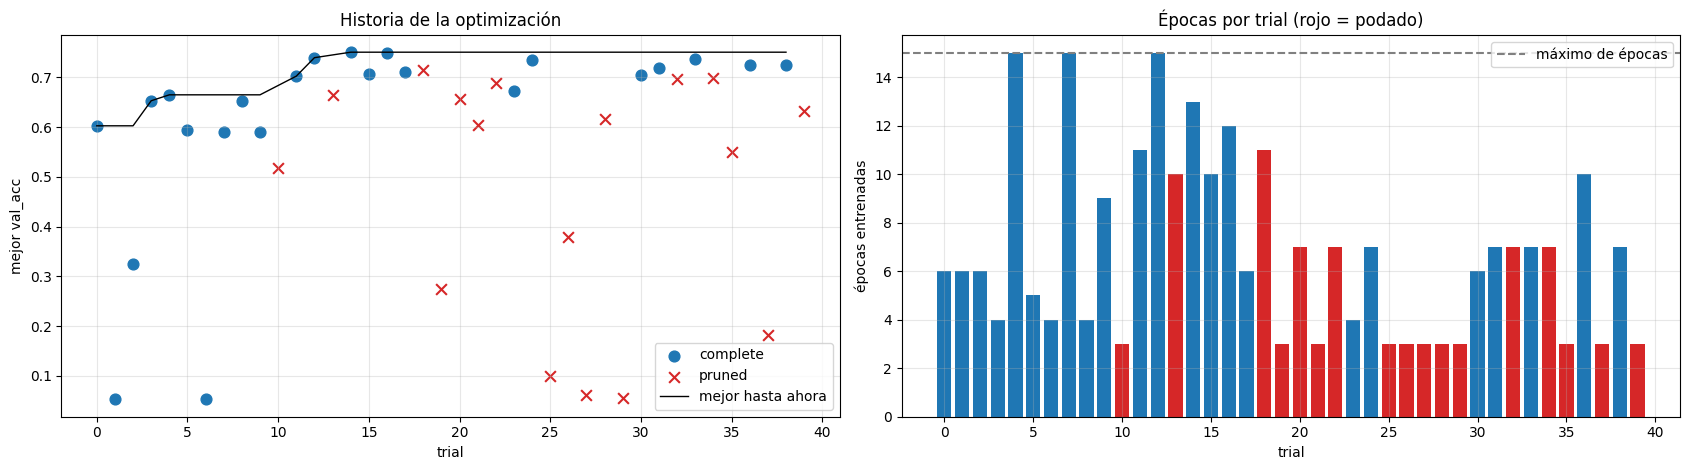

                trials  épocas_promedio  tiempo_total_s
corte                                                  
early_stopping      20              7.2           205.9
max_epochs           3             15.0            51.0
pruned              17              4.8           153.9


In [13]:
# Historia de la búsqueda y efecto del pruning
fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))
ax = axes[0]
for estado, marker, color in [("COMPLETE", "o", "tab:blue"), ("PRUNED", "x", "tab:red")]:
    s = df[df["estado"] == estado]
    ax.scatter(s["trial"], s["best_val_acc"], marker=marker, color=color, s=60, label=estado.lower())
ax.plot(df_ok["trial"], df_ok["best_val_acc"].cummax(), "k-", lw=1, label="mejor hasta ahora")
ax.set_xlabel("trial"); ax.set_ylabel("mejor val_acc"); ax.set_title("Historia de la optimización"); ax.legend()

ax = axes[1]
colores = df["estado"].map({"COMPLETE": "tab:blue", "PRUNED": "tab:red"})
ax.bar(df["trial"], df["épocas"], color=colores)
ax.axhline(MAX_EPOCHS_SEARCH, ls="--", c="gray", label="máximo de épocas")
ax.set_xlabel("trial"); ax.set_ylabel("épocas entrenadas"); ax.set_title("Épocas por trial (rojo = podado)"); ax.legend()
for a in axes:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(df.groupby("corte").agg(trials=("trial", "count"), épocas_promedio=("épocas", "mean"),
                              tiempo_total_s=("train_time_s", "sum")).round(1).to_string())

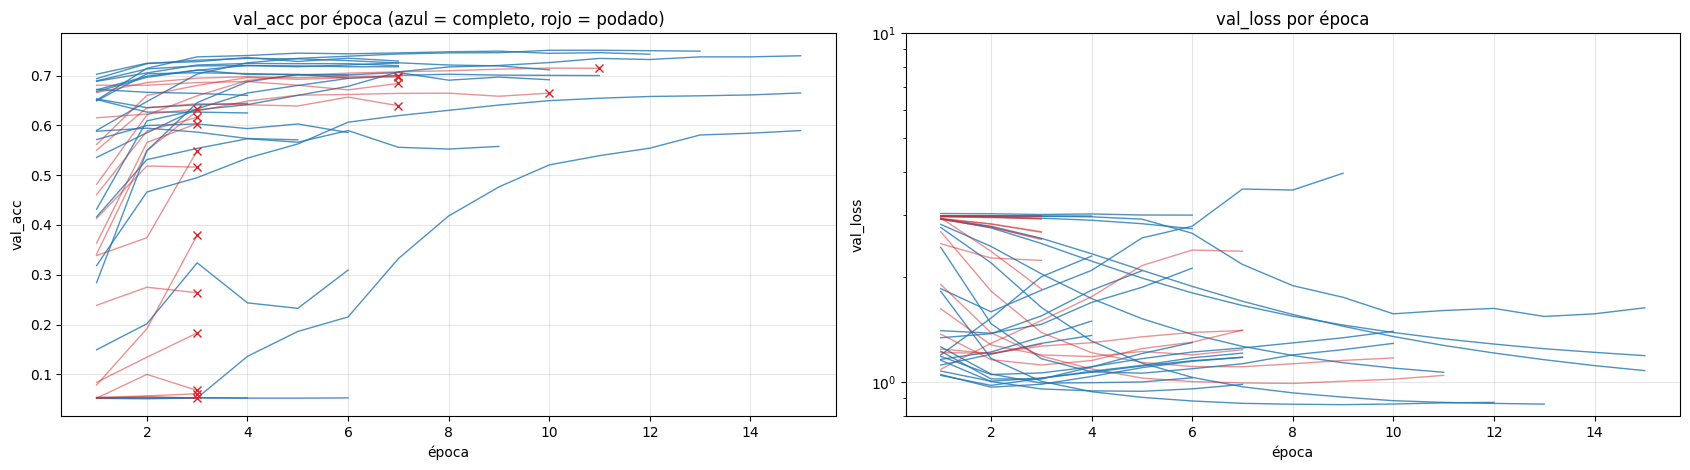

In [14]:
# Curvas de validación de TODOS los trials: se ve dónde corta el pruner
fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))
for t in study.trials:
    if "history" not in t.user_attrs:
        continue
    h = t.user_attrs["history"]
    ep = np.arange(1, len(h["val_acc"]) + 1)
    podado = t.state == optuna.trial.TrialState.PRUNED
    estilo = dict(color="tab:red" if podado else "tab:blue", alpha=0.5 if podado else 0.8, lw=1)
    axes[0].plot(ep, h["val_acc"], **estilo)
    axes[1].plot(ep, h["val_loss"], **estilo)
    if podado:
        axes[0].plot(ep[-1], h["val_acc"][-1], "x", color="tab:red")
axes[0].set_title("val_acc por época (azul = completo, rojo = podado)"); axes[0].set_ylabel("val_acc")
axes[1].set_title("val_loss por época"); axes[1].set_ylabel("val_loss"); axes[1].set_yscale("log")
axes[1].set_ylim(top=10)   # algún trial divergente puede tener loss enorme: recortamos el eje
for a in axes:
    a.set_xlabel("época"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

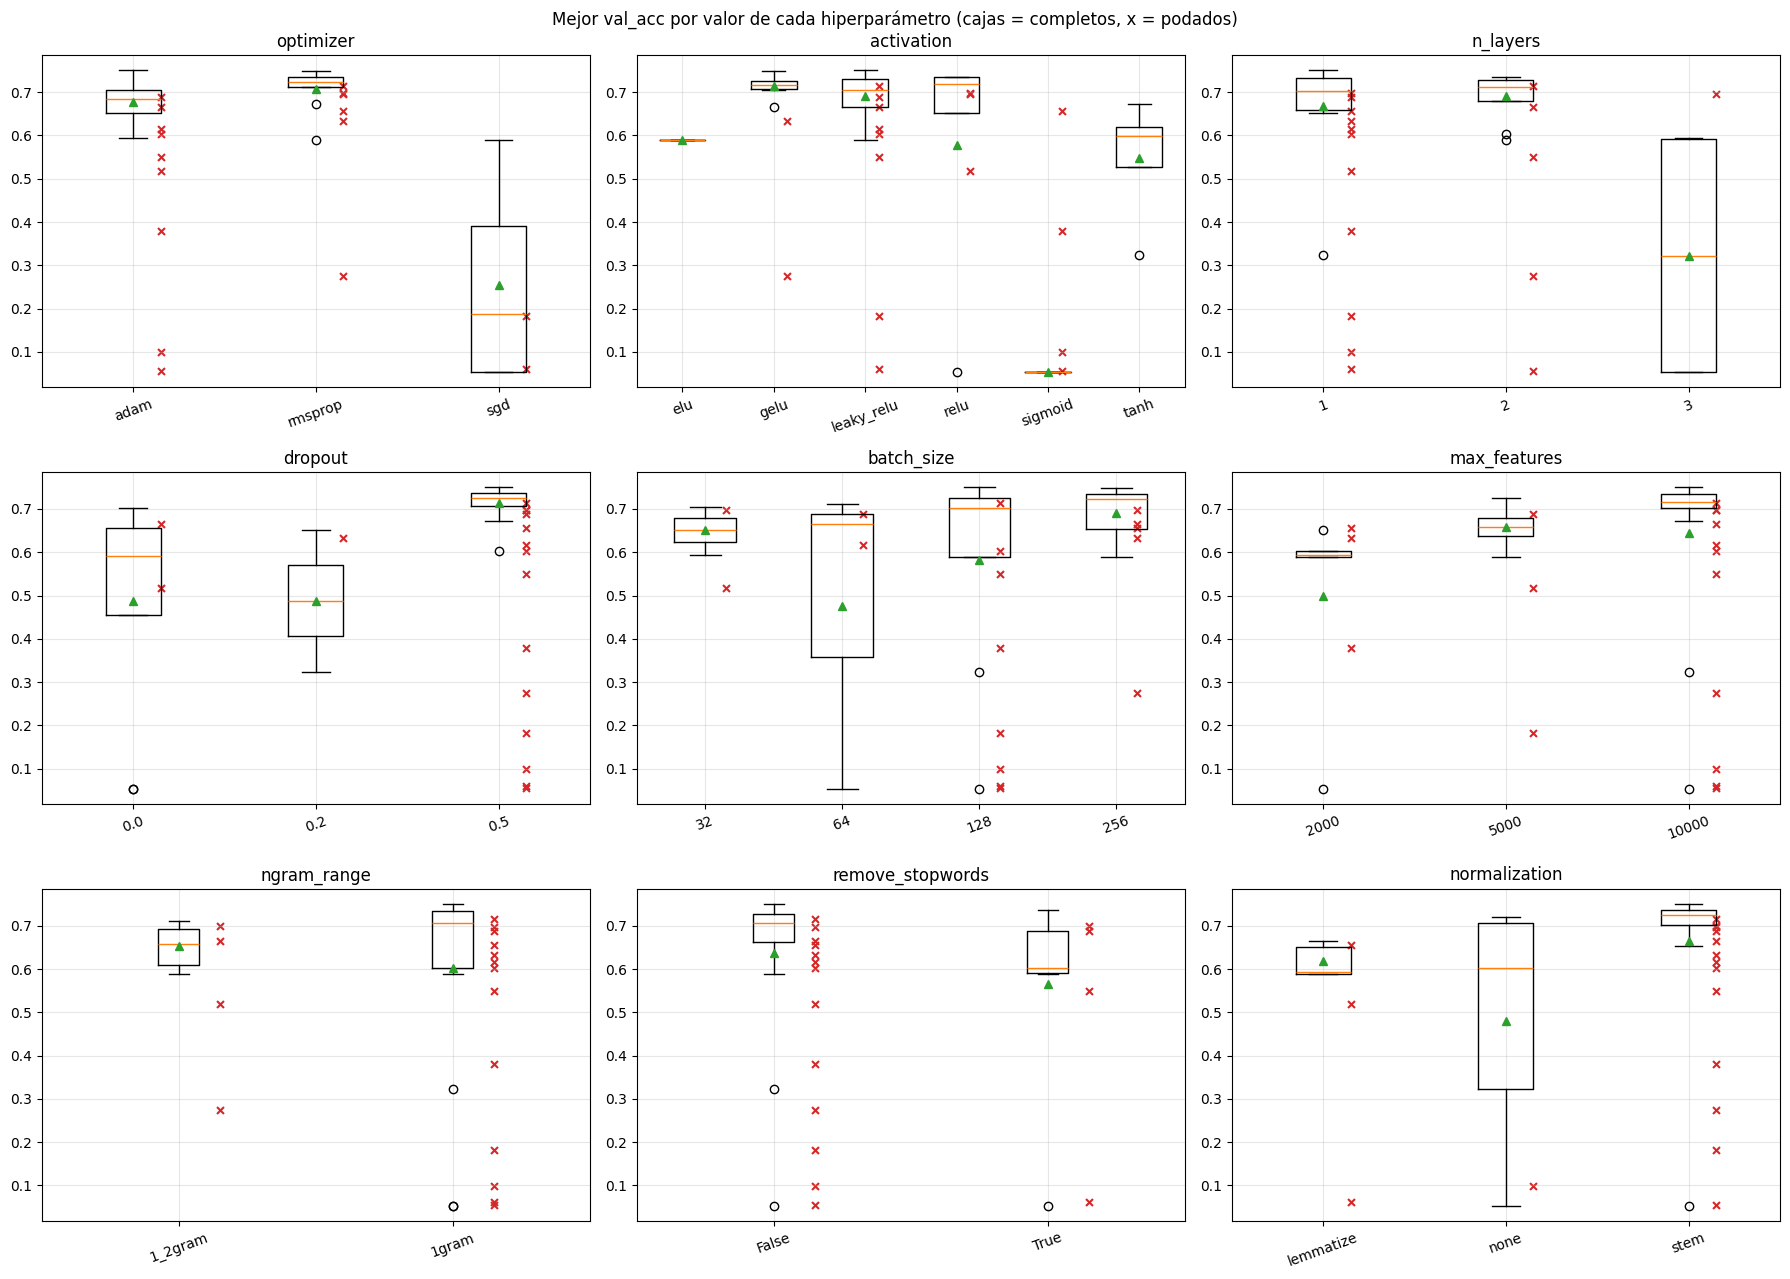


--- optimizer ---
           trials  podados  mejor_val_acc  media_completos  s_por_época
optimizer                                                              
adam           19        9         0.7508           0.6772       1.6614
rmsprop        15        6         0.7490           0.7069       1.6449
sgd             6        2         0.5895           0.2548       0.7525

--- activation ---
            trials  podados  mejor_val_acc  media_completos  s_por_época
activation                                                              
elu              1        0         0.5895           0.5895       0.4008
gelu             8        2         0.7490           0.7135       1.4362
leaky_relu      14        8         0.7508           0.6902       1.6972
relu             8        3         0.7362           0.5791       2.0189
sigmoid          5        4         0.6567           0.0526       1.1674
tanh             4        0         0.6721           0.5483       0.7786

--- n_layers ---

In [15]:
# Efecto de cada hiperparámetro (sólo trials completos; las cruces rojas son podados, con su mejor val_acc parcial)
params_cat = ["optimizer", "activation", "n_layers", "dropout", "batch_size", "max_features",
              "ngram_range", "remove_stopwords", "normalization"]
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for ax, p in zip(axes.ravel(), params_cat):
    valores = sorted(df[p].unique())   # orden natural (numérico o alfabético)
    data = [df_ok.loc[df_ok[p] == v, "best_val_acc"].values for v in valores]
    ax.boxplot([d if len(d) else [np.nan] for d in data], showmeans=True)
    ax.set_xticks(range(1, len(valores) + 1)); ax.set_xticklabels([str(v) for v in valores], rotation=20)
    for i, v in enumerate(valores):
        pr = df[(df[p] == v) & (df["estado"] == "PRUNED")]["best_val_acc"]
        ax.scatter(np.full(len(pr), i + 1.15), pr, marker="x", color="tab:red", s=25)
    ax.set_title(p); ax.grid(alpha=0.3)
plt.suptitle("Mejor val_acc por valor de cada hiperparámetro (cajas = completos, x = podados)")
plt.tight_layout(); plt.show()

for p in ["optimizer", "activation", "n_layers", "dropout"]:
    print(f"\n--- {p} ---")
    print(df.groupby(p).agg(trials=("trial", "count"),
                            podados=("estado", lambda s: int((s == "PRUNED").sum())),
                            mejor_val_acc=("best_val_acc", "max"),
                            media_completos=("best_val_acc", lambda s: s[df.loc[s.index, "estado"] == "COMPLETE"].mean()),
                            s_por_época=("s_por_época", "mean")).round(4).to_string())

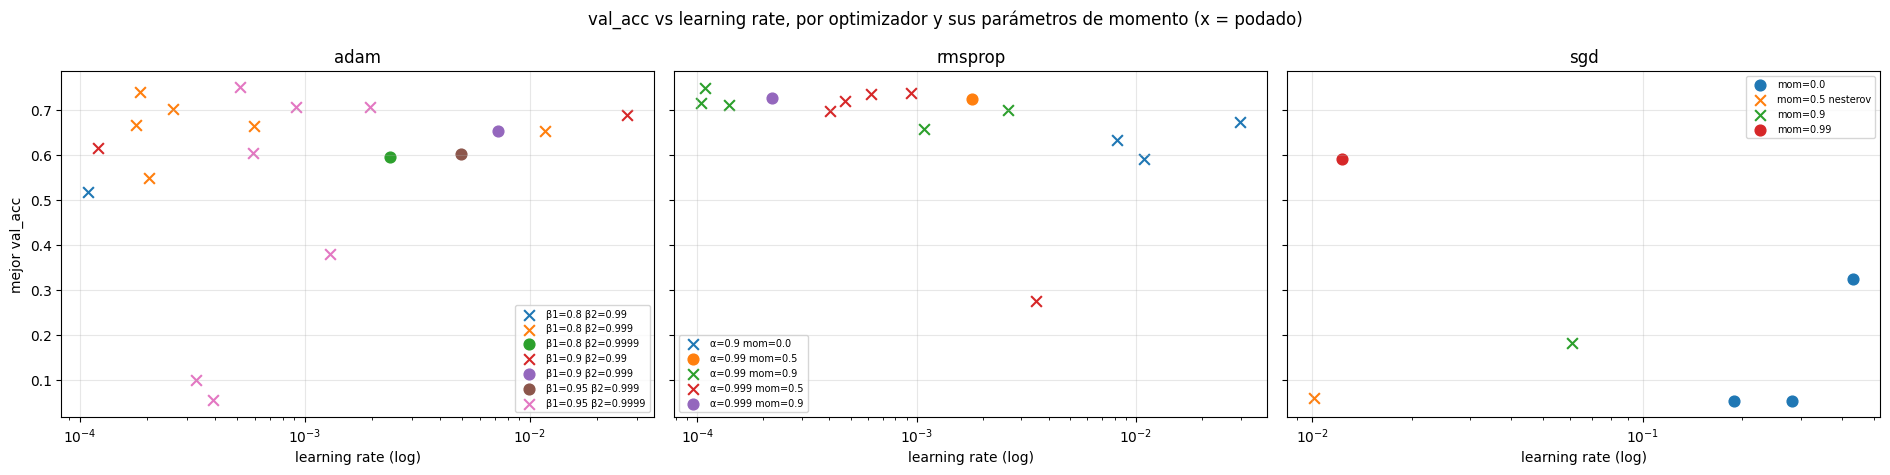

In [16]:
# Learning rate y momentos por optimizador
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), sharey=True)
for ax, opt in zip(axes, ["adam", "rmsprop", "sgd"]):
    s = df[df["optimizer"] == opt]
    for detalle, g in s.groupby("opt_params"):
        ax.scatter(g["lr"], g["best_val_acc"], s=60, label=detalle,
                   marker="o" if (g["estado"] == "COMPLETE").all() else "x")
    ax.set_xscale("log"); ax.set_xlabel("learning rate (log)"); ax.set_title(opt)
    ax.grid(alpha=0.3); ax.legend(fontsize=7)
axes[0].set_ylabel("mejor val_acc")
plt.suptitle("val_acc vs learning rate, por optimizador y sus parámetros de momento (x = podado)")
plt.tight_layout(); plt.show()

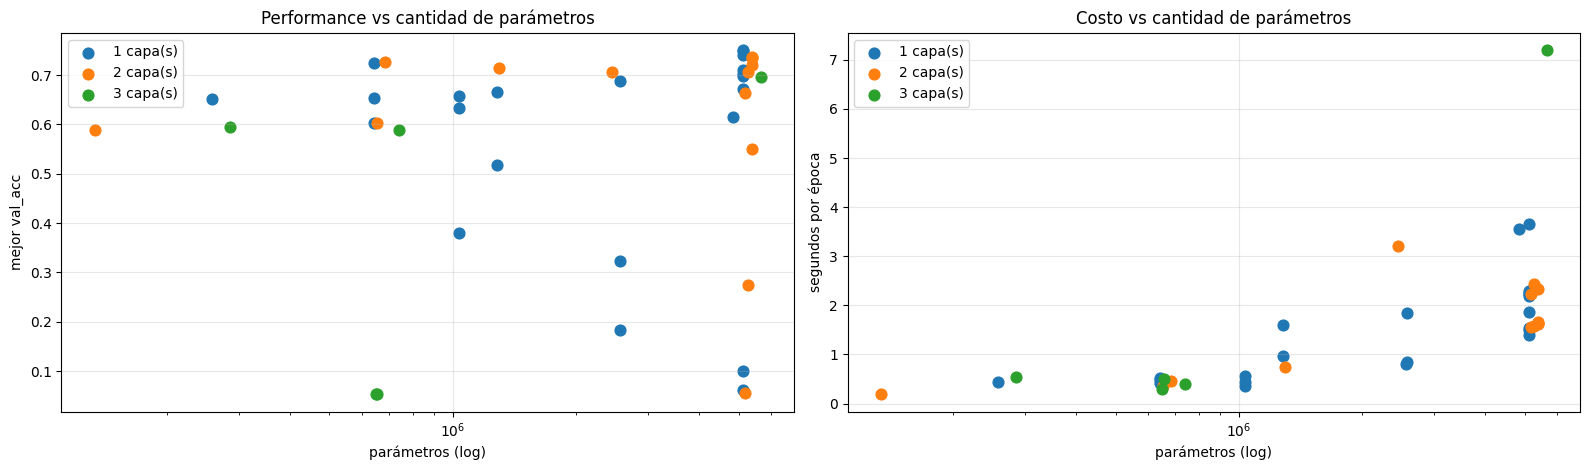

Correlación de Spearman entre parámetros y s/época: +0.79


In [17]:
# Tamaño del modelo: performance y costo
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for nl, g in df.groupby("n_layers"):
    axes[0].scatter(g["n_params"], g["best_val_acc"], s=60, label=f"{nl} capa(s)")
    axes[1].scatter(g["n_params"], g["s_por_época"], s=60, label=f"{nl} capa(s)")
axes[0].set_ylabel("mejor val_acc"); axes[0].set_title("Performance vs cantidad de parámetros")
axes[1].set_ylabel("segundos por época"); axes[1].set_title("Costo vs cantidad de parámetros")
for a in axes:
    a.set_xscale("log"); a.set_xlabel("parámetros (log)"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()
rho = df["n_params"].corr(df["s_por_época"], method="spearman")
print(f"Correlación de Spearman entre parámetros y s/época: {rho:+.2f}")

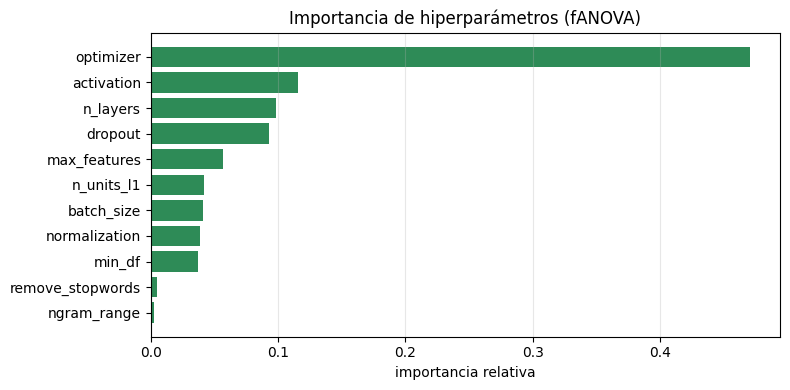

optimizer          0.471
activation         0.115
n_layers           0.099
dropout            0.093
max_features       0.057
n_units_l1         0.041
batch_size         0.041
normalization      0.039
min_df             0.037
remove_stopwords   0.005
ngram_range        0.003


In [18]:
# Importancia de hiperparámetros (fANOVA, sólo trials completos)
# Optuna sólo puede evaluar los hiperparámetros presentes en TODOS los trials completos:
# los condicionales (lr de cada optimizador, betas, momentos, n_units_l2/l3) quedan afuera.
# La semilla se pasa al evaluador fANOVA (get_param_importances no recibe `seed` directamente).
try:
    evaluador = optuna.importance.FanovaImportanceEvaluator(seed=SEED)
    importances = optuna.importance.get_param_importances(study, evaluator=evaluador)
    plt.figure(figsize=(8, 4))
    plt.barh(list(importances)[::-1], list(importances.values())[::-1], color="seagreen")
    plt.xlabel("importancia relativa"); plt.title("Importancia de hiperparámetros (fANOVA)")
    plt.grid(alpha=0.3, axis="x"); plt.tight_layout(); plt.show()
    for k, v in importances.items():
        print(f"{k:18s} {v:.3f}")
except Exception as e:
    print("No se pudo calcular la importancia:", e)

In [19]:
# BONUS: ¿cuánto tiempo ahorró el pruning?
# Para cada trial podado estimamos cuánto habría tardado si seguía hasta MAX_EPOCHS_SEARCH
# (o hasta donde lo habría cortado el early stopping, que no podemos saber: es una cota superior).
pr = df[df["estado"] == "PRUNED"]
ahorro_max = float(((MAX_EPOCHS_SEARCH - pr["épocas"]) * pr["s_por_época"]).sum())
tiempo_real = float(df["train_time_s"].sum())
print(f"Trials podados: {len(pr)} de {len(df)}")
print(f"Tiempo de entrenamiento real de la búsqueda: {tiempo_real/60:.1f} min")
print(f"Tiempo que se habría gastado sin pruning (cota superior): {(tiempo_real + ahorro_max)/60:.1f} min")
print(f"Ahorro máximo estimado: {ahorro_max/60:.1f} min ({ahorro_max/(tiempo_real + ahorro_max):.0%})")
if len(pr):
    print(f"Mejor val_acc alcanzada por un trial podado: {pr['best_val_acc'].max():.4f} "
          f"(vs mejor completo {df_ok['best_val_acc'].max():.4f})")

Trials podados: 17 de 40
Tiempo de entrenamiento real de la búsqueda: 6.8 min
Tiempo que se habría gastado sin pruning (cota superior): 12.0 min
Ahorro máximo estimado: 5.2 min (43%)
Mejor val_acc alcanzada por un trial podado: 0.7150 (vs mejor completo 0.7508)


In [20]:
# Resumen automático de la búsqueda
top = df_ok.nlargest(5, "best_val_acc")
print("TOP-5 trials completos:")
display(top[["trial", "best_val_acc", "best_epoch", "optimizer", "lr", "opt_params", "activation", "capas",
             "dropout", "batch_size", "max_features", "ngram_range", "remove_stopwords", "normalization",
             "n_params", "train_time_s"]].round(4))
for p in ["optimizer", "activation", "n_layers", "dropout", "ngram_range", "remove_stopwords"]:
    vc = top[p].astype(str).value_counts()
    print(f"  {p:17s} más frecuente en el top-5: {vc.index[0]} ({vc.iloc[0]}/5)")
print(f"\nRango de val_acc (completos): {df_ok['best_val_acc'].min():.4f} – {df_ok['best_val_acc'].max():.4f}")
print(f"Error estándar aprox. de una val_acc de {df_ok['best_val_acc'].max():.2f} con {len(idx_val)} docs: "
      f"±{np.sqrt(df_ok['best_val_acc'].max()*(1-df_ok['best_val_acc'].max())/len(idx_val)):.4f}")

TOP-5 trials completos:


,trial,best_val_acc,best_epoch,optimizer,lr,opt_params,activation,capas,dropout,batch_size,max_features,ngram_range,remove_stopwords,normalization,n_params,train_time_s
14,14,0.7508,10,adam,0.0005,β1=0.95 β2=0.9999,leaky_relu,512,0.5,128,10000,1gram,False,stem,5130772,29.3214
16,16,0.7490,9,rmsprop,0.0001,α=0.99 mom=0.9,gelu,512,0.5,256,10000,1gram,False,stem,5130772,18.5383
12,12,0.7397,15,adam,0.0002,β1=0.8 β2=0.999,leaky_relu,512,0.5,128,10000,1gram,False,stem,5130772,33.5476
33,33,0.7362,4,rmsprop,0.0009,α=0.999 mom=0.5,relu,512-512,0.5,256,10000,1gram,True,stem,5393428,11.3030
24,24,0.7344,4,rmsprop,0.0006,α=0.999 mom=0.5,relu,512-512,0.5,256,10000,1gram,False,stem,5393428,11.5989


  optimizer         más frecuente en el top-5: rmsprop (3/5)
  activation        más frecuente en el top-5: leaky_relu (2/5)
  n_layers          más frecuente en el top-5: 1 (3/5)
  dropout           más frecuente en el top-5: 0.5 (5/5)
  ngram_range       más frecuente en el top-5: 1gram (5/5)
  remove_stopwords  más frecuente en el top-5: False (4/5)

Rango de val_acc (completos): 0.0526 – 0.7508
Error estándar aprox. de una val_acc de 0.75 con 2263 docs: ±0.0091


### Análisis de la búsqueda

**Resumen**: 40 trials en **7,7 minutos**. 23 completos (20 cortados por early stopping y 3 que llegaron a las 15 épocas) y **17 podados (42%)**.

**Mejor trial (#14, val_acc = 0.7508)**:

| Grupo | Hiperparámetros |
|---|---|
| Arquitectura | 1 capa oculta de 512 neuronas, **LeakyReLU**, dropout 0.5 |
| Optimizador | **Adam**, lr = 5,1·10⁻⁴, β₁ = 0.95, β₂ = 0.9999, batch 128 |
| Preprocesamiento | sin quitar stopwords, **stem**, **unigramas**, 10.000 features, min_df = 2 |

Los tres mejores (0.7508, 0.7490 y 0.7397) están **estadísticamente empatados**: el error estándar con 2.263 documentos de validación es ±0.009.

**1. Comportamiento de TPE.** Los primeros 10 trials son aleatorios y el mejor de ellos llegó a 0.665. Desde el trial 11, TPE se concentró en la región buena (1 capa de 512, dropout 0.5, stem, unigramas, 10.000 features) y encontró 0.70–0.75 en pocos trials: el muestreo guiado claramente sirvió. A partir del trial ~18, con una mediana de referencia alta, el pruner empezó a cortar casi todo lo que no mejoraba esa región.

**2. Optimizadores**:

| Optimizador | Trials | Podados | Mejor | Media (completos) |
|---|---|---|---|---|
| Adam | 19 | 9 | **0.7508** | 0.677 |
| RMSprop | 15 | 6 | 0.7490 | **0.707** |
| SGD | 6 | 2 | 0.5895 | 0.255 |

- **Adam** logró el mejor trial y **RMSprop** fue el más **robusto** (mejor media). Ambos normalizan el paso por el momento de orden 2, lo que funciona muy bien con features TF-IDF chicos y dispersos.
- **SGD fracasó**:
  - sin momento y con lr de 0.19–0.43 quedó en el azar (0.05) o apenas por encima (0.32);
  - el único SGD razonable (#7: 0.5895) usó **momentum 0.99** con lr = 0.012, lo que da un paso efectivo ≈ lr/(1−μ) ≈ 1.2, y todavía estaba mejorando en la época 15.

  Es decir, SGD necesita el momento de orden 1 para avanzar, y aun así es mucho más lento. TPE lo aprendió: sólo le dedicó 6 de 40 trials.

**3. Momentos de orden 1 y 2.**
- **Adam**: los mejores usaron tanto β₁ = 0.95, β₂ = 0.9999 (#14) como β₁ = 0.8, β₂ = 0.999 (#12). No hay un patrón claro en las betas: el **learning rate** pesa mucho más. Los Adam con β₁ = 0.95, β₂ = 0.9999 que fallaron (#25, #29) usaban **sigmoid**, y el problema es la activación, no las betas.
- **RMSprop**: todos los del top usan **momentum 0.5–0.9** (orden 1) con α = 0.99–0.999 (orden 2). Los RMSprop sin momentum (#9, #23, #39) quedaron en 0.59–0.67. **Agregar el momento de orden 1 a RMSprop ayudó.**

**4. Learning rate.** Los mejores Adam/RMSprop están en **10⁻⁴ – 10⁻³**, un orden de magnitud **menor** que el de la softmax del TP1 (3·10⁻³ en el mejor trial de su análisis). Un MLP con lr alto sobreajusta de inmediato: los trials con lr > 5·10⁻³ (#3, #8, #23) tuvieron su mejor val_acc en la **época 1**, y después el early stopping los cortó.

**5. Activaciones**:

| Activación | Trials | Podados | Mejor | Media (completos) |
|---|---|---|---|---|
| LeakyReLU | 14 | 8 | **0.7508** | 0.690 |
| GELU | 8 | 2 | 0.7490 | **0.713** |
| ReLU | 8 | 3 | 0.7362 | 0.579 |
| Tanh | 4 | 0 | 0.6721 | 0.548 |
| Sigmoid | 5 | **4** | 0.6567 | 0.053 |
| ELU | 1 | 0 | 0.5895 | — (un solo trial, no concluyente) |

- Las de la familia ReLU y GELU dominan.
- **Sigmoid** fue la peor: 4 de 5 trials podados, y el único completo quedó en el azar (con SGD y 3 capas). Su derivada vale como mucho 0.25 y se satura: el gradiente se desvanece al atravesar capas. Con 1 capa y RMSprop llegó a 0.657, así que puede entrenar, pero peor.
- **Tanh** quedó en el medio: está centrada en 0, pero también se satura.

**6. Capas.** **1 capa oculta fue lo mejor** (0.7508), 2 capas llegaron a 0.736 y 3 capas a 0.697 (#32, podado). Con TF-IDF, la información relevante es "qué palabras aparecen", y la primera capa ya la captura. Las capas extra suman costo y sobreajuste, no accuracy. Las medias de 3 capas (0.32) están además arrastradas por trials con SGD o sigmoid.

**7. Dropout: muy favorecido.** 27 de 40 trials usaron 0.5, y **los 5 mejores usan 0.5**. La media de los completos es 0.714 con 0.5 contra 0.487 con 0.0.
- Con 512 neuronas y 5 M de parámetros para 9.000 documentos, el dropout frena la memorización y permite entrenar **más épocas** antes de sobreajustar. Los mejores (#14, #16, #12) alcanzaron su máximo en las épocas 10, 9 y 15, mientras que los trials sin dropout y lr alto lo hicieron en la época 1.

**8. Preprocesamiento.** Los 5 mejores usan **stem + unigramas + 10.000 features**, igual que el mejor trial descripto en el análisis del TP1.
- Los bigramas rindieron peor (el mejor llegó a 0.711), y ningún trial con 2.000 features superó 0.657.
- Las stopwords no importan: el #33 (quitándolas) y el #24 (dejándolas), con todo lo demás casi igual, dan 0.736 y 0.734. En el TP1 también era un empate.

**9. Tiempos.** El costo por época crece con los parámetros (Spearman +0.79): desde 0.19 s/época (133 k parámetros) hasta 7.2 s/época (#32: 3×512 con batch 32).
- **La primera capa domina**: 1×512 tiene 5.13 M de parámetros y 2×512 tiene 5.39 M, apenas un 5% más. Lo que más encarece es el ancho de la primera capa ($10.000 \times h_1$) y los batch chicos (más pasos por época).

**10. Bonus: pruning.** Según la celda de ahorro:
- Los 17 trials podados entrenaron 154 s. Si hubieran llegado a las 15 épocas, habrían costado hasta **5,2 min más**.
- Tiempo total de entrenamiento de la búsqueda: 6,8 min reales, contra ~12,0 min sin pruning (**ahorro ≈ 43%**).
- Sumando el early stopping (otros ~3,1 min ahorrados), la búsqueda sin ninguno de los dos habría tardado ~15 min: entre ambos ahorraron **más de la mitad del tiempo**.
- **Costo del pruning**: el mejor trial podado (#18, RMSprop, 2×128) iba en 0.715 cuando lo cortaron en la época 11. Era competitivo pero no estaba en el top (0.73–0.75), así que no se perdió nada importante. El trial más caro (#32, 3 capas, 7.2 s/época) fue podado en la época 7 y ahorró ~58 segundos por sí solo.

**11. Importancia de hiperparámetros (fANOVA).**

| Hiperparámetro | Importancia |
|---|---|
| optimizer | **0.47** |
| activation | 0.12 |
| n_layers | 0.10 |
| dropout | 0.09 |
| max_features | 0.06 |
| n_units_l1, batch_size | 0.04 c/u |
| normalization, min_df | 0.04 c/u |
| remove_stopwords, ngram_range | < 0.01 |

- **El optimizador explica casi la mitad de la variación de la val_acc.** Es básicamente la diferencia entre SGD (que fracasó) y los optimizadores con momento de orden 2. Lo siguen la activación (sobre todo, el efecto de sigmoid) y la arquitectura (capas y dropout).
- **El preprocesamiento pesa poco**, y stopwords y n-gramas casi nada. Coincide con los empates que vimos tanto acá como en el TP1.
- **Limitaciones**:
  - fANOVA sólo evalúa los hiperparámetros presentes en **todos** los trials completos. Los condicionales (el learning rate de cada optimizador, las betas, los momentos, `n_units_l2/l3`) quedan afuera, y el lr fue muy determinante (punto 4).
  - Con 23 trials completos la estimación es ruidosa.
  - El valor bajo de `ngram_range` no contradice que los bigramas rindieran peor: hubo pocos trials completos con bigramas, y en ellos el efecto se mezcla con el del optimizador y la activación.

## 7. Entrenamiento final y evaluación en test

Entrenamos la mejor configuración con **todo el train** (11.314 documentos) y la evaluamos en el **test**, que no se usó en la búsqueda.

La cantidad de épocas es la `best_epoch` del mejor trial: se eligió con **validación**, no mirando el test. En el TP1 se entrenaban 20 épocas fijas y el test mostraba que el óptimo estaba antes. El "val" del log de esta celda es el test, y se usa sólo para monitorear.

Se registra en TensorBoard (`runs/mlp_final`) y en MLflow (experimento `mlp_20newsgroups`, con el modelo serializado).

In [21]:
# Entrenamiento final con los mejores hiperparámetros
bt = study.best_trial
bp = bt.params
BEST_HIDDEN = bt.user_attrs["hidden"]
BEST_EPOCHS = bt.user_attrs["best_epoch"]   # cantidad de épocas elegida con VALIDACIÓN (no con test)
BEST_NGRAM = (1, 1) if bp["ngram_range"] == "1gram" else (1, 2)
if bp["optimizer"] == "adam":
    opt_kw = {"beta1": bp["adam_beta1"], "beta2": bp["adam_beta2"]}
elif bp["optimizer"] == "rmsprop":
    opt_kw = {"alpha": bp["rmsprop_alpha"], "momentum": bp["rmsprop_momentum"]}
else:
    opt_kw = {"momentum": bp["sgd_momentum"], "nesterov": bp.get("sgd_nesterov", False)}
BEST_LR = bt.user_attrs["lr"]
print("Arquitectura:", BEST_HIDDEN, "| activación:", bp["activation"], "| dropout:", bp["dropout"])
print("Optimizador:", bp["optimizer"], "lr =", f"{BEST_LR:.2e}", opt_kw, "| batch:", bp["batch_size"],
      "| épocas:", BEST_EPOCHS)

train_texts_final, test_texts_final = preprocessed_cache[(bp["remove_stopwords"], bp["normalization"])]
X_train_final, X_test_final, vectorizer_final = vectorize_data(
    train_texts_final, test_texts_final, BEST_NGRAM, bp["max_features"], bp["min_df"])

torch.manual_seed(SEED)
train_loader_final = DataLoader(to_tensor_dataset(X_train_final, y_train_all), batch_size=bp["batch_size"], shuffle=True)
test_loader_final = DataLoader(to_tensor_dataset(X_test_final, y_test), batch_size=1024, shuffle=False)

model = MLP(X_train_final.shape[1], BEST_HIDDEN, NUM_CLASSES, activation=bp["activation"], dropout=bp["dropout"])
optimizer = make_optimizer(bp["optimizer"], model.parameters(), BEST_LR, **opt_kw)
writer = SummaryWriter(log_dir="runs/mlp_final")

mlflow.end_run()
mlflow.set_experiment("mlp_20newsgroups")
with mlflow.start_run(run_name="mlp_final"):
    mlflow.log_params({**bp, "epochs": BEST_EPOCHS, "n_params": count_params(model)})
    history_final = train_model(model, train_loader_final, test_loader_final, optimizer,
                                epochs=BEST_EPOCHS, writer=writer, run_name="final")
    input_example = X_test_final[:5].astype(np.float32).toarray()
    mlflow.pytorch.log_model(model.cpu(), "model", input_example=input_example)
writer.close()
model.to(device)
print(f"Tiempo de entrenamiento final: {sum(history_final['epoch_time']):.1f}s")

Arquitectura: [512] | activación: leaky_relu | dropout: 0.5
Optimizador: adam lr = 5.14e-04 {'beta1': 0.95, 'beta2': 0.9999} | batch: 128 | épocas: 10


2026/11/09 12:09:20 INFO mlflow.tracking.fluent: Experiment with name 'mlp_20newsgroups' does not exist. Creating a new experiment.


[final] Epoch 1/10 - train_loss: 2.8800 train_acc: 0.3817 - val_loss: 2.6854 val_acc: 0.5871 - 3.1s
[final] Epoch 2/10 - train_loss: 2.2487 train_acc: 0.6711 - val_loss: 1.9791 val_acc: 0.6346 - 3.0s
[final] Epoch 3/10 - train_loss: 1.5147 train_acc: 0.7430 - val_loss: 1.4998 val_acc: 0.6718 - 3.0s
[final] Epoch 4/10 - train_loss: 1.0790 train_acc: 0.7968 - val_loss: 1.2772 val_acc: 0.6803 - 3.1s
[final] Epoch 5/10 - train_loss: 0.8382 train_acc: 0.8260 - val_loss: 1.1663 val_acc: 0.6909 - 3.0s
[final] Epoch 6/10 - train_loss: 0.6827 train_acc: 0.8563 - val_loss: 1.1085 val_acc: 0.6953 - 2.9s
[final] Epoch 7/10 - train_loss: 0.5694 train_acc: 0.8790 - val_loss: 1.0717 val_acc: 0.6950 - 3.0s
[final] Epoch 8/10 - train_loss: 0.4847 train_acc: 0.8946 - val_loss: 1.0567 val_acc: 0.6949 - 2.9s
[final] Epoch 9/10 - train_loss: 0.4191 train_acc: 0.9114 - val_loss: 1.0458 val_acc: 0.6940 - 2.9s


2026/11/09 12:09:50 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


[final] Epoch 10/10 - train_loss: 0.3648 train_acc: 0.9250 - val_loss: 1.0444 val_acc: 0.6950 - 2.9s


Tiempo de entrenamiento final: 29.9s


In [22]:
%load_ext tensorboard
%tensorboard --logdir runs

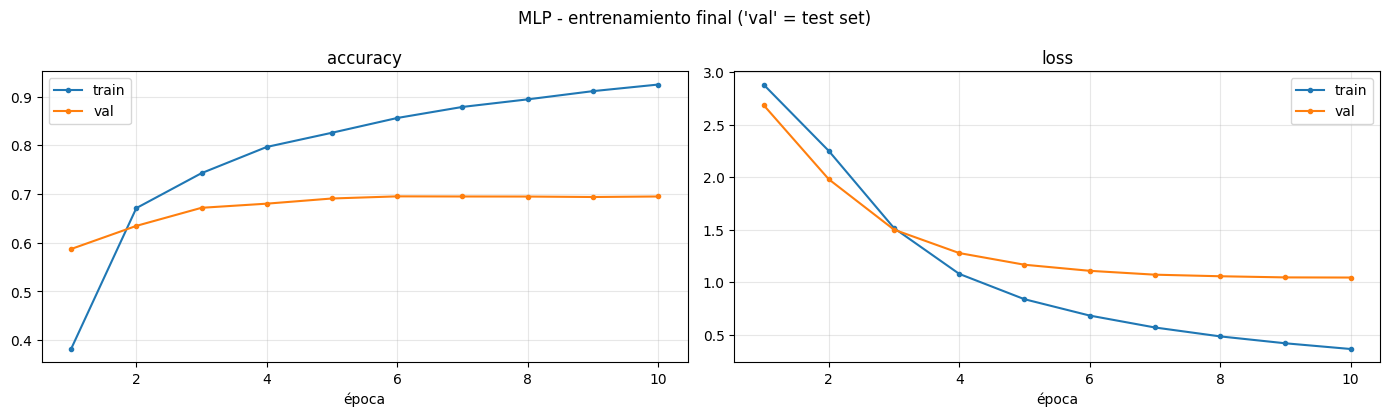

In [23]:
# Las mismas curvas de TensorBoard como imagen estática (para que se vean en GitHub)
graficar_tensorboard("runs/mlp_final", "MLP - entrenamiento final ('val' = test set)")

In [24]:
SOFTMAX_TP1_TEST_ACC = 0.6682   # resultado del TP1 (regresión softmax) para comparar

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader_final:
        all_preds.extend(model(xb.to(device)).argmax(dim=1).cpu().numpy())
        all_labels.extend(yb.numpy())
all_preds, all_labels = np.array(all_preds), np.array(all_labels)

test_accuracy = accuracy_score(all_labels, all_preds)
print(f"Accuracy en test MLP: {test_accuracy:.4f}  |  Softmax TP1: {SOFTMAX_TP1_TEST_ACC:.4f}  |  "
      f"diferencia: {test_accuracy - SOFTMAX_TP1_TEST_ACC:+.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

Accuracy en test MLP: 0.6950  |  Softmax TP1: 0.6682  |  diferencia: +0.0268

                          precision    recall  f1-score   support

             alt.atheism       0.48      0.56      0.52       319
           comp.graphics       0.64      0.67      0.65       389
 comp.os.ms-windows.misc       0.62      0.64      0.63       394
comp.sys.ibm.pc.hardware       0.64      0.65      0.64       392
   comp.sys.mac.hardware       0.72      0.70      0.71       385
          comp.windows.x       0.81      0.67      0.73       395
            misc.forsale       0.79      0.78      0.79       390
               rec.autos       0.74      0.73      0.74       396
         rec.motorcycles       0.80      0.74      0.77       398
      rec.sport.baseball       0.57      0.85      0.69       397
        rec.sport.hockey       0.92      0.89      0.90       399
               sci.crypt       0.81      0.72      0.76       396
         sci.electronics       0.64      0.58      0.61       3

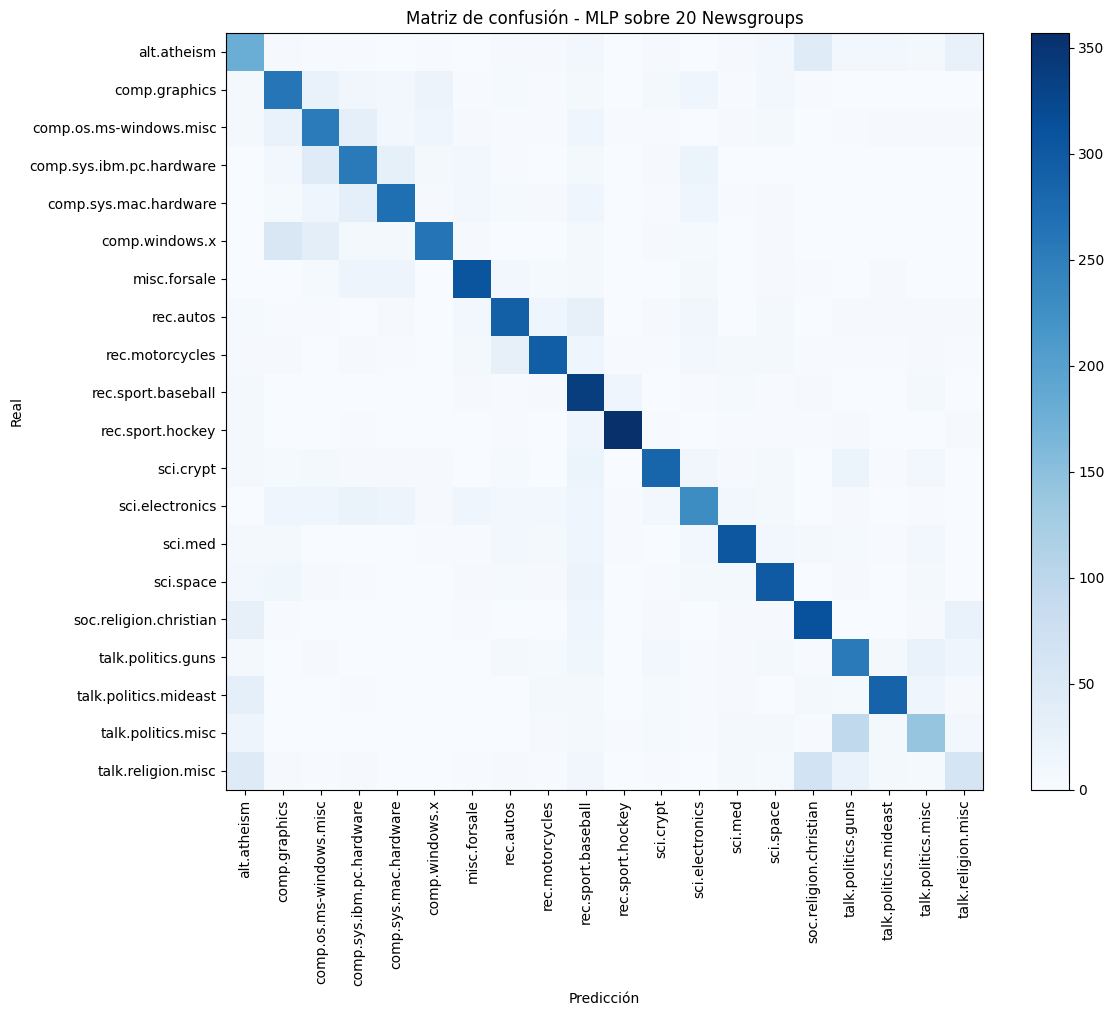

Top 8 confusiones (real -> predicho):
  talk.politics.misc         -> talk.politics.guns           94 docs (30.3%)
  talk.religion.misc         -> soc.religion.christian       66 docs (26.3%)
  comp.windows.x             -> comp.graphics                53 docs (13.4%)
  talk.religion.misc         -> alt.atheism                  44 docs (17.5%)
  alt.atheism                -> soc.religion.christian       43 docs (13.5%)
  comp.sys.ibm.pc.hardware   -> comp.os.ms-windows.misc      42 docs (10.7%)
  comp.windows.x             -> comp.os.ms-windows.misc      34 docs (8.6%)
  comp.sys.mac.hardware      -> comp.sys.ibm.pc.hardware     33 docs (8.6%)


In [25]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title("Matriz de confusión - MLP sobre 20 Newsgroups")
plt.tight_layout(); plt.show()

cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pares = sorted(((cm_off[i, j], i, j) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm_off[i, j] > 0), reverse=True)
print("Top 8 confusiones (real -> predicho):")
for n, i, j in pares[:8]:
    print(f"  {class_names[i]:26s} -> {class_names[j]:26s} {n:4d} docs ({n / cm[i].sum():.1%})")

### Análisis del entrenamiento final y la evaluación

**Entrenamiento.** Se entrenaron **10 épocas** (la mejor época del trial #14, elegida con validación), en 29,9 s (3,0 s/época).
- La accuracy de test sube hasta ~0.695 en la época 6 y queda **estable** hasta la 10 (0.6950).
- La test_loss **sigue bajando** hasta el final (1.044).

A diferencia del TP1, donde con 20 épocas fijas la test_acc caía después de las primeras épocas (desde la 7 según su análisis, desde la 5 en sus salidas guardadas), acá no hay señales de sobreajuste. Elegir las épocas con validación funcionó.

**Resultado en test: 0.6950 vs 0.6682 de la softmax del TP1 (+2,7 puntos).** Con 7.532 documentos de test, el error estándar es ≈ ±0.005, así que la mejora es real, aunque modesta. La macro-F1 pasa de 0.66 a 0.68.

> **Sobre el valor de la softmax del TP1.** El 0.6682 (fijado en el código como `SOFTMAX_TP1_TEST_ACC`) es el resultado que figura en el análisis del TP1. Las salidas guardadas del notebook del TP1 corresponden a una re-ejecución posterior, en la que Optuna eligió otra configuración (sin quitar stopwords, sin normalización, lr ≈ 0.01, batch 128) y el test dio **0.6456** (macro-F1 0.64). La diferencia se debe a que en el TP1 el estudio de Optuna no tenía semilla, así que cada ejecución encontraba otra configuración; por eso a partir del TP2 se fijó `TPESampler(seed=SEED)`. Las comparaciones con el TP1 de este notebook (test, F1 por clase, épocas) usan los valores de su análisis.
>
> La conclusión no cambia con ninguno de los dos valores: el MLP supera a la softmax por +2,7 puntos (contra 0.668) o por +4,9 (contra 0.646). La comparación más confiable es la de la **misma validación**, con semilla fija (secciones 8 y 10): softmax 0.7265 contra MLP 0.7508.

**Validación (0.751) vs test (0.695).** Hay 5,6 puntos de diferencia, por las mismas razones que en el TP1:
- el test es **temporalmente posterior** al train (split "bydate"), mientras que la validación salió al azar del propio train;
- hay sesgo de selección al elegir el mejor de 40 trials.

La brecha es algo menor que en el TP1 (7 puntos según su análisis).

**Por clase (MLP vs softmax TP1, F1; valores del TP1 según su análisis):**
- **Mejoran**:
  - `talk.politics.mideast`: 0.77 → 0.80
  - `misc.forsale`: 0.75 → 0.79
  - `sci.med`: 0.75 → 0.79
  - `rec.sport.hockey`: 0.88 → 0.90
  - `alt.atheism`: 0.49 → 0.52
  - `sci.electronics`: 0.58 → 0.61
- **Empeora**: `talk.religion.misc`, 0.34 → **0.29**, con recall de apenas 0.24. El MLP manda todavía más documentos de esa clase "cajón de sastre" a sus vecinas grandes.
- **Persiste el artefacto de `rec.sport.baseball`**: precision 0.57 y recall 0.85, el mismo patrón del TP1. Una explicación posible (no medida en este notebook) son los documentos que quedan vacíos tras el preprocesamiento: con un vector nulo, el modelo responde siempre la misma clase.

**Confusiones**: los mismos bloques temáticos que el TP1.

| Real → Predicho | Docs | % de la clase real |
|---|---|---|
| `talk.politics.misc` → `talk.politics.guns` | 94 | 30% |
| `talk.religion.misc` → `soc.religion.christian` | 66 | 26% |
| `comp.windows.x` → `comp.graphics` | 53 | — |
| `talk.religion.misc` → `alt.atheism` | 44 | — |
| `alt.atheism` → `soc.religion.christian` | 43 | — |
| `comp.sys.ibm.pc.hardware` → `comp.os.ms-windows.misc` | 42 | — |

El MLP mejora la accuracy global, pero **no resuelve las confusiones de fondo**: vienen del vocabulario compartido y de las categorías "misc", algo que una bolsa de palabras no puede separar, tenga o no capas ocultas. Coincide con lo que se respondió en la pregunta 10 del TP1.

## 8. Experimento de sobreajuste

**Objetivo**: encontrar una cantidad de capas y unidades ocultas con la que el modelo **sobreajuste**. Sobreajustar significa que el modelo memoriza el train (train_acc → 1, train_loss → 0) mientras la performance en validación deja de mejorar o empeora. La señal más clara es que **la val_loss sube** y la **brecha train−val** crece.

**Diseño**: fijamos todo (representación de la mejor configuración, Adam con lr = $10^{-3}$, batch 64, ReLU, **sin dropout ni weight decay**, 20 épocas) y sólo variamos la **capacidad**:

| Modelo | Parámetros aprox. (con 10.000 features) |
|---|---|
| softmax (0 capas) | 0,2 M |
| 1×64 | 0,64 M |
| 1×512 | 5,1 M |
| 2×1024 | 11,3 M |
| 3×1024 | 12,4 M |
| 3×1024 + dropout 0.5 | 12,4 M (regularizado) |

El último caso usa el mismo modelo grande con dropout, para ver si la regularización frena el sobreajuste.


In [26]:
# Experimento de sobreajuste: misma representación y optimizador, sólo cambia la CAPACIDAD del modelo
EPOCHS_OVERFIT = 20   
OVERFIT_CONFIGS = [
    # nombre,                  capas ocultas,        dropout
    ("softmax (0 capas)",      [],                   0.0),
    ("1x64",                   [64],                 0.0),
    ("1x512",                  [512],                0.0),
    ("2x1024",                 [1024, 1024],         0.0),
    ("3x1024",                 [1024, 1024, 1024],   0.0),
    ("3x1024 + dropout 0.5",   [1024, 1024, 1024],   0.5),   # mismo modelo grande, regularizado
]

# Representación: la de la mejor configuración de la búsqueda
X_tr_o, X_val_o, _ = get_representation(bp["remove_stopwords"], bp["normalization"], BEST_NGRAM,
                                         bp["max_features"], bp["min_df"])
train_ds_o, val_ds_o = to_tensor_dataset(X_tr_o, y_tr), to_tensor_dataset(X_val_o, y_val)

overfit_results = {}
mlflow.set_experiment("mlp_20newsgroups_overfit")
for name, hidden, drop in OVERFIT_CONFIGS:
    torch.manual_seed(SEED)
    m = MLP(X_tr_o.shape[1], hidden, NUM_CLASSES, activation="relu", dropout=drop)
    opt_o = optim.Adam(m.parameters(), lr=1e-3)      # Adam estándar, sin weight decay
    tl = DataLoader(train_ds_o, batch_size=64, shuffle=True)
    vl = DataLoader(val_ds_o, batch_size=1024, shuffle=False)
    w = SummaryWriter(log_dir=f"runs/overfit/{name.replace(' ', '_')}")
    with mlflow.start_run(run_name=name):
        mlflow.log_params({"hidden": str(hidden), "dropout": drop, "n_params": count_params(m)})
        h = train_model(m, tl, vl, opt_o, EPOCHS_OVERFIT, writer=w, run_name=name, verbose=False)
    w.close()
    overfit_results[name] = {"history": h, "n_params": count_params(m), "hidden": hidden, "dropout": drop}
    print(f"{name:22s} params={count_params(m):>11,d} | train_acc final={h['train_acc'][-1]:.4f} "
          f"| best val_acc={max(h['val_acc']):.4f} (ép {int(np.argmax(h['val_acc']))+1}) "
          f"| {np.mean(h['epoch_time']):.1f}s/época")
    del m, opt_o

2026/11/09 12:10:13 INFO mlflow.tracking.fluent: Experiment with name 'mlp_20newsgroups_overfit' does not exist. Creating a new experiment.


softmax (0 capas)      params=    200,020 | train_acc final=0.9040 | best val_acc=0.7265 (ép 19) | 0.4s/época
1x64                   params=    641,364 | train_acc final=0.9739 | best val_acc=0.7525 (ép 7) | 0.7s/época
1x512                  params=  5,130,772 | train_acc final=0.9740 | best val_acc=0.7459 (ép 3) | 3.6s/época
2x1024                 params= 11,311,124 | train_acc final=0.9749 | best val_acc=0.7190 (ép 20) | 7.9s/época
3x1024                 params= 12,360,724 | train_acc final=0.9739 | best val_acc=0.6748 (ép 12) | 8.6s/época
3x1024 + dropout 0.5   params= 12,360,724 | train_acc final=0.9690 | best val_acc=0.6867 (ép 7) | 8.7s/época


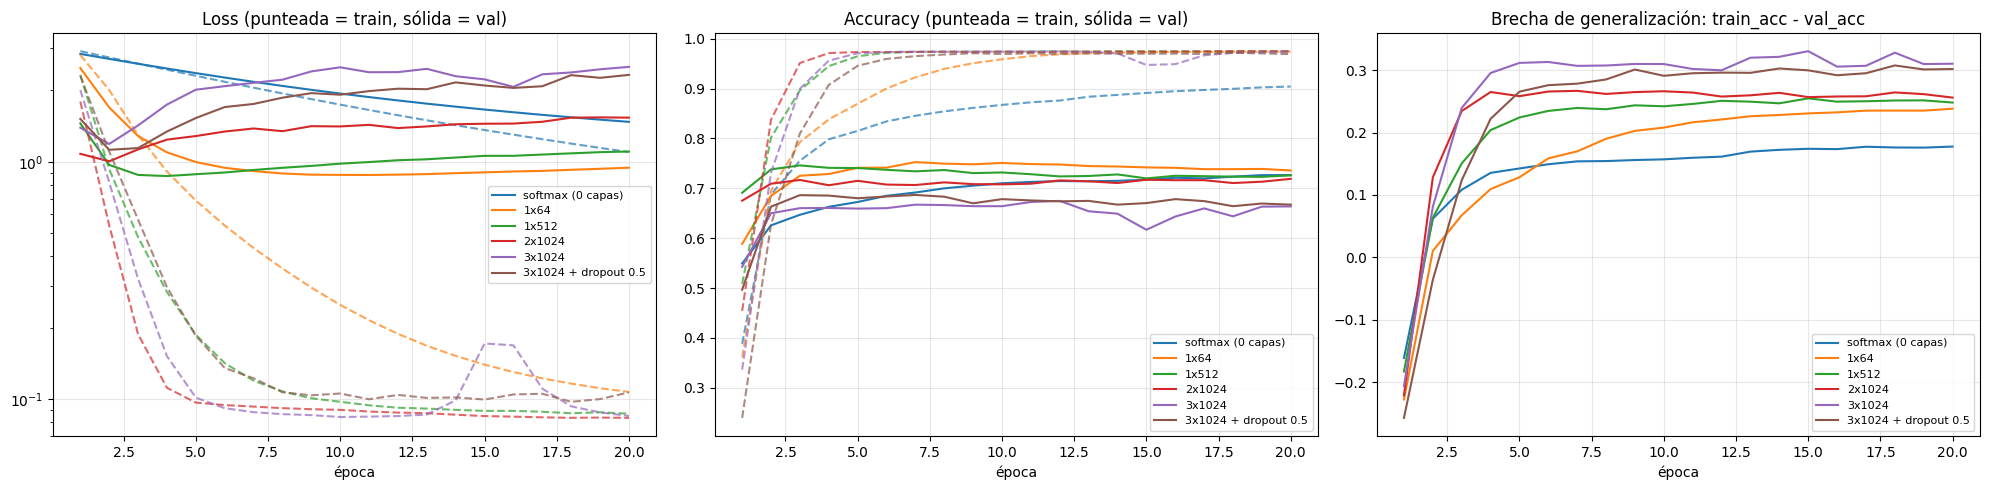

,modelo,parámetros,train_acc_final,train_loss_final,mejor_val_acc,época_mejor_val_acc,val_acc_final,época_min_val_loss,val_loss_final/min,brecha_final,s_por_época
0,softmax (0 capas),200020,0.9040,1.0988,0.7265,19,0.7265,20,1.0000,0.1775,0.4024
1,1x64,641364,0.9739,0.1073,0.7525,7,0.7357,11,1.0731,0.2382,0.6558
2,1x512,5130772,0.9740,0.0868,0.7459,3,0.7260,4,1.2686,0.2480,3.5751
3,2x1024,11311124,0.9749,0.0834,0.7190,20,0.7190,2,1.5272,0.2560,7.8683
4,3x1024,12360724,0.9739,0.0850,0.6748,12,0.6637,2,2.1119,0.3102,8.5941
5,3x1024 + dropout 0.5,12360724,0.9690,0.1068,0.6867,7,0.6673,2,2.0681,0.3017,8.6585


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for i, (name, r) in enumerate(overfit_results.items()):
    h, c = r["history"], f"C{i}"
    ep = np.arange(1, len(h["val_acc"]) + 1)
    axes[0].plot(ep, h["train_loss"], "--", color=c, alpha=0.7)
    axes[0].plot(ep, h["val_loss"], "-", color=c, label=name)
    axes[1].plot(ep, h["train_acc"], "--", color=c, alpha=0.7)
    axes[1].plot(ep, h["val_acc"], "-", color=c, label=name)
    axes[2].plot(ep, np.array(h["train_acc"]) - np.array(h["val_acc"]), color=c, label=name)
axes[0].set_yscale("log"); axes[0].set_title("Loss (punteada = train, sólida = val)")
axes[1].set_title("Accuracy (punteada = train, sólida = val)")
axes[2].set_title("Brecha de generalización: train_acc - val_acc")
for a in axes:
    a.set_xlabel("época"); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

rows = []
for name, r in overfit_results.items():
    h = r["history"]
    vl = np.array(h["val_loss"])
    rows.append({"modelo": name, "parámetros": r["n_params"], "train_acc_final": h["train_acc"][-1],
                 "train_loss_final": h["train_loss"][-1], "mejor_val_acc": max(h["val_acc"]),
                 "época_mejor_val_acc": int(np.argmax(h["val_acc"])) + 1, "val_acc_final": h["val_acc"][-1],
                 "época_min_val_loss": int(vl.argmin()) + 1, "val_loss_final/min": vl[-1] / vl.min(),
                 "brecha_final": h["train_acc"][-1] - h["val_acc"][-1], "s_por_época": np.mean(h["epoch_time"])})
df_over = pd.DataFrame(rows)
display(df_over.round(4))

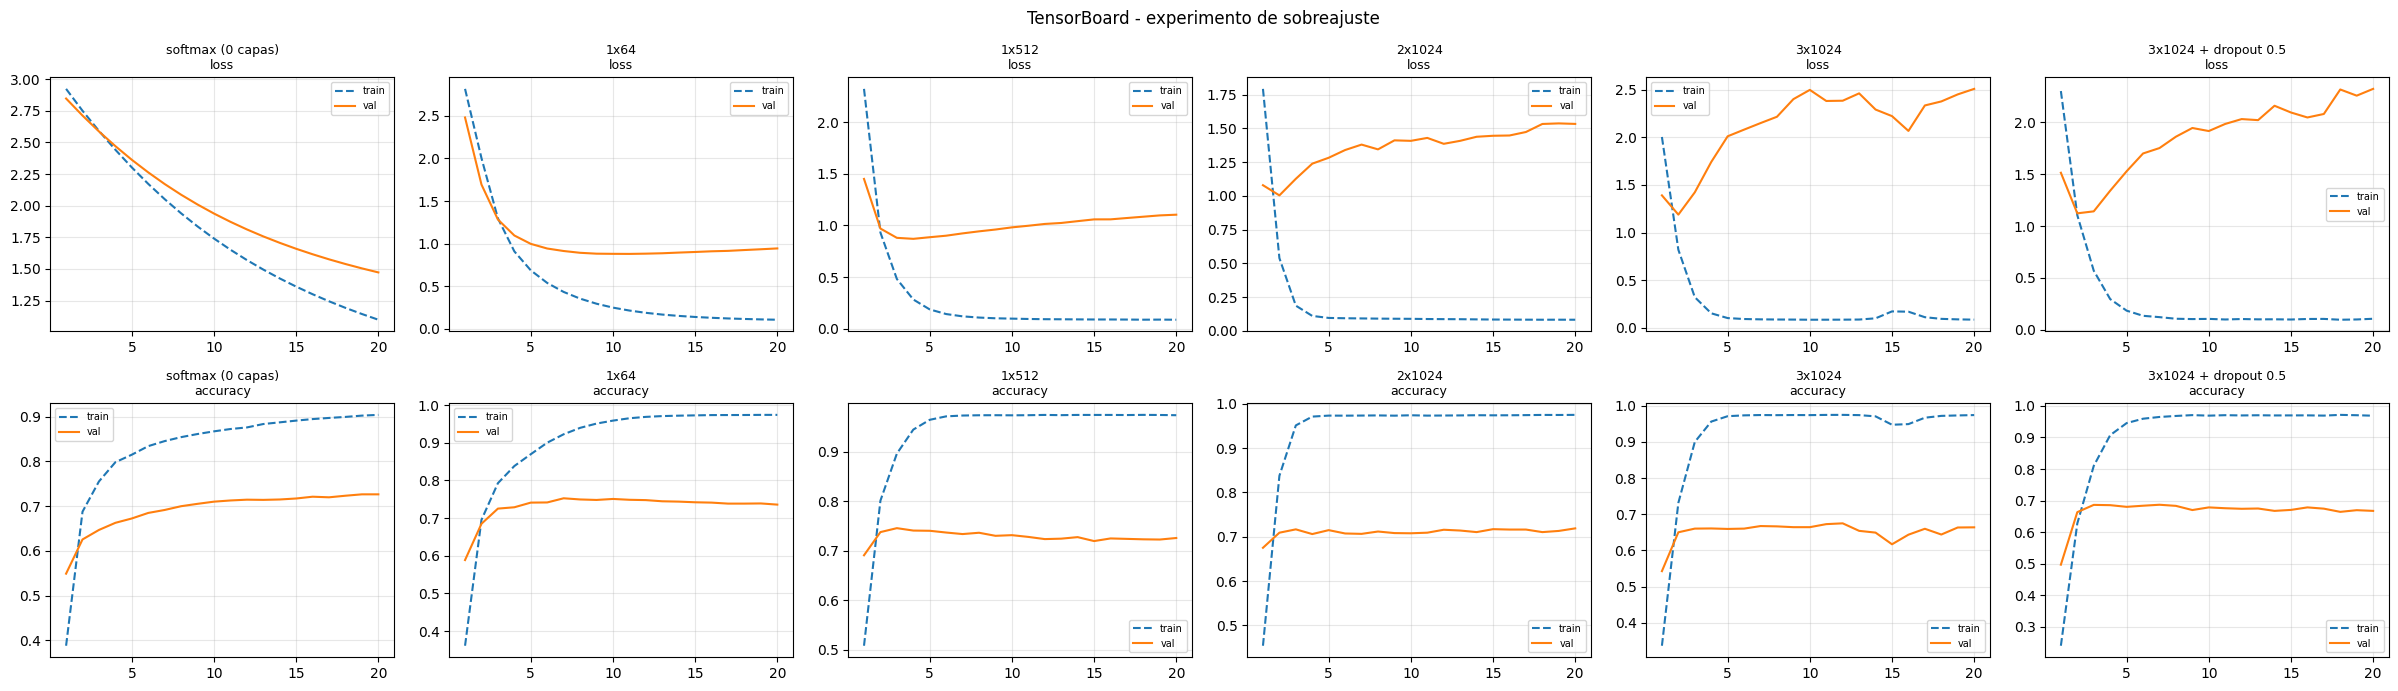

In [28]:
# Las curvas de TensorBoard del experimento de sobreajuste, como imagen estática (para GitHub)
nombres = list(overfit_results)
fig, axes = plt.subplots(2, len(nombres), figsize=(4 * len(nombres), 7), squeeze=False)
for j, name in enumerate(nombres):
    curvas = leer_scalars_tensorboard(f"runs/overfit/{name.replace(' ', '_')}")
    for i, g in enumerate(["loss", "accuracy"]):
        for split in ["train", "val"]:
            if f"{g}_{split}" in curvas:
                x, y = curvas[f"{g}_{split}"]
                axes[i, j].plot(x, y, "--" if split == "train" else "-", label=split)
        axes[i, j].set_title(f"{name}\n{g}", fontsize=9); axes[i, j].grid(alpha=0.3); axes[i, j].legend(fontsize=7)
plt.suptitle("TensorBoard - experimento de sobreajuste"); plt.tight_layout(); plt.show()

### Análisis del experimento de sobreajuste

| Modelo | Parámetros | Mejor val_acc (época) | Época de val_loss mínima | val_loss final / mínima | Brecha final | s/época |
|---|---|---|---|---|---|---|
| softmax (0 capas) | 0,2 M | 0.7265 (19) | 20 | 1.00 | 0.18 | 0.4 |
| 1×64 | 0,64 M | **0.7525** (7) | 11 | 1.07 | 0.24 | 0.7 |
| 1×512 | 5,1 M | 0.7459 (3) | 4 | 1.27 | 0.25 | 3.6 |
| 2×1024 | 11,3 M | 0.7190 (20) | 2 | 1.53 | 0.26 | 7.9 |
| **3×1024** | **12,4 M** | **0.6748** (12) | **2** | **2.11** | **0.31** | 8.6 |
| 3×1024 + dropout 0.5 | 12,4 M | 0.6867 (7) | 2 | 2.07 | 0.30 | 8.7 |

**El modelo sobreajustado es el de 3 capas de 1024 neuronas (12,4 M de parámetros).**
- Llega al techo de train_acc (0.974) en ~3 épocas y la train_loss baja a 0.085.
- Su **val_loss tiene el mínimo en la época 2 y después se duplica** (×2.11).
- La brecha train−val es la más grande (0.31).
- Su mejor val_acc (0.675) queda **casi 8 puntos por debajo** del MLP de 1×64.

Más capacidad, peor generalización: es la definición de sobreajuste.

**La tendencia es monótona con la capacidad.** A medida que crece el modelo:
- la val_loss alcanza su mínimo **antes** (época 20 → 11 → 4 → 2 → 2);
- la val_loss **sube más** después de ese mínimo (×1.00 → ×1.07 → ×1.27 → ×1.53 → ×2.11);
- la brecha crece (0.18 → 0.31).

En el gráfico de loss se ve claramente: las val_loss de 2×1024 y 3×1024 suben época tras época mientras su train_loss ya está en ~0.09. El 3×1024 muestra además inestabilidad (un salto de la train_loss cerca de la época 15).

**La train_acc no llega a 1** en ningún modelo: se plantan en ~0.974. Ese ~2,6% de documentos que ningún modelo logra acertar probablemente corresponde a documentos que quedan **vacíos** (o casi) tras el preprocesamiento: con un vector de ceros no hay información para clasificarlos. (No se midió en este notebook.) Por eso la señal de sobreajuste es la **val_loss**, no la train_acc.

**Loss vs accuracy.** En el 3×1024 la val_loss se duplica, pero la val_acc "sólo" pierde algunos puntos. El modelo se vuelve **sobreconfiado**: los documentos que clasifica mal los clasifica mal con probabilidad ≈ 1, y eso dispara la entropía cruzada aunque el argmax cambie poco.

**Dropout en el modelo grande.** Mejoró la val_acc apenas (+1,2 puntos: 0.675 → 0.687), pero **no frenó la suba de la val_loss** (×2.07 contra ×2.11). El dropout se aplica después de cada capa oculta, pero la memorización ocurre sobre todo en la **primera capa** ($10.000 \times 1024$ pesos conectados directamente a las palabras). Para un modelo así haría falta regularizar esa capa: *weight decay* (`AdamW`), dropout sobre la entrada o, simplemente, menos neuronas. En la búsqueda, el dropout 0.5 sí ayudó con 512 neuronas y lr chico, combinado con early stopping.

**1×64 fue el mejor modelo de todo el TP** (0.7525). Con **8 veces menos parámetros** que el mejor de Optuna (0.7508, 1×512) y **3 veces menos tiempo por época** (0,7 s contra 2,3 s), empata con él (la diferencia está muy dentro de ±0.009). La softmax, por su parte, con lr = 10⁻³ todavía estaba mejorando en la época 20 (0.7265, sin sobreajuste): converge más lento.

**Costo.** El tiempo por época crece con los parámetros, aunque menos que proporcionalmente: 62 veces más parámetros cuestan ~20 veces más tiempo, porque una parte del costo (cargar batches, overhead de Python) no depende del tamaño. Los modelos de 1024 neuronas tardaron ~8–9 s/época contra 0,4 s de la softmax, para dar **peor** resultado.

## 9. Regularización: L1, L2, L1+L2, Dropout y Batch Normalization (TP3)

En la sección 8 se vio que el MLP sobreajusta muy rápido: la val_loss del 1×512 tiene su mínimo en la época 4 y después sube, y el dropout por sí solo no alcanzó en el modelo grande, porque la memorización ocurre en la **primera capa** ($10.000\times512$ pesos conectados directamente a las palabras). Esta sección incorpora las técnicas de regularización vistas en clase como **hiperparámetros** del TP y analiza su efecto.

### Recordatorio teórico y recomendaciones de clase

| Técnica | Qué hace | Recomendaciones de clase | Qué esperamos observar |
|---|---|---|---|
| **L2 (Ridge)** | Suma $\frac{\lambda_2}{2}\sum w^2$ al costo → *weight decay*: $w \leftarrow (1-\eta\lambda_2)w - \eta\nabla J$. Equivale a MAP con prior **gaussiana** | λ en **escala log**; no regularizar los **bias**; datos preprocesados (TF-IDF ya está normalizado por documento) | pesos más chicos (histograma más angosto), menor brecha train–val, val_loss que no sube; λ grande → underfitting |
| **L1 (LASSO)** | Suma $\lambda_1 \sum \lvert w \rvert$ → gradiente **constante** $\lambda_1\,\text{sign}(w)$. Equivale a MAP con prior **Laplace** | λ en escala log | pesos **esparsos**: muchos ≈ 0 y unos pocos grandes → selección de palabras; se puede **podar** |
| **L1+L2 (Elastic Net)** | Ambas penalizaciones | combinar λ chicos | esparsidad de L1 + estabilidad de L2 |
| **Dropout** | En train apaga cada unidad con prob. $p$ y escala por $1/(1-p)$; en eval no apaga nada | $p\in[0.2, 0.5]$; red **grande**; **lr mayor** (10–100×) con decay; más épocas; opcionalmente dropout en la **entrada** con $p$ bajo | curvas de train **más ruidosas**, más épocas hasta el mejor punto, menor brecha |
| **Batch Normalization** | Normaliza la preactivación de cada unidad con media y varianza **del mini-batch**, luego $\gamma\hat z+\beta$ | `Linear(bias=False) → BN → activación`; permite **lr más altos**; no suele combinarse con dropout; en inferencia usa `running_mean/var` | convergencia más rápida y tolerancia a lr alto; algo de ruido extra (estadísticas por batch); **más tiempo por época** |

### Detalle importante: L1/L2 con **Adam**
Adam divide cada gradiente por $\sqrt{\hat v_t}$ (su magnitud histórica). Si se suma la penalización al costo, el término $\lambda w$ también queda normalizado, y en los pesos de **palabras poco frecuentes** (cuyo gradiente de la entropía cruzada es casi siempre 0) el término de regularización domina y Adam lo convierte en un paso de tamaño ≈ lr. Consecuencia: con Adam la penalización actúa **mucho más fuerte sobre las palabras raras** que sobre las frecuentes, y con L1 los pesos no llegan a 0 exacto sino que **oscilan alrededor de 0 con amplitud ≈ lr**. Por eso para medir esparsidad usamos un **umbral** y una prueba de **poda**. (Esta es la motivación de **AdamW**, que desacopla el weight decay; lo comparamos al final del experimento.)

### Cambios en el código
1. `RegMLP`: igual que `MLP` más `input_dropout` (dropout sobre las palabras, la capa donde ocurre la memorización) y `batchnorm` (`Linear(bias=False) → BatchNorm1d → activación`).
2. `penalizacion_pesos`: L1 y/o L2 **sólo sobre los pesos** de las capas `Linear` (no sobre bias ni sobre γ, β de BN).
3. `train_model_reg`: el `train_model` de antes, con:
   - la penalización sumada a la loss;
   - la **loss de cada batch** guardada (para medir el ruido de las curvas);
   - train_loss y train_acc medidas también en **modo eval** sobre un subconjunto fijo del train (con dropout la loss de entrenamiento se calcula con unidades apagadas y no es comparable con la de validación);
   - estadísticas de los **pesos de la primera capa** por época: $\overline{|w|}$, $\max|w|$ y fracción de pesos casi nulos;
   - el **learning rate** de cada época (para cuando hay scheduler).

In [29]:
class RegMLP(nn.Module):
    """MLP con regularización configurable:
    [Dropout(entrada)] -> [Linear -> (BatchNorm) -> activación -> (Dropout)] x n -> Linear"""

    def __init__(self, input_dim, hidden_sizes, num_classes, activation="relu", dropout=0.0,
                 input_dropout=0.0, batchnorm=False):
        super().__init__()
        layers, prev = [], input_dim
        if input_dropout > 0:
            layers.append(nn.Dropout(input_dropout))            # apaga palabras al azar (sólo en train)
        for h in hidden_sizes:
            layers.append(nn.Linear(prev, h, bias=not batchnorm))  # con BN el bias sobra: lo reemplaza β
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))                # normaliza ANTES de la activación
            layers.append(ACTIVATIONS[activation]())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def penalizacion_pesos(model, l1=0.0, l2=0.0):
    """λ1·Σ|w| + (λ2/2)·Σw² sobre los PESOS de las capas Linear (ni bias ni parámetros de BN)."""
    pen = torch.zeros((), device=next(model.parameters()).device)
    if l1 == 0 and l2 == 0:
        return pen
    for m in model.modules():
        if isinstance(m, nn.Linear):
            if l1 > 0:
                pen = pen + l1 * m.weight.abs().sum()
            if l2 > 0:
                pen = pen + 0.5 * l2 * m.weight.pow(2).sum()
    return pen


UMBRAL_W = 1e-3   # |w| < UMBRAL_W cuenta como "peso casi nulo" (la inicialización es U(±0.01) con 10.000 entradas)


def primera_capa(model):
    return next(m for m in model.modules() if isinstance(m, nn.Linear))


@torch.no_grad()
def stats_pesos(model, umbral=UMBRAL_W):
    W = primera_capa(model).weight.detach().abs()
    return {"w1_mean_abs": W.mean().item(), "w1_max_abs": W.max().item(),
            "w1_frac_chicos": (W < umbral).float().mean().item()}


@torch.no_grad()
def evaluar(model, loader, criterion):
    model.eval()
    loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss += criterion(logits, yb).item() * xb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += xb.size(0)
    return loss / total, correct / total


def train_model_reg(model, train_loader, val_loader, optimizer, epochs, l1=0.0, l2=0.0, scheduler=None,
                    train_eval_loader=None, writer=None, run_name="reg", trial=None, patience=None, verbose=False):
    """Como train_model, más: penalización L1/L2, loss por batch, métricas de train en modo eval,
    estadísticas de pesos de la primera capa y lr por época."""
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    h = {k: [] for k in ["train_loss", "train_acc", "train_loss_eval", "train_acc_eval", "val_loss", "val_acc",
                         "epoch_time", "lr", "penalty", "w1_mean_abs", "w1_max_abs", "w1_frac_chicos", "batch_loss"]}
    h.update(pruned=False, stop_reason="max_epochs")
    w0 = stats_pesos(model)
    h["w1_init"] = w0
    best_acc, sin_mejora = -1.0, 0

    for epoch in range(epochs):
        _sync(); t0 = time.perf_counter()
        model.train()
        run_loss, run_pen, correct, total = 0.0, 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            ce = criterion(logits, yb)
            pen = penalizacion_pesos(model, l1, l2)
            (ce + pen).backward()
            optimizer.step()
            h["batch_loss"].append(ce.item())                 # sólo la entropía cruzada (comparable entre modelos)
            run_loss += ce.item() * xb.size(0); run_pen += pen.item() * xb.size(0)
            correct += (logits.argmax(1) == yb).sum().item(); total += xb.size(0)
        train_loss, train_acc = run_loss / total, correct / total
        val_loss, val_acc = evaluar(model, val_loader, criterion)
        _sync(); dt = time.perf_counter() - t0                 # el tiempo NO incluye la evaluación extra de abajo

        tr_loss_ev, tr_acc_ev = evaluar(model, train_eval_loader, criterion) if train_eval_loader else (np.nan, np.nan)
        lr_actual = optimizer.param_groups[0]["lr"]
        if scheduler is not None:
            scheduler.step(val_loss)                          # ReduceLROnPlateau sobre la val_loss
        sw = stats_pesos(model)
        for k, v in [("train_loss", train_loss), ("train_acc", train_acc), ("train_loss_eval", tr_loss_ev),
                     ("train_acc_eval", tr_acc_ev), ("val_loss", val_loss), ("val_acc", val_acc), ("epoch_time", dt),
                     ("lr", lr_actual), ("penalty", run_pen / total), *sw.items()]:
            h[k].append(float(v))

        if verbose:
            print(f"[{run_name}] ép {epoch+1:2d} | train {train_loss:.4f}/{train_acc:.4f} | val {val_loss:.4f}/{val_acc:.4f}"
                  f" | mean|w1| {sw['w1_mean_abs']:.2e} | lr {lr_actual:.1e} | {dt:.1f}s")
        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
            writer.add_scalar("pesos/mean_abs_w1", sw["w1_mean_abs"], epoch)
            writer.add_scalar("lr", lr_actual, epoch)
        if mlflow.active_run() is not None:
            mlflow.log_metrics({"train_loss": train_loss, "val_loss": val_loss, "train_acc": train_acc,
                                "val_acc": val_acc, "epoch_time_s": dt, "lr": lr_actual, **sw}, step=epoch)

        if not math.isfinite(train_loss):
            h["stop_reason"] = "diverged"; break
        if trial is not None:
            trial.report(val_acc, step=epoch)
            if trial.should_prune():
                h["pruned"], h["stop_reason"] = True, "pruned"; break
        if val_acc > best_acc:
            best_acc, sin_mejora = val_acc, 0
        else:
            sin_mejora += 1
        if patience is not None and sin_mejora >= patience:
            h["stop_reason"] = "early_stopping"; break
    return h


def ruido_batches(batch_losses, ventana=25, relativo=False):
    """Ruido de la curva de entrenamiento: desvío de la loss de cada batch respecto de su media móvil,
    medido en la 2da mitad del entrenamiento. Absoluto (en unidades de loss) o relativo a la media móvil.
    Ojo: el relativo se infla cuando la loss tiende a 0 (modelos que memorizan el train)."""
    x = np.asarray(batch_losses, float)
    x = x[len(x) // 2:]
    ventana = int(min(ventana, max(3, len(x) // 5)))
    suave = np.convolve(x, np.ones(ventana) / ventana, mode="valid")
    resid = x[ventana // 2: ventana // 2 + len(suave)] - suave
    return float(np.std(resid / suave)) if relativo else float(np.std(resid))


# Sanity checks
_m = RegMLP(50, [32], NUM_CLASSES, dropout=0.5, input_dropout=0.2, batchnorm=True)
print(_m)
assert _m(torch.randn(8, 50)).shape == (8, NUM_CLASSES)
_ref = torch.tensor(0.0)
for m_ in _m.modules():
    if isinstance(m_, nn.Linear): _ref = _ref + 1e-3 * m_.weight.abs().sum()
assert torch.isclose(penalizacion_pesos(_m, l1=1e-3), _ref)
print("Parámetros entrenables:", count_params(_m),
      "| no entrenables (running_mean/var de BN):", sum(b.numel() for n, b in _m.named_buffers() if "running" in n))

RegMLP(
  (net): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=50, out_features=32, bias=False)
    (2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.5, inplace=False)
    (5): Linear(in_features=32, out_features=20, bias=True)
  )
)
Parámetros entrenables: 2324 | no entrenables (running_mean/var de BN): 64


### 9.1 Experimento controlado: una técnica por vez

Para aislar el efecto de cada técnica se fija todo lo demás:
- **Representación**: la mejor de la búsqueda (stem, unigramas, 10.000 features).
- **Arquitectura**: **1×512 ReLU**, que en la sección 8 sobreajustó (val_loss mínima en la época 4, luego ×1.27). Como recomienda la clase para dropout, se regulariza una red **grande** en vez de achicarla.
- **Optimizador**: Adam, lr = 10⁻³, batch 64, misma semilla (igual que el experimento de sobreajuste). **Sin early stopping**: se entrenan todas las épocas para ver la curva completa.

| Grupo | Configuraciones | Justificación |
|---|---|---|
| Base | sin regularización | referencia |
| L2 | λ₂ ∈ {10⁻⁵, 10⁻⁴, 10⁻³} | escala log: de "casi sin efecto" a "underfitting" |
| L1 | λ₁ ∈ {10⁻⁶, 10⁻⁵, 10⁻⁴} | ídem; L1 suma $\sum\lvert w \rvert$, que con 5 M de pesos es mucho mayor que $\frac12\sum w^2$, por eso usa λ más chicos |
| L1+L2 | (λ₁, λ₂) = (10⁻⁶, 10⁻⁴) y (10⁻⁵, 10⁻³) | combinaciones de valores intermedios |
| Dropout | 0.2, 0.5, entrada 0.2 + 0.5, y 0.5 con **lr ×10** (10⁻²) + `ReduceLROnPlateau` | rango 20–50%, dropout en la entrada (donde está la memorización), y la recomendación de lr alto con decay |
| BatchNorm | BN con lr 10⁻³, BN con lr 10⁻², base con lr 10⁻² (control), BN + dropout 0.5 | BN permite lr altos; el control sin BN muestra qué pasa sin él; BN+dropout para ver si se interfieren |
| AdamW | weight decay desacoplado 10⁻² | comparación con L2 "acoplado" dentro de Adam |

Son 18 entrenamientos de 15 épocas cada uno (21,2 minutos en total).

In [30]:
EPOCHS_REG = 15
REG_HIDDEN = [512]
REG_LR = 1e-3
REG_BATCH = 64

# nombre, grupo, kwargs (l1, l2, dropout, input_dropout, batchnorm, lr, scheduler, adamw_wd)
REG_CONFIGS = [
    ("base",                  "base",     {}),
    ("L2 1e-5",               "L2",       {"l2": 1e-5}),
    ("L2 1e-4",               "L2",       {"l2": 1e-4}),
    ("L2 1e-3",               "L2",       {"l2": 1e-3}),
    ("L1 1e-6",               "L1",       {"l1": 1e-6}),
    ("L1 1e-5",               "L1",       {"l1": 1e-5}),
    ("L1 1e-4",               "L1",       {"l1": 1e-4}),
    ("L1+L2 1e-6/1e-4",       "L1+L2",    {"l1": 1e-6, "l2": 1e-4}),
    ("L1+L2 1e-5/1e-3",       "L1+L2",    {"l1": 1e-5, "l2": 1e-3}),
    ("drop 0.2",              "Dropout",  {"dropout": 0.2}),
    ("drop 0.5",              "Dropout",  {"dropout": 0.5}),
    ("drop in0.2 + 0.5",      "Dropout",  {"dropout": 0.5, "input_dropout": 0.2}),
    ("drop 0.5 lr1e-2+decay", "Dropout",  {"dropout": 0.5, "lr": 1e-2, "scheduler": True}),
    ("BN lr1e-3",             "BatchNorm", {"batchnorm": True}),
    ("BN lr1e-2",             "BatchNorm", {"batchnorm": True, "lr": 1e-2}),
    ("base lr1e-2",           "BatchNorm", {"lr": 1e-2}),
    ("BN + drop 0.5",         "BatchNorm", {"batchnorm": True, "dropout": 0.5}),
    ("AdamW wd 1e-2",         "AdamW",    {"adamw_wd": 1e-2}),
]

X_tr_r, X_val_r, _ = get_representation(bp["remove_stopwords"], bp["normalization"], BEST_NGRAM,
                                         bp["max_features"], bp["min_df"])
train_ds_r, val_ds_r = to_tensor_dataset(X_tr_r, y_tr), to_tensor_dataset(X_val_r, y_val)
_g = torch.Generator().manual_seed(SEED)
idx_eval = torch.randperm(len(train_ds_r), generator=_g)[:2000]       # subconjunto fijo del train para medir en modo eval
train_eval_ds_r = torch.utils.data.Subset(train_ds_r, idx_eval.tolist())

reg_results = {}
mlflow.end_run()
mlflow.set_experiment("mlp_20newsgroups_regularizacion")
t_reg = time.perf_counter()
for name, grupo, kw in REG_CONFIGS:
    torch.manual_seed(SEED)
    m = RegMLP(X_tr_r.shape[1], REG_HIDDEN, NUM_CLASSES, activation="relu", dropout=kw.get("dropout", 0.0),
               input_dropout=kw.get("input_dropout", 0.0), batchnorm=kw.get("batchnorm", False))
    lr = kw.get("lr", REG_LR)
    if "adamw_wd" in kw:
        # AdamW: weight decay desacoplado, sólo sobre los pesos (no sobre bias)
        decay = [p for n, p in m.named_parameters() if n.endswith("weight")]
        no_decay = [p for n, p in m.named_parameters() if not n.endswith("weight")]
        opt_r = optim.AdamW([{"params": decay, "weight_decay": kw["adamw_wd"]},
                             {"params": no_decay, "weight_decay": 0.0}], lr=lr)
    else:
        opt_r = optim.Adam(m.parameters(), lr=lr)
    sched = optim.lr_scheduler.ReduceLROnPlateau(opt_r, factor=0.3, patience=1) if kw.get("scheduler") else None
    tl = DataLoader(train_ds_r, batch_size=REG_BATCH, shuffle=True)
    vl = DataLoader(val_ds_r, batch_size=1024, shuffle=False)
    tel = DataLoader(train_eval_ds_r, batch_size=1024, shuffle=False)
    w = SummaryWriter(log_dir=f"runs/regularizacion/{name.replace(' ', '_').replace('/', '-').replace('+', 'mas')}")
    with mlflow.start_run(run_name=name):
        mlflow.log_params({"grupo": grupo, "hidden": str(REG_HIDDEN), "lr": lr, **{k: v for k, v in kw.items() if k != "lr"}})
        h = train_model_reg(m, tl, vl, opt_r, EPOCHS_REG, l1=kw.get("l1", 0.0), l2=kw.get("l2", 0.0),
                            scheduler=sched, train_eval_loader=tel, writer=w, run_name=name)
    w.close()
    reg_results[name] = {"grupo": grupo, "kw": kw, "lr": lr, "history": h, "n_params": count_params(m),
                         "model": m.cpu()}
    print(f"{name:22s} | best val_acc {max(h['val_acc']):.4f} (ép {int(np.argmax(h['val_acc']))+1:2d}) "
          f"| val_loss mín {min(h['val_loss']):.3f} (ép {int(np.argmin(h['val_loss']))+1:2d}) final {h['val_loss'][-1]:.3f} "
          f"| mean|w1| {h['w1_mean_abs'][-1]:.2e} | {np.mean(h['epoch_time']):.2f} s/ép")
    del opt_r
print(f"\nTiempo total del experimento: {(time.perf_counter() - t_reg)/60:.1f} min")

2026/11/09 12:20:12 INFO mlflow.tracking.fluent: Experiment with name 'mlp_20newsgroups_regularizacion' does not exist. Creating a new experiment.


base                   | best val_acc 0.7490 (ép  3) | val_loss mín 0.873 (ép  4) final 1.065 | mean|w1| 4.82e-02 | 3.74 s/ép
L2 1e-5                | best val_acc 0.7455 (ép  3) | val_loss mín 0.881 (ép  4) final 1.052 | mean|w1| 2.74e-02 | 5.43 s/ép
L2 1e-4                | best val_acc 0.7357 (ép  3) | val_loss mín 0.941 (ép  4) final 1.046 | mean|w1| 1.52e-02 | 5.42 s/ép
L2 1e-3                | best val_acc 0.7110 (ép  9) | val_loss mín 1.102 (ép 14) final 1.109 | mean|w1| 7.69e-03 | 5.52 s/ép
L1 1e-6                | best val_acc 0.7402 (ép  5) | val_loss mín 0.896 (ép  4) final 1.083 | mean|w1| 1.76e-02 | 5.04 s/ép
L1 1e-5                | best val_acc 0.7132 (ép  3) | val_loss mín 1.011 (ép  6) final 1.112 | mean|w1| 6.95e-03 | 5.06 s/ép
L1 1e-4                | best val_acc 0.6301 (ép 15) | val_loss mín 1.350 (ép 15) final 1.350 | mean|w1| 1.07e-03 | 5.00 s/ép
L1+L2 1e-6/1e-4        | best val_acc 0.7322 (ép  4) | val_loss mín 0.955 (ép  5) final 1.059 | mean|w1| 1.25e-02 | 6.

In [31]:
# Tabla resumen del experimento controlado
rows = []
for name, r in reg_results.items():
    h = r["history"]; vl = np.array(h["val_loss"])
    rows.append({
        "config": name, "grupo": r["grupo"], "lr": r["lr"],
        "mejor_val_acc": max(h["val_acc"]), "época_mejor": int(np.argmax(h["val_acc"])) + 1,
        "val_acc_final": h["val_acc"][-1],
        "val_loss_mín": vl.min(), "época_val_loss_mín": int(vl.argmin()) + 1, "val_loss_final/mín": vl[-1] / vl.min(),
        "brecha_acc_final (eval)": h["train_acc_eval"][-1] - h["val_acc"][-1],
        "mean|w1|": h["w1_mean_abs"][-1], "max|w1|": h["w1_max_abs"][-1],
        f"% |w1|<{UMBRAL_W:g}": 100 * h["w1_frac_chicos"][-1],
        "s/época": np.mean(h["epoch_time"]), "ruido_batch": ruido_batches(h["batch_loss"]),
        "ruido_rel": ruido_batches(h["batch_loss"], relativo=True),
    })
df_reg = pd.DataFrame(rows)
base_t = df_reg.loc[df_reg["config"] == "base", "s/época"].iloc[0]
df_reg["tiempo_rel"] = df_reg["s/época"] / base_t
display(df_reg.round({"lr": 4, "mejor_val_acc": 4, "val_acc_final": 4, "val_loss_mín": 3, "val_loss_final/mín": 2,
                      "brecha_acc_final (eval)": 3, "mean|w1|": 6, "max|w1|": 3, f"% |w1|<{UMBRAL_W:g}": 1,
                      "s/época": 2, "ruido_batch": 3, "ruido_rel": 3, "tiempo_rel": 2}))
w_init = reg_results["base"]["history"]["w1_init"]
print(f"Pesos de la 1ra capa al inicializar: mean|w1| = {w_init['w1_mean_abs']:.2e}, "
      f"max|w1| = {w_init['w1_max_abs']:.3f}, % < {UMBRAL_W:g} = {100*w_init['w1_frac_chicos']:.1f}%")

,config,grupo,lr,mejor_val_acc,época_mejor,val_acc_final,val_loss_mín,época_val_loss_mín,val_loss_final/mín,brecha_acc_final (eval),mean|w1|,max|w1|,% |w1|<0.001,s/época,ruido_batch,ruido_rel,tiempo_rel
0,base,base,0.001,0.7490,3,0.7274,0.873,4,1.22,0.246,0.048177,0.657,1.2,3.74,0.060,0.636,1.00
1,L2 1e-5,L2,0.001,0.7455,3,0.7167,0.881,4,1.19,0.257,0.027379,0.403,12.0,5.43,0.059,0.581,1.45
2,L2 1e-4,L2,0.001,0.7357,3,0.7004,0.941,4,1.11,0.273,0.015241,0.324,22.7,5.42,0.060,0.358,1.45
3,L2 1e-3,L2,0.001,0.7110,9,0.7057,1.102,14,1.01,0.232,0.007695,0.276,34.8,5.52,0.094,0.130,1.47
4,L1 1e-6,L1,0.001,0.7402,5,0.7132,0.896,4,1.21,0.260,0.017560,0.547,55.9,5.04,0.059,0.540,1.35
5,L1 1e-5,L1,0.001,0.7132,3,0.6871,1.011,6,1.10,0.286,0.006946,0.605,69.5,5.06,0.063,0.268,1.35
6,L1 1e-4,L1,0.001,0.6301,15,0.6301,1.350,15,1.00,0.086,0.001067,1.515,94.3,5.00,0.121,0.089,1.34
7,L1+L2 1e-6/1e-4,L1+L2,0.001,0.7322,4,0.6933,0.955,5,1.11,0.280,0.012524,0.348,36.4,6.81,0.060,0.331,1.82
8,L1+L2 1e-5/1e-3,L1+L2,0.001,0.6991,15,0.6991,1.165,14,1.01,0.202,0.004929,0.394,55.3,6.82,0.102,0.114,1.82
9,drop 0.2,Dropout,0.001,0.7486,3,0.7234,0.870,5,1.19,0.250,0.048249,0.629,1.3,3.66,0.059,0.614,0.98


Pesos de la 1ra capa al inicializar: mean|w1| = 5.00e-03, max|w1| = 0.010, % < 0.001 = 10.0%


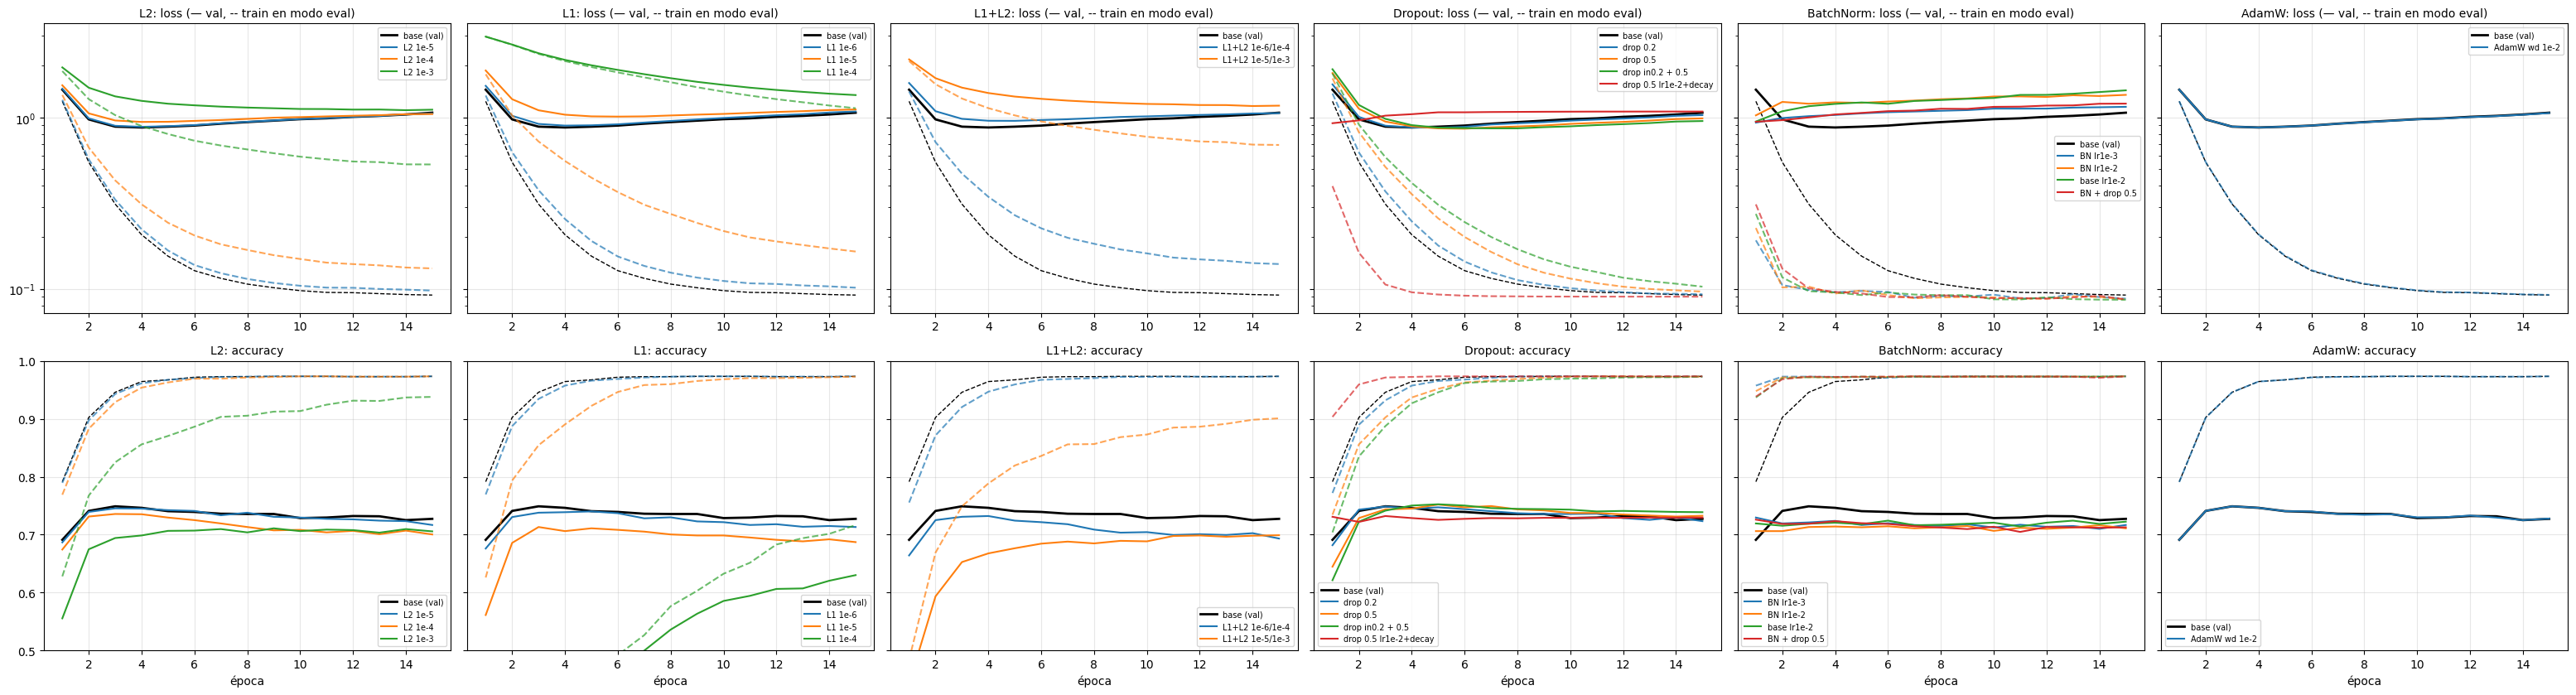

In [32]:
# Curvas de aprendizaje por grupo (cada panel incluye la base como referencia)
grupos = ["L2", "L1", "L1+L2", "Dropout", "BatchNorm", "AdamW"]
fig, axes = plt.subplots(2, len(grupos), figsize=(5.2 * len(grupos), 8.5), sharey="row")
hb = reg_results["base"]["history"]; ep = np.arange(1, len(hb["val_loss"]) + 1)
for j, g in enumerate(grupos):
    ax_l, ax_a = axes[0, j], axes[1, j]
    ax_l.plot(ep, hb["val_loss"], "k-", lw=2, label="base (val)"); ax_l.plot(ep, hb["train_loss_eval"], "k--", lw=1)
    ax_a.plot(ep, hb["val_acc"], "k-", lw=2, label="base (val)"); ax_a.plot(ep, hb["train_acc_eval"], "k--", lw=1)
    for i, (name, r) in enumerate([(n, r) for n, r in reg_results.items() if r["grupo"] == g]):
        h = r["history"]; e = np.arange(1, len(h["val_loss"]) + 1); c = f"C{i}"
        ax_l.plot(e, h["val_loss"], "-", c=c, label=name); ax_l.plot(e, h["train_loss_eval"], "--", c=c, alpha=.7)
        ax_a.plot(e, h["val_acc"], "-", c=c, label=name); ax_a.plot(e, h["train_acc_eval"], "--", c=c, alpha=.7)
    ax_l.set_title(f"{g}: loss (— val, -- train en modo eval)", fontsize=10); ax_l.set_yscale("log")
    ax_a.set_title(f"{g}: accuracy", fontsize=10); ax_a.set_xlabel("época")
    for a in (ax_l, ax_a): a.grid(alpha=.3); a.legend(fontsize=7)
axes[1, 0].set_ylim(0.5, 1.0)
plt.tight_layout(); plt.show()

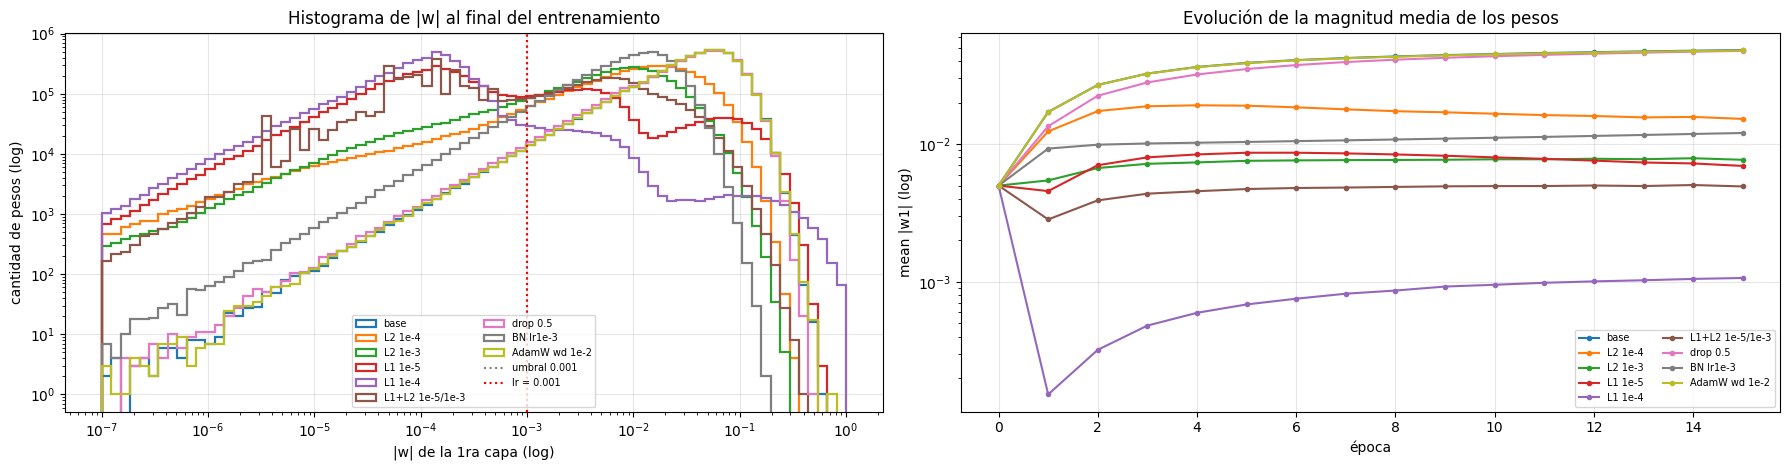

base       | palabras con pesos más grandes: mac, hockey, approv, isra, nsa, playoff, encrypt, bike, firearm, arab, weapon, powerbook, escrow, xterm, bobbi
           | palabras cuyo peso máx < 0.001: 0 de 10000
L1 1e-4    | palabras con pesos más grandes: space, bike, gun, window, car, hockey, orbit, govern, team, encrypt, graphic, weapon, nasa, file, drive
           | palabras cuyo peso máx < 0.001: 2737 de 10000


In [33]:
# Valores absolutos de los pesos de la primera capa
mostrar = ["base", "L2 1e-4", "L2 1e-3", "L1 1e-5", "L1 1e-4", "L1+L2 1e-5/1e-3", "drop 0.5", "BN lr1e-3", "AdamW wd 1e-2"]
mostrar = [n for n in mostrar if n in reg_results]
fig, axes = plt.subplots(1, 2, figsize=(18, 4.8))
bins = np.logspace(-7, 0, 80)
for i, name in enumerate(mostrar):
    W = primera_capa(reg_results[name]["model"]).weight.detach().abs().numpy().ravel()
    axes[0].hist(W + 1e-12, bins=bins, histtype="step", lw=1.6, label=name, color=f"C{i}")
axes[0].axvline(UMBRAL_W, c="gray", ls=":", label=f"umbral {UMBRAL_W:g}")
axes[0].axvline(REG_LR, c="r", ls=":", label=f"lr = {REG_LR:g}")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set(xlabel="|w| de la 1ra capa (log)", ylabel="cantidad de pesos (log)", title="Histograma de |w| al final del entrenamiento")
axes[0].legend(fontsize=7, ncol=2)
for i, name in enumerate(mostrar):
    h = reg_results[name]["history"]
    axes[1].plot(np.r_[0, np.arange(1, len(h["w1_mean_abs"]) + 1)], [h["w1_init"]["w1_mean_abs"]] + h["w1_mean_abs"],
                 "-o", ms=3, label=name, color=f"C{i}")
axes[1].set_yscale("log"); axes[1].set(xlabel="época", ylabel="mean |w1| (log)", title="Evolución de la magnitud media de los pesos")
axes[1].legend(fontsize=7, ncol=2)
for a in axes: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

# Pesos más grandes por palabra: ¿qué palabras "sobreviven" con L1?
vocab_r = None
try:
    _txt, _ = preprocessed_cache[(bp["remove_stopwords"], bp["normalization"])]
    _, _, _vec = vectorize_data([_txt[i] for i in idx_tr], [_txt[i] for i in idx_val], BEST_NGRAM, bp["max_features"], bp["min_df"])
    vocab_r = np.array(_vec.get_feature_names_out())
except Exception as e:
    print("No se pudo recuperar el vocabulario:", e)
if vocab_r is not None:
    for name in ["base", "L1 1e-4"]:
        if name not in reg_results: continue
        W = primera_capa(reg_results[name]["model"]).weight.detach().abs().numpy()   # (512, n_palabras)
        importancia = W.max(axis=0)                                                   # peso máximo de cada palabra
        top = np.argsort(importancia)[::-1][:15]
        print(f"{name:10s} | palabras con pesos más grandes: {', '.join(vocab_r[top])}")
        print(f"{'':10s} | palabras cuyo peso máx < {UMBRAL_W:g}: {(importancia < UMBRAL_W).sum()} de {len(importancia)}")

In [34]:
# Prueba de poda: se ponen en 0 los pesos de la 1ra capa con |w| < umbral y se re-evalúa en validación
crit = nn.CrossEntropyLoss()
vl_cpu = DataLoader(val_ds_r, batch_size=1024, shuffle=False)
dev_bak = device
rows = []
for name in ["base", "L2 1e-3", "L1 1e-5", "L1 1e-4", "L1+L2 1e-5/1e-3"]:
    if name not in reg_results: continue
    m = reg_results[name]["model"].to(device)
    W = primera_capa(m).weight
    W_orig = W.detach().clone()
    base_acc = evaluar(m, vl_cpu, crit)[1]
    for umbral in [1e-4, 1e-3, 3e-3, 1e-2]:
        with torch.no_grad():
            W.copy_(torch.where(W_orig.abs() < umbral, torch.zeros_like(W_orig), W_orig))
        rows.append({"config": name, "umbral": umbral, "% pesos podados": 100 * (W_orig.abs() < umbral).float().mean().item(),
                     "val_acc sin podar": base_acc, "val_acc podada": evaluar(m, vl_cpu, crit)[1]})
    with torch.no_grad():
        W.copy_(W_orig)
    m.cpu()
df_poda = pd.DataFrame(rows)
display(df_poda.pivot(index="config", columns="umbral", values=["% pesos podados", "val_acc podada"]).round(3))

% pesos podados                         val_acc podada                     
umbral                   0.0001  0.0010  0.0030  0.0100         0.0001 0.0010 0.0030 0.0100
config                                                                                     
L1 1e-4                  45.234  94.312  97.042  99.203          0.630  0.631  0.630  0.629
L1 1e-5                  31.714  69.498  80.437  91.360          0.687  0.687  0.687  0.688
L1+L2 1e-5/1e-3          24.387  55.251  66.529  86.252          0.699  0.699  0.699  0.700
L2 1e-3                  24.324  34.845  47.137  73.401          0.706  0.706  0.705  0.702
base                      0.121   1.221   3.690  12.507          0.727  0.727  0.727  0.727

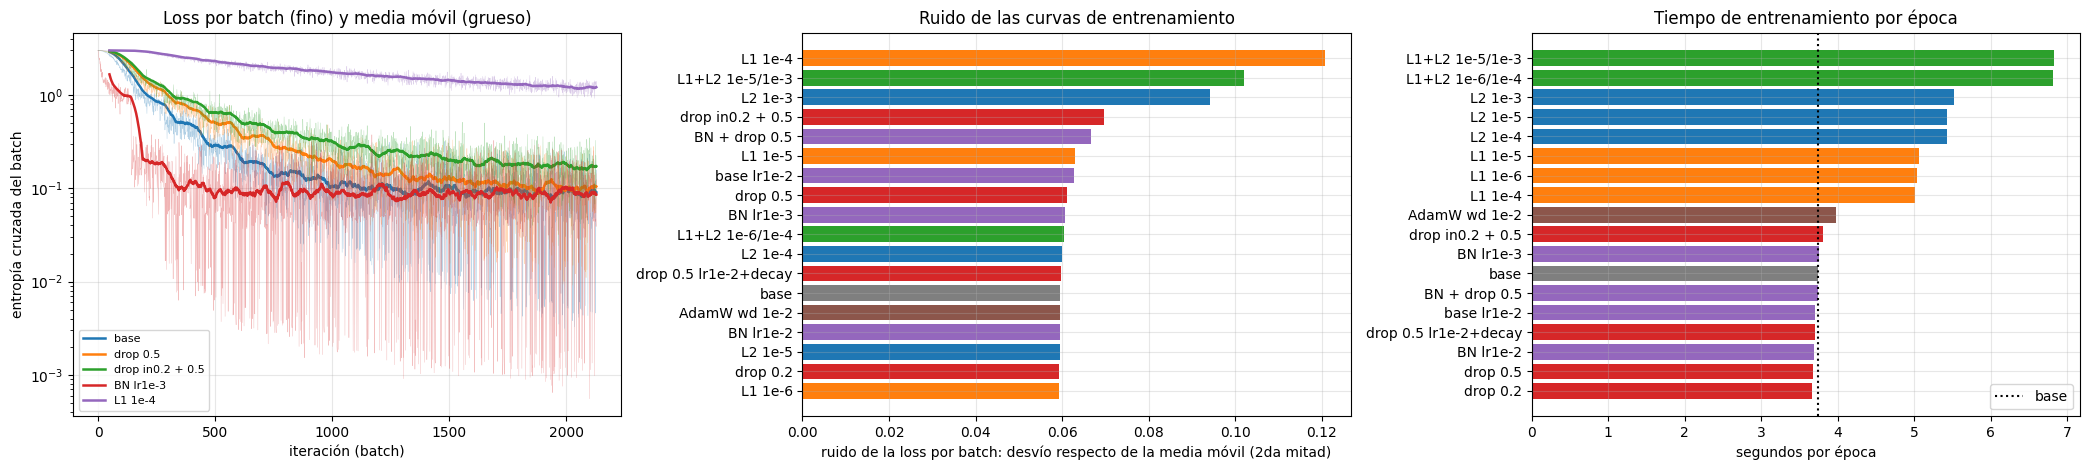

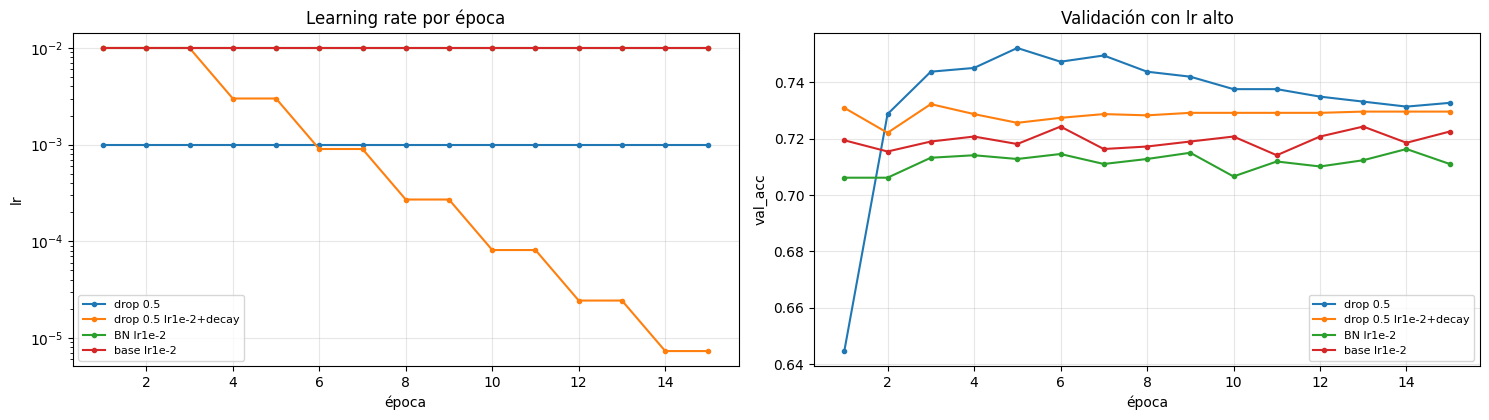

In [35]:
# Ruido de las curvas de entrenamiento (loss por batch) y tiempo por época
fig, axes = plt.subplots(1, 3, figsize=(21, 4.8))
ventana = 50
for i, name in enumerate(["base", "drop 0.5", "drop in0.2 + 0.5", "BN lr1e-3", "L1 1e-4"]):
    if name not in reg_results: continue
    bl = np.array(reg_results[name]["history"]["batch_loss"])
    it = np.arange(len(bl))
    axes[0].plot(it, bl, lw=.3, alpha=.35, color=f"C{i}")
    axes[0].plot(it[ventana - 1:], np.convolve(bl, np.ones(ventana) / ventana, mode="valid"), lw=1.8, color=f"C{i}", label=name)
axes[0].set_yscale("log"); axes[0].set(xlabel="iteración (batch)", ylabel="entropía cruzada del batch",
                                       title="Loss por batch (fino) y media móvil (grueso)")
axes[0].legend(fontsize=8)

orden = df_reg.sort_values("ruido_batch")
axes[1].barh(orden["config"], orden["ruido_batch"], color=[f"C{grupos.index(g) if g in grupos else 7}" for g in orden["grupo"]])
axes[1].set(xlabel="ruido de la loss por batch: desvío respecto de la media móvil (2da mitad)", title="Ruido de las curvas de entrenamiento")
orden = df_reg.sort_values("s/época")
axes[2].barh(orden["config"], orden["s/época"], color=[f"C{grupos.index(g) if g in grupos else 7}" for g in orden["grupo"]])
axes[2].axvline(base_t, c="k", ls=":", label="base")
axes[2].set(xlabel="segundos por época", title="Tiempo de entrenamiento por época"); axes[2].legend()
for a in axes: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

# Learning rate: dropout con lr alto + decay, y BN con lr alto
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
for i, name in enumerate(["drop 0.5", "drop 0.5 lr1e-2+decay", "BN lr1e-2", "base lr1e-2"]):
    if name not in reg_results: continue
    h = reg_results[name]["history"]; e = np.arange(1, len(h["val_loss"]) + 1)
    axes[0].plot(e, h["lr"], "-o", ms=3, label=name, color=f"C{i}")
    axes[1].plot(e, h["val_acc"], "-o", ms=3, label=name, color=f"C{i}")
axes[0].set_yscale("log"); axes[0].set(xlabel="época", ylabel="lr", title="Learning rate por época")
axes[1].set(xlabel="época", ylabel="val_acc", title="Validación con lr alto")
for a in axes: a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Análisis del experimento controlado

Los 18 entrenamientos tardaron **21,2 min**. Todos usan la misma red (1×512 ReLU), la misma inicialización y el mismo orden de batches, así que las diferencias se deben sólo a la técnica de regularización.

**Base (sin regularización).** Reproduce el 1×512 de la sección 8:
- la mejor val_acc (0.7490) llega en la **época 3**;
- la val_loss tiene su mínimo en la época 4 (0.873) y termina **×1.22** más alta;
- la brecha final train−val (medida en modo eval) es de 0.246.

Los pesos de la primera capa crecen sin freno: mean|w1| pasa de 0.0050 a **0.048** (×9,6) y max|w1| de 0.010 a **0.657**. Es la firma del sobreajuste vista en clase: con datos casi separables, la entropía cruzada siempre baja agrandando los pesos de las palabras que separan bien el train. El modelo se vuelve "seguro", y cuando se equivoca en validación lo hace con probabilidad ≈ 1, por eso la val_loss sube aunque la val_acc cambie poco.

#### L2

| λ₂ | mejor val_acc (época) | val_loss final/mín | mean\|w1\| | max\|w1\| | % \|w1\| < 10⁻³ |
|---|---|---|---|---|---|
| 0 (base) | 0.7490 (3) | 1.22 | 0.048 | 0.657 | 1,2 |
| 10⁻⁵ | 0.7455 (3) | 1.19 | 0.027 | 0.403 | 12,0 |
| 10⁻⁴ | 0.7357 (3) | 1.11 | 0.015 | 0.324 | 22,7 |
| 10⁻³ | 0.7110 (9) | **1.01** | 0.008 | 0.276 | 34,8 |

- **Pesos.** El término $\lambda_2 w$ del gradiente es un *weight decay*: cuanto mayor λ₂, más chicos los pesos. La magnitud media cae 6 veces y desaparece la cola de pesos grandes del histograma.
- **Sobreajuste en la loss.** La subida de la val_loss después del mínimo se reduce monótonamente (×1.22 → ×1.01). Con λ₂ = 10⁻³ la val_loss deja de subir y su mínimo se corre de la época 4 a la 14.
- **Accuracy.** La val_acc **baja** (0.749 → 0.711): la penalización agrega **bias**. Es el lado derecho de la curva "error vs λ" de clase: el modelo se vuelve demasiado simple antes de ganar en varianza.
- **Por qué cuesta tanto acá: L2 acoplado dentro de Adam.** Adam divide cada gradiente por $\sqrt{\hat v}$. En las palabras poco frecuentes el gradiente de la entropía cruzada es casi siempre 0, así que domina el término $\lambda_2 w$, y Adam lo convierte en un paso de tamaño ≈ lr. La penalización termina borrando sobre todo los pesos de las **palabras raras**, que en 20 Newsgroups son muy informativas (nombres de productos, jerga de cada foro).
- **La comparación con AdamW lo confirma.** AdamW, con un decaimiento **1000 veces mayor** (10⁻²), dejó los pesos casi iguales a la base (mean|w1| 0.0478 vs 0.0482, val_acc 0.7490 idéntica). En cambio, L2 = 10⁻⁵ acoplado los redujo un 43%. En AdamW cada paso multiplica los pesos por $(1-\eta\lambda) = 1-10^{-5}$: en las ~2.100 iteraciones del experimento (9.051 documentos / batch 64 × 15 épocas) son sólo un 2% de encogimiento. Para que AdamW tenga efecto hacen falta valores de weight decay mucho mayores; queda como mejora.

#### L1

| λ₁ | mejor val_acc (época) | val_loss final/mín | mean\|w1\| | max\|w1\| | % \|w1\| < 10⁻³ |
|---|---|---|---|---|---|
| 10⁻⁶ | 0.7402 (5) | 1.21 | 0.018 | 0.547 | 55,9 |
| 10⁻⁵ | 0.7132 (3) | 1.10 | 0.007 | 0.605 | 69,5 |
| 10⁻⁴ | 0.6301 (15) | 1.00 | 0.001 | **1.515** | **94,3** |

- **Esparsidad.** El gradiente de L1, $\lambda_1\,\text{sign}(w)$, es **igual para todos los pesos**. Los chicos son empujados a ≈ 0 y quedan ahí, y los útiles conservan valores grandes. Con λ₁ = 10⁻⁴ el 94% de los pesos de la primera capa queda por debajo de 10⁻³, mientras que **max|w1| (1.515) es más del doble que el de la base**. El histograma es **bimodal**: una masa de pesos casi nulos y una cola de pesos grandes. L2 nunca hace esto: encoge todo proporcionalmente.
- **Ceros "con Adam".** La masa de pesos eliminados se acumula alrededor de 10⁻⁴, un orden de magnitud por debajo del lr (línea roja del histograma). Como Adam normaliza el subgradiente, los pesos no llegan a 0 exacto: oscilan alrededor de 0 con pasos acotados por el lr. Por eso la esparsidad se mide con un umbral y con poda.
- **Poda.** Se pusieron en 0 los pesos de la primera capa menores a un umbral:

  | Modelo | % de pesos podados (umbral 10⁻²) | val_acc antes → después |
  |---|---|---|
  | base | 12,5% | 0.727 → 0.727 |
  | L2 10⁻³ | 73,4% | 0.706 → 0.702 |
  | L1 10⁻⁵ | **91,4%** | 0.687 → 0.688 |
  | L1 10⁻⁴ | **99,2%** | 0.630 → 0.629 |

  Con L1 se puede eliminar más del 90% de la primera capa **sin perder accuracy**. Los pesos que L1 llevó a ≈ 0 realmente no aportaban.
- **Selección de palabras (LASSO).** Con λ₁ = 10⁻⁴, **2.737 de las 10.000 palabras** quedan con todos sus pesos por debajo de 10⁻³: L1 las descartó. Las palabras con pesos más grandes también cambian:
  - en la base son términos muy específicos y a veces raros (*bobbi, escrow, xterm, powerbook, approv*), es decir, memorización de documentos puntuales;
  - con L1 son palabras temáticas frecuentes (*space, bike, gun, window, car, hockey, orbit, govern, nasa*).

  Es la selección de features del LASSO.
- **Costo.** La accuracy baja con λ₁ (0.740 → 0.713 → 0.630). Con 10⁻⁴ hay **underfitting** claro: brecha de sólo 0.086 y val_loss todavía bajando en la época 15.

#### L1+L2 (Elastic Net)
Las dos combinaciones quedan entre L1 y L2 en todo:
- 10⁻⁶/10⁻⁴: 0.7322, 36% de pesos < 10⁻³;
- 10⁻⁵/10⁻³: 0.6991, 55% de pesos < 10⁻³, val_loss sin subir (×1.01).

Combinan la esparsidad parcial de L1 con el encogimiento de L2, pero también suman el bias de las dos. Además son las más caras (ver tiempos).

#### Dropout

| Configuración | mejor val_acc (época) | val_acc final | val_loss final/mín (época del mín.) | brecha | max\|w1\| |
|---|---|---|---|---|---|
| base | 0.7490 (3) | 0.7274 | 1.22 (4) | 0.246 | 0.657 |
| dropout 0.2 | 0.7486 (3) | 0.7234 | 1.19 (5) | 0.250 | 0.629 |
| dropout 0.5 | 0.7521 (5) | 0.7327 | 1.15 (6) | 0.240 | 0.460 |
| **entrada 0.2 + 0.5** | **0.7525** (5) | **0.7388** | **1.10** (7) | **0.234** | 0.437 |
| 0.5 con lr 10⁻² + decay | 0.7322 (3) | 0.7296 | 1.17 (1) | 0.244 | 1.023 |

- **Fue la única técnica que no perdió accuracy.** Con dropout 0.5, y sobre todo con dropout en la entrada, se reduce la subida de la val_loss (×1.22 → ×1.10), baja la brecha y mejora la val_acc **final** (+1,1 puntos). La mejor val_acc (0.7525 vs 0.7490) es un empate dentro del error estándar (±0.009), pero el modelo se degrada mucho menos al seguir entrenando.
- **Dropout en la entrada.** Apagar el 20% de las palabras ataca directamente la memorización de la primera capa: el modelo no puede depender de una palabra puntual para reconocer un documento. Es lo que en la sección 8 faltaba con el dropout oculto solo.
- **Más épocas.** La mejor época pasa de 3 a 5 y el mínimo de val_loss de 4 a 7. Cada iteración entrena una sub-red distinta y las neuronas no pueden co-adaptarse, así que el aprendizaje es más lento, como se vio en clase.
- **Pesos.** Dropout no achica los pesos en promedio (mean|w1| ≈ 0.048–0.051, igual a la base), pero sí recorta los **extremos** (max|w1| 0.657 → 0.437). No es una penalización sobre los pesos: regulariza por ruido y por *ensemble* implícito.
- **Ruido.** El ruido absoluto de la loss por batch sube con dropout en la entrada (0.070 vs 0.060). En el gráfico de loss por batch, la curva con dropout queda más alta y oscila en toda la segunda mitad, mientras la de la base baja hasta ~0.1 (la de dropout queda en ~0.15–0.2): cada batch se evalúa con una máscara distinta y la red no llega a memorizar. El ruido *relativo* es menor que el de la base, pero sólo porque la loss de la base tiende a 0.
- **lr ×10 con decay: no funcionó con Adam.** La recomendación de clase (lr 10–100× mayor con dropout) viene del entrenamiento con SGD + momento, donde el ruido de dropout reduce el avance efectivo de cada paso. Adam ya normaliza el paso a ≈ lr por parámetro. Con lr = 10⁻², pesos que se inicializan en ±0.01 saltan del orden de su propio tamaño en cada iteración: la val_loss tiene su mínimo en la **época 1** y max|w1| sube a 1.02. El `ReduceLROnPlateau` bajó el lr desde la época 3 hasta ~10⁻⁵ y estabilizó la curva (val_acc plana en ~0.73), pero no recuperó lo perdido.

#### Batch Normalization

| Configuración | mejor val_acc (época) | val_loss final/mín (época del mín.) | mean\|w1\| | max\|w1\| |
|---|---|---|---|---|
| base lr 10⁻³ | 0.7490 (3) | 1.22 (4) | 0.048 | 0.657 |
| BN lr 10⁻³ | 0.7296 (**1**) | 1.24 (1) | 0.012 | 0.162 |
| base lr 10⁻² | 0.7243 (6) | **1.52** (1) | 0.116 | **2.450** |
| BN lr 10⁻² | 0.7163 (14) | 1.32 (1) | 0.092 | 1.263 |
| BN + dropout 0.5 | 0.7260 (1) | 1.28 (1) | 0.014 | 0.144 |

- **BN acelera, no regulariza.** Con BN el mejor punto llega en la **época 1** (la base necesita 3), y a partir de ahí la val_loss sube igual que sin BN (×1.24). Es lo visto en clase: BN es sobre todo una técnica para acelerar el entrenamiento. El ruido de las estadísticas por batch regulariza muy poco y no evita el sobreajuste.
- **Pesos.** Con BN los pesos de la primera capa casi no crecen (mean|w1| 0.012, max 0.162). BN normaliza la preactivación, así que la salida de la red es **invariante a la escala de W**: agrandar los pesos ya no hace al modelo más "seguro", y la entropía cruzada no tiene incentivo para hacerlo.
- **Learning rate.** Con lr = 10⁻², BN hizo el entrenamiento más estable que el control sin BN: la val_loss sube ×1.32 en lugar de ×1.52, y los pesos máximos son la mitad (1.26 vs 2.45). Es la propiedad de BN vista en clase: tolera lr más altos. Pero la accuracy no mejoró (0.716 vs 0.724) y ambas quedan por debajo de lr = 10⁻³: en este problema un lr alto no aporta nada.
- **BN + dropout.** No sumó nada (0.7260, también en la época 1), en línea con la recomendación de no combinarlos: dropout cambia la varianza de las activaciones entre entrenamiento e inferencia y las `running_var` de BN quedan desajustadas.
- **Tiempo.** BN prácticamente **no costó tiempo** (3,75 s/época vs 3,74). Normalizar 512 unidades es despreciable frente al producto de la primera capa (10.000 × 512).

#### Tiempos y ruido: resumen

| | s/época | relativo a la base |
|---|---|---|
| base, dropout, BN | 3,66–3,80 | 0,98–1,02 |
| AdamW | 3,97 | 1,06 |
| L1 o L2 | 5,00–5,52 | 1,34–1,47 |
| L1+L2 | 6,81–6,82 | **1,82** |

- **L1 y L2 son las únicas técnicas que encarecen el entrenamiento.** La penalización se calcula a mano como $\sum|w|$ o $\sum w^2$ sobre los 5,1 M de pesos **en cada batch**, y se le suma su backward; L1+L2 lo hace dos veces. AdamW obtiene un efecto de tipo L2 casi gratis, porque aplica el decaimiento dentro del paso del optimizador sin pasar por autograd.
- **Dropout y BN son gratis.** Generar máscaras y normalizar es barato frente al producto matricial de la primera capa.
- **Ruido.** El ruido absoluto de la loss por batch es ≈ 0.060 en casi todas las configuraciones. Sube con la regularización **fuerte** (L1 10⁻⁴: 0.121, L1+L2 10⁻⁵/10⁻³: 0.102, L2 10⁻³: 0.094) y con dropout en la entrada (0.070). En los modelos que no pueden memorizar, la loss de cada batch se mantiene alta y refleja la dificultad real de cada batch, en lugar de tender a 0 como en la base.

#### Conclusión del experimento
En 20 Newsgroups el sobreajuste se manifiesta sobre todo en la **loss** (sobreconfianza), mientras que la accuracy alcanza su máximo muy temprano.
- **L1 y L2** controlan la magnitud de los pesos y frenan la subida de la val_loss, pero a costa de accuracy (más bias). Con Adam ese costo se agrava porque la penalización castiga más a las palabras raras.
- **L1** además hace la red **esparsa**: se puede podar más del 90% de la primera capa sin perder nada.
- **Dropout**, en especial en la entrada, fue la mejor opción: menos sobreajuste, mejor val_acc final, más épocas útiles y sin costo de tiempo.
- **BatchNorm** acelera la convergencia y estabiliza lr altos, pero no regulariza.


### 9.2 Búsqueda con Optuna incluyendo la regularización

Se repite la búsqueda agregando como hiperparámetros:

| Hiperparámetro | Valores | Recomendación de clase que se aplica |
|---|---|---|
| `reg_type` | none, l1, l2, l1_l2 | |
| `lambda_l1` | 10⁻⁷ – 10⁻⁴ (log) | λ en escala logarítmica |
| `lambda_l2` | 10⁻⁶ – 10⁻² (log) | λ en escala logarítmica |
| `dropout` | 0, 0.2, 0.3, 0.5 | entre 20% y 50% |
| `input_dropout` | 0, 0.1, 0.2 | dropout en la entrada con tasa baja |
| `batchnorm` | False, True | `Linear(bias=False) → BN → activación` |
| `n_units` | 64, 128, 256, 512, 1024 | con dropout, usar una red más grande |
| lr | Adam/RMSprop: 10⁻⁴ – 3·10⁻² (log) | rango que permite los lr altos de dropout y BN |

Para que la comparación sea justa y la búsqueda no se diluya, se **fija el preprocesamiento** al de la primera búsqueda (stem, unigramas, 10.000 features, min_df = 2) y se descartan las opciones que ya demostraron no funcionar: **SGD** y **sigmoid/tanh** (sección 6). Se mantienen el pruning y el early stopping (con paciencia 4, porque dropout necesita más épocas).

In [36]:
N_TRIALS_REG = 40
PATIENCE_REG = 4
mlflow.end_run()
mlflow.set_experiment("mlp_20newsgroups_optuna_reg")


def objective_reg(trial):
    batch_size = trial.suggest_categorical("batch_size", [64, 128, 256])
    n_layers = trial.suggest_int("n_layers", 1, 2)
    hidden = [trial.suggest_categorical(f"n_units_l{i+1}", [64, 128, 256, 512, 1024]) for i in range(n_layers)]
    activation = trial.suggest_categorical("activation", ["relu", "leaky_relu", "gelu"])
    opt_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop"])
    lr = trial.suggest_float(f"lr_{opt_name}", 1e-4, 3e-2, log=True)

    # ---------- Regularización ----------
    reg_type = trial.suggest_categorical("reg_type", ["none", "l1", "l2", "l1_l2"])
    l1 = trial.suggest_float("lambda_l1", 1e-7, 1e-4, log=True) if reg_type in ("l1", "l1_l2") else 0.0
    l2 = trial.suggest_float("lambda_l2", 1e-6, 1e-2, log=True) if reg_type in ("l2", "l1_l2") else 0.0
    dropout = trial.suggest_categorical("dropout", [0.0, 0.2, 0.3, 0.5])
    input_dropout = trial.suggest_categorical("input_dropout", [0.0, 0.1, 0.2])
    batchnorm = trial.suggest_categorical("batchnorm", [False, True])

    torch.manual_seed(SEED)
    train_loader = DataLoader(train_ds_r, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds_r, batch_size=1024, shuffle=False)
    model = RegMLP(X_tr_r.shape[1], hidden, NUM_CLASSES, activation=activation, dropout=dropout,
                   input_dropout=input_dropout, batchnorm=batchnorm)
    optimizer = make_optimizer(opt_name, model.parameters(), lr, momentum=0.9 if opt_name == "rmsprop" else 0.0)

    with mlflow.start_run(run_name=f"trial_{trial.number}"):
        mlflow.log_params(trial.params)
        history = train_model_reg(model, train_loader, val_loader, optimizer, MAX_EPOCHS_SEARCH, l1=l1, l2=l2,
                                  trial=trial, patience=PATIENCE_REG)
        best_val = max(history["val_acc"])
        mlflow.log_metric("best_val_acc", best_val)
        mlflow.set_tag("stop_reason", history["stop_reason"])

    history.pop("batch_loss")   # no hace falta guardarla en el estudio (son miles de valores)
    for k, v in {"history": history, "hidden": hidden, "lr": lr, "l1": l1, "l2": l2, "n_params": count_params(model),
                 "best_epoch": int(np.argmax(history["val_acc"])) + 1,
                 "train_time": float(sum(history["epoch_time"]))}.items():
        trial.set_user_attr(k, v)
    print(f"trial {trial.number:3d} | {history['stop_reason']:14s} | ép={len(history['val_acc']):2d} | "
          f"best_val_acc={best_val:.4f} | {opt_name:7s} lr={lr:.1e} | {reg_type:5s} l1={l1:.0e} l2={l2:.0e} | "
          f"drop={dropout} in={input_dropout} BN={batchnorm} | {hidden} | {sum(history['epoch_time']):5.1f}s")
    if history["pruned"]:
        raise optuna.TrialPruned()
    return best_val


study_reg = optuna.create_study(direction="maximize", study_name="mlp_20newsgroups_reg",
                                sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=2))
t_s = time.perf_counter()
study_reg.optimize(objective_reg, n_trials=N_TRIALS_REG)
t_s = time.perf_counter() - t_s
n_pr = sum(t.state == optuna.trial.TrialState.PRUNED for t in study_reg.trials)
print(f"\nBúsqueda con regularización: {t_s/60:.1f} min | completos: {len(study_reg.trials) - n_pr} | podados: {n_pr}")
print(f"Mejor val_acc: {study_reg.best_value:.4f} (sin regularización explícita, búsqueda anterior: {study.best_value:.4f})")
print("Mejores hiperparámetros:", study_reg.best_params)

2026/11/09 12:41:30 INFO mlflow.tracking.fluent: Experiment with name 'mlp_20newsgroups_optuna_reg' does not exist. Creating a new experiment.


trial   0 | early_stopping | ép=13 | best_val_acc=0.7207 | adam    lr=5.3e-04 | none  l1=0e+00 l2=0e+00 | drop=0.2 in=0.2 BN=False | [512, 256] |  31.7s
trial   1 | max_epochs     | ép=15 | best_val_acc=0.3522 | adam    lr=1.9e-03 | l2    l1=0e+00 l2=6e-03 | drop=0.3 in=0.2 BN=False | [128] |  14.4s
trial   2 | early_stopping | ép= 9 | best_val_acc=0.6964 | rmsprop lr=3.5e-03 | none  l1=0e+00 l2=0e+00 | drop=0.3 in=0.2 BN=True | [512, 256] |  34.9s
trial   3 | max_epochs     | ép=15 | best_val_acc=0.6898 | adam    lr=1.6e-04 | l2    l1=0e+00 l2=3e-04 | drop=0.5 in=0.2 BN=False | [256] |  26.1s
trial   4 | early_stopping | ép= 7 | best_val_acc=0.7101 | rmsprop lr=5.6e-04 | l2    l1=0e+00 l2=2e-06 | drop=0.2 in=0.1 BN=True | [128, 128] |   5.8s
trial   5 | early_stopping | ép= 8 | best_val_acc=0.7013 | rmsprop lr=9.1e-04 | none  l1=0e+00 l2=0e+00 | drop=0.0 in=0.0 BN=False | [512, 512] |  18.5s
trial   6 | early_stopping | ép=13 | best_val_acc=0.7433 | adam    lr=1.1e-04 | l1    l1=4e-06

In [37]:
rows = []
for t in study_reg.trials:
    if "history" not in t.user_attrs: continue
    h, p = t.user_attrs["history"], t.params
    rows.append({"trial": t.number, "estado": t.state.name, "best_val_acc": max(h["val_acc"]),
                 "best_epoch": t.user_attrs["best_epoch"], "épocas": len(h["val_acc"]), "corte": h["stop_reason"],
                 "optimizer": p["optimizer"], "lr": t.user_attrs["lr"], "activation": p["activation"],
                 "capas": "-".join(map(str, t.user_attrs["hidden"])), "batch_size": p["batch_size"],
                 "reg_type": p["reg_type"], "l1": t.user_attrs["l1"], "l2": t.user_attrs["l2"],
                 "dropout": p["dropout"], "input_dropout": p["input_dropout"], "batchnorm": p["batchnorm"],
                 "mean|w1|": h["w1_mean_abs"][-1], "%|w1|<umbral": 100 * h["w1_frac_chicos"][-1],
                 "val_loss_final/mín": h["val_loss"][-1] / min(h["val_loss"]),
                 "s_por_época": float(np.mean(h["epoch_time"])), "n_params": t.user_attrs["n_params"]})
df_r = pd.DataFrame(rows)
df_r_ok = df_r[df_r["estado"] == "COMPLETE"]
display(df_r.sort_values("best_val_acc", ascending=False).head(12).round(4).reset_index(drop=True))

for col in ["reg_type", "dropout", "input_dropout", "batchnorm"]:
    print(f"\n{col}:")
    print(df_r.groupby(col).agg(trials=("trial", "count"), podados=("estado", lambda s: (s == "PRUNED").sum()),
                                mejor=("best_val_acc", "max"), media=("best_val_acc", "mean"),
                                s_por_época=("s_por_época", "mean"), mean_w1=("mean|w1|", "mean")).round(4).to_string())

,trial,estado,best_val_acc,best_epoch,épocas,corte,optimizer,lr,activation,capas,batch_size,reg_type,l1,l2,dropout,input_dropout,batchnorm,mean|w1|,%|w1|<umbral,val_loss_final/mín,s_por_época,n_params
0,6,COMPLETE,0.7433,9,13,early_stopping,adam,0.0001,relu,256,128,l1,0.0,0.0000,0.5,0.2,True,0.0042,19.7742,1.0000,1.6257,2565652
1,11,COMPLETE,0.7419,10,14,early_stopping,adam,0.0001,relu,256,256,none,0.0,0.0000,0.3,0.2,True,0.0052,11.1214,1.0000,1.0330,2565652
2,27,COMPLETE,0.7419,5,9,early_stopping,adam,0.0002,relu,1024,256,none,0.0,0.0000,0.3,0.2,True,0.0052,10.5448,1.0000,2.9477,10262548
3,24,COMPLETE,0.7397,3,7,early_stopping,adam,0.0002,relu,512,128,none,0.0,0.0000,0.3,0.0,True,0.0053,10.7199,1.0001,2.2133,5131284
4,21,COMPLETE,0.7397,4,8,early_stopping,adam,0.0002,relu,256,128,l1_l2,0.0,0.0001,0.3,0.2,True,0.0048,13.2630,1.0000,2.0592,2565652
5,34,COMPLETE,0.7388,5,9,early_stopping,adam,0.0002,relu,256,256,none,0.0,0.0000,0.3,0.1,True,0.0054,10.9779,1.0000,1.1980,2565652
6,20,COMPLETE,0.7375,4,8,early_stopping,adam,0.0002,relu,256,128,l1_l2,0.0,0.0001,0.3,0.2,True,0.0048,13.4161,1.0000,2.0559,2565652
7,7,COMPLETE,0.7371,2,6,early_stopping,adam,0.0003,leaky_relu,256,64,none,0.0,0.0000,0.3,0.2,True,0.0068,9.1089,1.0082,2.0028,2565652
8,13,COMPLETE,0.7366,3,7,early_stopping,adam,0.0008,relu,256,256,none,0.0,0.0000,0.2,0.2,True,0.0083,7.6142,1.0602,1.0326,2565652
9,12,COMPLETE,0.7362,6,10,early_stopping,adam,0.0001,relu,256,128,l1,0.0,0.0000,0.2,0.0,True,0.0048,12.7345,1.0000,1.5534,2565652



reg_type:
          trials  podados   mejor   media  s_por_época  mean_w1
reg_type                                                       
l1            12        6  0.7433  0.6689       2.3379   0.0311
l1_l2          5        2  0.7397  0.6654       1.8796   0.0034
l2             5        1  0.7357  0.6034       1.5958   0.0197
none          18        4  0.7419  0.6890       2.0662   0.2320

dropout:
         trials  podados   mejor   media  s_por_época  mean_w1
dropout                                                       
0.0           5        2  0.7349  0.6482       2.0808   0.0376
0.2           4        0  0.7366  0.7259       1.4625   0.0285
0.3          20        8  0.7419  0.6499       1.8440   0.1831
0.5          11        3  0.7433  0.6936       2.6809   0.0636

input_dropout:
               trials  podados   mejor   media  s_por_época  mean_w1
input_dropout                                                       
0.0                 5        1  0.7397  0.6325       2.0922   0

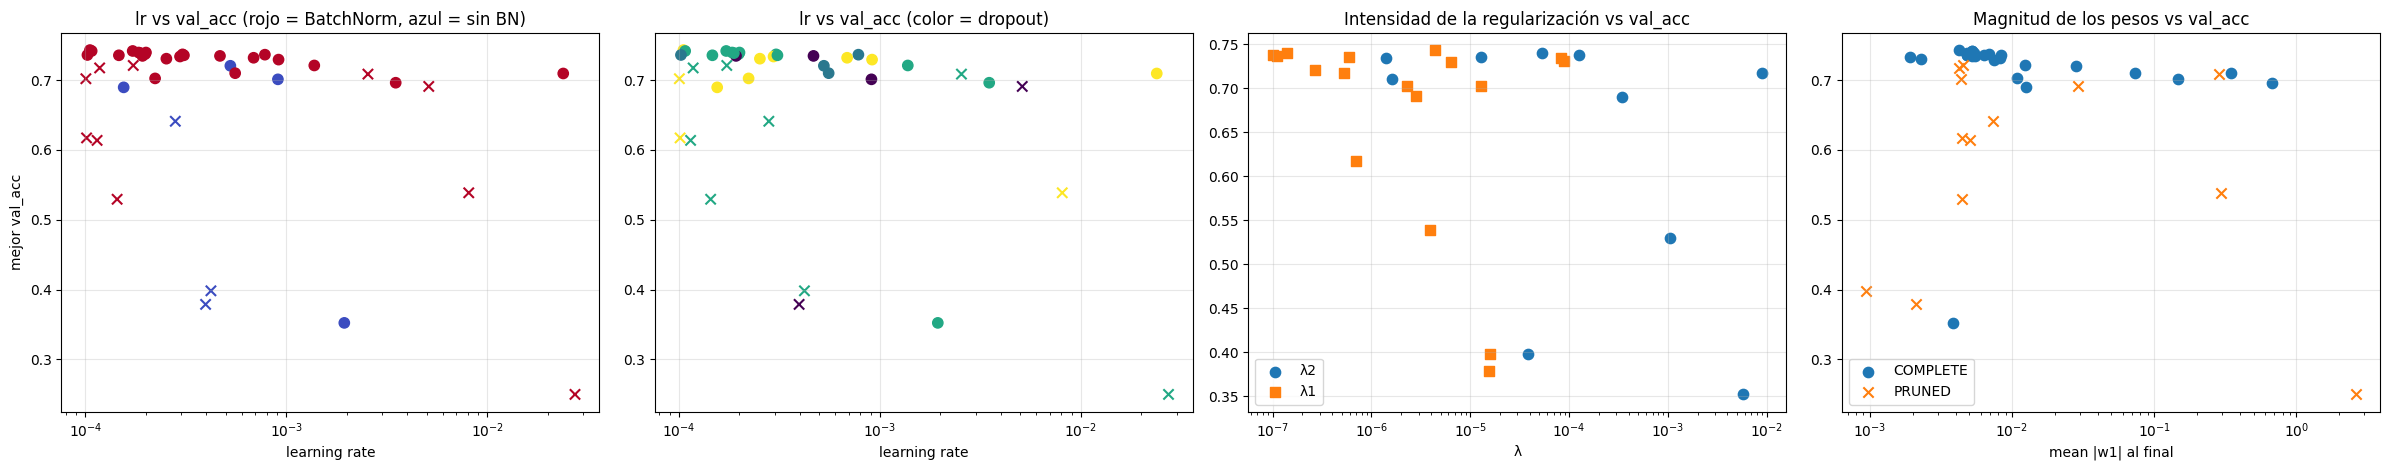

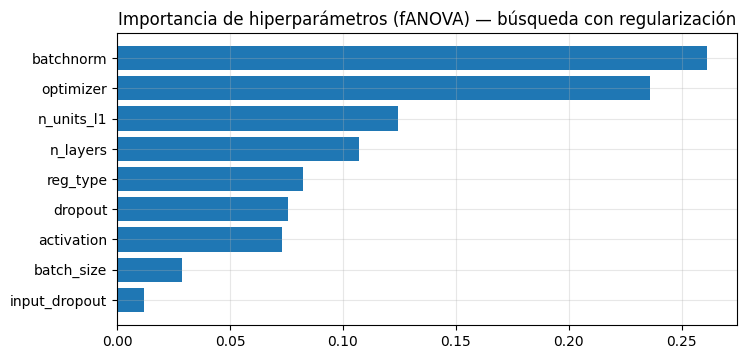

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(24, 4.8))
mk = {"COMPLETE": "o", "PRUNED": "x"}
for est, s in df_r.groupby("estado"):
    sc = axes[0].scatter(s["lr"], s["best_val_acc"], c=s["batchnorm"].astype(int), cmap="coolwarm", marker=mk[est], s=55, vmin=0, vmax=1)
axes[0].set_xscale("log"); axes[0].set(xlabel="learning rate", ylabel="mejor val_acc", title="lr vs val_acc (rojo = BatchNorm, azul = sin BN)")
for est, s in df_r.groupby("estado"):
    axes[1].scatter(s["lr"], s["best_val_acc"], c=s["dropout"], cmap="viridis", marker=mk[est], s=55, vmin=0, vmax=0.5)
axes[1].set_xscale("log"); axes[1].set(xlabel="learning rate", title="lr vs val_acc (color = dropout)")
s = df_r[df_r["l2"] > 0]; axes[2].scatter(s["l2"], s["best_val_acc"], label="λ2", s=55)
s = df_r[df_r["l1"] > 0]; axes[2].scatter(s["l1"], s["best_val_acc"], label="λ1", s=55, marker="s")
axes[2].set_xscale("log"); axes[2].set(xlabel="λ", title="Intensidad de la regularización vs val_acc"); axes[2].legend()
for est, s in df_r.groupby("estado"):
    axes[3].scatter(s["mean|w1|"], s["best_val_acc"], marker=mk[est], s=55, label=est)
axes[3].set_xscale("log"); axes[3].set(xlabel="mean |w1| al final", title="Magnitud de los pesos vs val_acc"); axes[3].legend()
for a in axes: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

try:
    imp = optuna.importance.get_param_importances(study_reg, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))
    plt.figure(figsize=(8, 3.8)); plt.barh(list(imp)[::-1], list(imp.values())[::-1])
    plt.title("Importancia de hiperparámetros (fANOVA) — búsqueda con regularización"); plt.grid(alpha=.3); plt.show()
except Exception as e:
    print("fANOVA no disponible:", e)

In [39]:
# Entrenamiento final con la mejor configuración regularizada y evaluación en test
bt_r = study_reg.best_trial; bpr = bt_r.params
print("Mejor configuración regularizada:", bpr, "| épocas:", bt_r.user_attrs["best_epoch"])
torch.manual_seed(SEED)
train_loader_fr = DataLoader(to_tensor_dataset(X_train_final, y_train_all), batch_size=bpr["batch_size"], shuffle=True)
model_r = RegMLP(X_train_final.shape[1], bt_r.user_attrs["hidden"], NUM_CLASSES, activation=bpr["activation"],
                 dropout=bpr["dropout"], input_dropout=bpr["input_dropout"], batchnorm=bpr["batchnorm"])
opt_fr = make_optimizer(bpr["optimizer"], model_r.parameters(), bt_r.user_attrs["lr"],
                        momentum=0.9 if bpr["optimizer"] == "rmsprop" else 0.0)
w = SummaryWriter(log_dir="runs/mlp_final_reg")
mlflow.end_run(); mlflow.set_experiment("mlp_20newsgroups")
with mlflow.start_run(run_name="mlp_final_reg"):
    mlflow.log_params({**bpr, "epochs": bt_r.user_attrs["best_epoch"]})
    h_fr = train_model_reg(model_r, train_loader_fr, test_loader_final, opt_fr, bt_r.user_attrs["best_epoch"],
                           l1=bt_r.user_attrs["l1"], l2=bt_r.user_attrs["l2"], writer=w, run_name="final_reg", verbose=True)
w.close()
test_acc_reg = h_fr["val_acc"][-1]
print(f"\nTest: MLP regularizado {test_acc_reg:.4f} | MLP de la búsqueda sin regularización explícita {test_accuracy:.4f} "
      f"| softmax TP1 {SOFTMAX_TP1_TEST_ACC:.4f}")
print(f"Error estándar aprox. en test (±): {np.sqrt(test_acc_reg * (1 - test_acc_reg) / len(y_test)):.4f}")

Mejor configuración regularizada: {'batch_size': 128, 'n_layers': 1, 'n_units_l1': 256, 'activation': 'relu', 'optimizer': 'adam', 'lr_adam': 0.00010538582799512661, 'reg_type': 'l1', 'lambda_l1': 4.427936336500086e-06, 'dropout': 0.5, 'input_dropout': 0.2, 'batchnorm': True} | épocas: 9
[final_reg] ép  1 | train 2.6018/0.2700 | val 2.4263/0.5461 | mean|w1| 4.14e-03 | lr 1.1e-04 | 2.3s
[final_reg] ép  2 | train 1.7770/0.6225 | val 1.7511/0.6403 | mean|w1| 4.15e-03 | lr 1.1e-04 | 2.4s
[final_reg] ép  3 | train 1.3634/0.7431 | val 1.5469/0.6636 | mean|w1| 4.17e-03 | lr 1.1e-04 | 2.2s
[final_reg] ép  4 | train 1.0856/0.8017 | val 1.4150/0.6718 | mean|w1| 4.19e-03 | lr 1.1e-04 | 2.2s
[final_reg] ép  5 | train 0.8933/0.8429 | val 1.3294/0.6774 | mean|w1| 4.21e-03 | lr 1.1e-04 | 2.2s
[final_reg] ép  6 | train 0.7555/0.8687 | val 1.2750/0.6788 | mean|w1| 4.23e-03 | lr 1.1e-04 | 2.2s
[final_reg] ép  7 | train 0.6362/0.8905 | val 1.2320/0.6799 | mean|w1| 4.25e-03 | lr 1.1e-04 | 2.3s
[final_reg]

### Análisis de la búsqueda con regularización

**Resumen.** 40 trials en **9,7 min** (27 completos, 13 podados). Tardó más que la primera búsqueda (7,7 min) porque L1/L2 encarecen cada época: 2,3 s/época de media con L1 contra 2,1 sin penalización.

**Mejor trial (#6, val_acc = 0.7433):** 1×256 ReLU, **Adam con lr = 1,05·10⁻⁴**, **L1 con λ₁ = 4,4·10⁻⁶**, dropout 0.5, **dropout de entrada 0.2**, **BatchNorm**, batch 128.

**No superó a la búsqueda sin regularización explícita** (0.7508). La diferencia (−0.0075) está dentro del error estándar (±0.009), así que es un **empate**. Los 12 mejores trials quedan todos entre 0.736 y 0.743: hay una meseta amplia de configuraciones equivalentes, y la regularización no movió el techo de accuracy del problema.

**Qué eligió TPE.** El top tiene un patrón muy claro: **BatchNorm**, **Adam con lr bajo** (1–3·10⁻⁴), 256 unidades, dropout 0.3–0.5 y dropout de entrada 0.2.

| | Trials | Podados | Mejor | Media |
|---|---|---|---|---|
| sin penalización | 18 | 4 | 0.7419 | **0.689** |
| L1 | 12 | 6 | **0.7433** | 0.669 |
| L1+L2 | 5 | 2 | 0.7397 | 0.665 |
| L2 | 5 | 1 | 0.7357 | 0.603 |
| BatchNorm sí | 33 | 10 | **0.7433** | **0.694** |
| BatchNorm no | 7 | 3 | 0.7207 | 0.555 |

- **L1/L2 explícitos no hacen falta.** El mejor sin penalización (0.7419) empata con el mejor con L1 (0.7433), y "sin penalización" tiene la **mejor media**. Las penalizaciones agregan riesgo (la mitad de los trials con L1 fueron podados) y costo de tiempo, sin ganancia. Coincide con el experimento controlado: en este problema su efecto principal es agregar bias.
- **Dropout.** Los mejores usan 0.5 (0.7433) y 0.3 (0.7419); sin dropout el máximo fue 0.7349. El **dropout de entrada 0.2** aparece en 29 de 40 trials y en el mejor: TPE lo favoreció, en línea con el experimento controlado.
- **BatchNorm** fue el hiperparámetro más importante según fANOVA (0.26, seguido del optimizador con 0.24). TPE lo eligió en 33 de 40 trials. Analisis:
  - Los 7 trials sin BN no son una muestra comparable: 4 de ellos usaban penalización L1/L2, y los peores combinaban esa penalización con dropout de entrada (#1: 0.35, #25: 0.40, #38: 0.38). El mejor sin BN llegó a 0.7207 (#0).
  - BN cambia cómo actúa la penalización: como la salida es invariante a la escala de los pesos de la capa que normaliza, achicar esos pesos con L1/L2 no reduce la capacidad de la red, porque BN reescala la preactivación. Por eso el trial #18 (λ₁ = 9·10⁻⁵ **con BN**) llegó a 0.731, mientras que en el experimento controlado λ₁ = 10⁻⁴ **sin BN** se quedó en 0.630.
  - Con BN, la penalización deja de restringir la capacidad y se comporta más bien como un ajuste del lr efectivo. Esto explica por qué los trials con penalización sólo funcionaron acompañados de BN.
- **BN y learning rate.** BN toleró lr muy altos sin diverger (#10, Adam con lr = 2,4·10⁻², llegó a 0.710). Pero los mejores trials usan lr **bajos** (1–3·10⁻⁴, menores incluso que el 5·10⁻⁴ de la primera búsqueda). En el experimento controlado, BN con lr = 10⁻³ llegó a su mejor punto en la época 1 y después sobreajustó; con lr más bajos el mejor punto llega más tarde (épocas 3–10 en el top) y es mejor, así que subir el lr sólo acelera el sobreajuste. Con RMSprop y lr = 2,7·10⁻² sí colapsó (0.25, podado).
- **Magnitud de los pesos.** Los mejores trials terminan con mean|w1| ≈ 0.004–0.008, casi en el valor de la inicialización (0.005). Los trials que terminan con pesos grandes (mean|w1| > 0.1, asociados a lr altos) no superan ~0.71 y varios fueron podados (gráfico de magnitud de los pesos vs val_acc). Es la relación "pesos chicos ↔ mejor generalización".
- **Importancia (fANOVA).** batchnorm 0.26, optimizador 0.24, unidades 0.12, capas 0.10, tipo de regularización 0.08, dropout 0.07, activación 0.07, batch 0.03, dropout de entrada 0.01. El tipo de penalización pesa poco frente a la arquitectura y la optimización.

**Test.** El modelo regularizado obtuvo **0.6816**, contra **0.6950** del MLP de la primera búsqueda y 0.6682 de la softmax del TP1. La diferencia con el MLP (−1,3 puntos) es de unos 2,5 errores estándar (±0.0054), así que el modelo regularizado es algo **peor** en test. Hay dos razones:
1. **Subentrenamiento.** Con lr = 10⁻⁴ y regularización fuerte, en las 9 épocas elegidas la loss de test todavía estaba bajando (1.19 en la época 9, contra 1.04 del modelo sin regularización explícita).
2. **Sesgo de selección.** Elegir el máximo entre 40 trials sobre una única validación es optimista: ambos modelos pierden ~6 puntos de validación a test.

**Conclusión.** La regularización hizo a los modelos **más estables** (val_loss que no se dispara, pesos chicos, menos sensibilidad a la cantidad de épocas), pero **no mejoró la accuracy**. El límite de este problema no es la varianza del modelo sino la **representación** bolsa de palabras: las confusiones entre religión, política y computación no se resuelven regularizando.


## 10. Análisis global: todos los entrenamientos

Se junto en una sola comparación **todos** los entrenamientos del TP: trials completos, trials podados y modelos del experimento de sobreajuste. Todos se evalúan sobre la **misma validación**.

La softmax "0 capas" del experimento de sobreajuste se entrenó sobre el mismo split que los MLP, así que es la referencia justa para medir cuánto aporta agregar capas ocultas. El valor de test del TP1 (0.668) también se compara con el test del MLP final (ver la aclaración de la sección 7 sobre ese valor).

- **Gráfico izquierdo**: performance contra tiempo total de entrenamiento. Lo ideal está arriba a la izquierda (mejor accuracy en menos tiempo).
- **Gráfico derecho**: costo por época contra tamaño del modelo, en escala log-log. Una pendiente ≈ 1 indica costo proporcional a la cantidad de parámetros.

*Esta comparación corresponde a los entrenamientos del TP2 (búsqueda y sobreajuste); los del TP3 se comparan en la sección 9.*

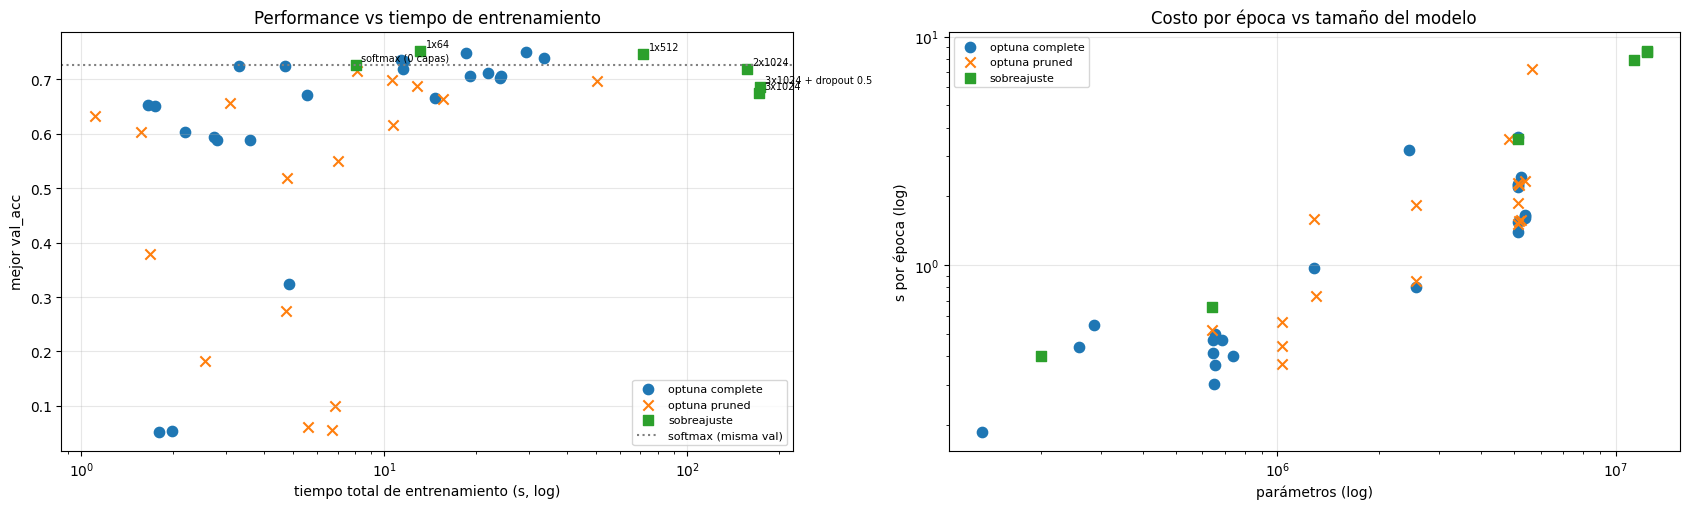

                 entrenamientos  mejor_val_acc  val_acc_media  tiempo_total_min  s_por_época_media
grupo                                                                                             
optuna complete              23          0.751          0.615             4.282              1.291
optuna pruned                17          0.715          0.476             2.566              1.827
sobreajuste                   6          0.753          0.718             9.918              4.959

Softmax (misma validación): 0.7265 | mejor MLP de la búsqueda: 0.7508 | diferencia: +0.0243
Test: MLP final 0.6950 vs softmax TP1 0.6682


In [40]:
# Comparación global de TODOS los entrenamientos: búsqueda, sobreajuste y modelo final
todos = []
for _, r in df.iterrows():
    todos.append({"grupo": "optuna " + r["estado"].lower(), "nombre": f"trial {r['trial']}",
                  "parámetros": r["n_params"], "mejor_val_acc": r["best_val_acc"],
                  "tiempo_total_s": r["train_time_s"], "s_por_época": r["s_por_época"], "épocas": r["épocas"]})
for name, r in overfit_results.items():
    h = r["history"]
    todos.append({"grupo": "sobreajuste", "nombre": name, "parámetros": r["n_params"],
                  "mejor_val_acc": max(h["val_acc"]), "tiempo_total_s": sum(h["epoch_time"]),
                  "s_por_época": np.mean(h["epoch_time"]), "épocas": len(h["val_acc"])})
df_all = pd.DataFrame(todos)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.2))
for g, s in df_all.groupby("grupo"):
    axes[0].scatter(s["tiempo_total_s"], s["mejor_val_acc"], s=55, label=g,
                    marker={"optuna complete": "o", "optuna pruned": "x", "sobreajuste": "s"}[g])
    axes[1].scatter(s["parámetros"], s["s_por_época"], s=55, label=g,
                    marker={"optuna complete": "o", "optuna pruned": "x", "sobreajuste": "s"}[g])
for _, r in df_all[df_all["grupo"] == "sobreajuste"].iterrows():
    axes[0].annotate(r["nombre"], (r["tiempo_total_s"], r["mejor_val_acc"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
axes[0].axhline(df_all.loc[df_all["nombre"] == "softmax (0 capas)", "mejor_val_acc"].iloc[0], ls=":", c="gray",
                label="softmax (misma val)")
axes[0].set_xscale("log"); axes[0].set_xlabel("tiempo total de entrenamiento (s, log)"); axes[0].set_ylabel("mejor val_acc")
axes[0].set_title("Performance vs tiempo de entrenamiento")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("parámetros (log)")
axes[1].set_ylabel("s por época (log)"); axes[1].set_title("Costo por época vs tamaño del modelo")
for a in axes:
    a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(df_all.groupby("grupo").agg(entrenamientos=("nombre", "count"), mejor_val_acc=("mejor_val_acc", "max"),
                                  val_acc_media=("mejor_val_acc", "mean"), tiempo_total_min=("tiempo_total_s", lambda s: s.sum() / 60),
                                  s_por_época_media=("s_por_época", "mean")).round(3).to_string())
softmax_val = df_all.loc[df_all["nombre"] == "softmax (0 capas)", "mejor_val_acc"].iloc[0]
print(f"\nSoftmax (misma validación): {softmax_val:.4f} | mejor MLP de la búsqueda: {df_ok['best_val_acc'].max():.4f} "
      f"| diferencia: {df_ok['best_val_acc'].max() - softmax_val:+.4f}")
print(f"Test: MLP final {test_accuracy:.4f} vs softmax TP1 {SOFTMAX_TP1_TEST_ACC:.4f}")

### Análisis global

| Grupo | Entrenamientos | Mejor val_acc | Media | Tiempo total |
|---|---|---|---|---|
| Optuna completos | 23 | 0.751 | 0.615 | 4,3 min |
| Optuna podados | 17 | 0.715 | 0.476 | 2,6 min |
| Experimento de sobreajuste | 6 | 0.753 | 0.718 | **9,9 min** |

**Performance.** Sobre la misma validación:
- softmax: **0.7265**;
- mejor MLP de la búsqueda: **0.7508** (+2,4 puntos);
- MLP 1×64 del experimento de sobreajuste: **0.7525** (+2,6 puntos).

En test, MLP **0.695** contra softmax **0.668** (+2,7 puntos; +4,9 contra el 0.646 de las salidas guardadas del TP1, ver sección 7). Las tres comparaciones coinciden: **las capas ocultas aportan ~2,5 puntos**, una mejora real pero acotada. Para clasificar temas con bolsa de palabras, la softmax ya resuelve la mayor parte del problema, porque en 10.000 dimensiones los datos son casi linealmente separables.

**Tiempo.** El gráfico de performance contra tiempo muestra que **más tiempo no compra más accuracy**:
- Los entrenamientos más largos (2×1024 y 3×1024, 2–3 minutos cada uno) están entre los **peores** en validación.
- Las mejores configuraciones (1×64, 1×512 con dropout) se entrenan en 5–30 segundos.
- **El experimento de sobreajuste, con sólo 6 entrenamientos, tardó más (9,9 min) que los 40 trials de la búsqueda (6,8 min)**: los modelos sobredimensionados son a la vez los más caros y los que peor generalizan.

**Costo por época contra tamaño.** En escala log-log, la relación es aproximadamente lineal: el costo lo domina la primera capa ($d \times h_1$). Los podados aparecen en todo el rango de tamaños: el pruner no los eligió por ser grandes, sino por rendir por debajo de la mediana.

## 11. Conclusiones

### Regularización (TP3)

1. **Dropout fue la regularización más efectiva.** Sobre la red 1×512 que sobreajustaba, el dropout 0.5 combinado con **dropout en la entrada (0.2)**:
   - redujo la subida de la val_loss de ×1.22 a ×1.10;
   - bajó la brecha train−val;
   - mejoró la val_acc final en 1,1 puntos, sin costo de tiempo.

   El dropout de entrada ataca la memorización de la primera capa (cada palabra conectada a 512 neuronas), que era lo que el dropout oculto solo no lograba en la sección 8. Como predice la teoría, las curvas de entrenamiento son más ruidosas y el mejor punto se alcanza más tarde (época 5–7 en lugar de 3).

2. **L2 achica los pesos y frena el sobreajuste de la loss, pero agrega bias.**
   - Al aumentar λ₂ de 10⁻⁵ a 10⁻³, la magnitud media de los pesos de la primera capa bajó 6 veces y la val_loss dejó de subir (×1.01).
   - A la vez, la val_acc bajó de 0.749 a 0.711.
   - Con Adam el efecto se exagera: la penalización acoplada se normaliza por $\sqrt{\hat v}$ y castiga sobre todo a las palabras raras.
   - AdamW (decaimiento desacoplado) con 10⁻² casi no modificó los pesos, mientras que L2 = 10⁻⁵ acoplado los redujo un 43%.

3. **L1 hace la red esparsa y selecciona palabras.**
   - Con λ₁ = 10⁻⁵ se puede podar el **91%** de los pesos de la primera capa sin perder accuracy, y con 10⁻⁴ el 99%. En la base sólo es posible podar un 12%.
   - El histograma de pesos es bimodal: muchos ≈ 0 y algunos más grandes que en la base.
   - L1 descartó 2.737 de las 10.000 palabras y conservó las palabras temáticas frecuentes (*space, gun, hockey, nasa*) en lugar de los términos raros que memorizaba la base.
   - Con Adam los pesos "eliminados" no llegan a 0 exacto: quedan oscilando cerca de 0 (≈10⁻⁴).

4. **L1+L2** quedó en el medio en todo (esparsidad parcial, pesos chicos, accuracy menor) y fue la opción más cara.

5. **BatchNorm acelera pero no regulariza.**
   - Llevó a la red a su mejor punto en la **primera época**, pero después sobreajustó igual que sin BN.
   - Mantuvo los pesos casi en su valor inicial, porque con BN la salida es invariante a la escala de W.
   - Toleró un lr 10 veces mayor con un entrenamiento más estable que sin BN (val_loss ×1.32 vs ×1.52, pesos máximos a la mitad), aunque sin ganar accuracy.
   - Combinado con dropout no aportó nada, como se recomienda en clase.

6. **Learning rate.** La recomendación de usar lr 10–100× mayor con dropout no se trasladó a Adam: con lr = 10⁻² la red sobreajustó en la primera época, y el `ReduceLROnPlateau` sólo estabilizó la curva. Con BN, los mejores trials de Optuna también usaron lr **bajos** (1–3·10⁻⁴). La estabilidad que da BN no se traduce en que convenga subir el lr cuando la convergencia ya es rápida.

7. **Tiempos.**
   - L1 y L2 son las únicas técnicas caras: +35–47% por época, y +82% combinadas, porque la penalización se calcula sobre 5,1 M de pesos en cada batch.
   - Dropout y BN tienen costo despreciable.
   - AdamW agrega sólo un 6%, porque aplica el decaimiento dentro del paso del optimizador.

8. **Búsqueda con regularización y test.**
   - Optuna llegó a **0.7433**, un empate con los 0.7508 sin regularización explícita (error estándar ±0.009), con un patrón claro: BN + Adam con lr bajo + dropout + dropout de entrada.
   - L1/L2 explícitos no mejoraron a los trials sin penalización.
   - fANOVA ubicó a BatchNorm y al optimizador como lo más importante; el tipo de penalización pesó poco (0.08).
   - En test, el modelo regularizado obtuvo **0.682** contra 0.695 del MLP sin regularización explícita, en parte por quedar subentrenado con lr = 10⁻⁴.
   - Conclusión general: la regularización hace los modelos más **estables**, pero el techo de accuracy lo pone la **representación** TF-IDF, no la varianza del modelo.

### Resultados heredados del TP2

9. **Mejor configuración sin regularización explícita.** Optuna eligió un MLP de **1 capa oculta de 512 neuronas con LeakyReLU y dropout 0.5**, entrenado con **Adam** (lr = 5·10⁻⁴, β₁ = 0.95, β₂ = 0.9999) y batch 128. Usó el mismo preprocesamiento que el mejor trial descripto en el análisis del TP1 (**stem, unigramas, 10.000 features**); da lo mismo quitar o no las stopwords. Alcanzó 0.751 en validación y **0.695 en test**.

10. **MLP vs softmax.** Las capas ocultas mejoran **~2,5 puntos** de forma consistente: +2,4 en validación (0.751 vs 0.727) y +2,7 en test (0.695 vs 0.668; +4,9 contra el 0.646 de las salidas guardadas del TP1, ver sección 7). La mejora es real (supera el error estándar), pero modesta. Su costo es de ~1,7 a 20 veces más tiempo por época, según el tamaño, y la pérdida de interpretabilidad. Las confusiones principales (religión, política, computación) **no cambian**: son límites de la representación bolsa de palabras y de las propias categorías, no del modelo.

11. **Optimizadores y momentos.**
    - **Adam** dio el mejor trial y **RMSprop** fue el más robusto (mejor media). Ambos funcionan gracias a la normalización por el **momento de orden 2**, clave con features TF-IDF chicos y dispersos.
    - **SGD fracasó**: sin momento no avanza o diverge, y sólo con **momento de orden 1 alto** (0.99) llegó a 0.59, todavía sin converger.
    - En RMSprop, agregar momentum (orden 1) mejoró los resultados.
    - El análisis fANOVA confirma que **el optimizador es el hiperparámetro más importante** (0.47).
    - El **learning rate** fue más determinante que los valores de β₁/β₂. Los MLP necesitan lr ~10 veces menores que la softmax.

12. **Activaciones y profundidad.**
    - ReLU, LeakyReLU y GELU dominaron.
    - **Sigmoid fue la peor** (4 de 5 trials podados) por saturación y desvanecimiento del gradiente. Tanh quedó intermedia.
    - **Una capa oculta alcanza**: 2 capas no mejoraron y 3 capas rindieron peor y costaron más.

13. **Sobreajuste.** El modelo de **3 capas de 1024 neuronas** (12,4 M de parámetros) sobreajusta claramente:
    - su val_loss se duplica desde su mínimo en la época 2;
    - tiene la mayor brecha (0.31);
    - queda ~8 puntos por debajo del mejor modelo.

    El sobreajuste crece de forma **monótona con la capacidad**. El **modelo chico (1×64) fue el mejor de todo el trabajo** (0.7525), empatado con el de Optuna con 8 veces menos parámetros.

14. **Tiempos y pruning.**
    - La búsqueda sin regularización (40 trials) tomó 7,7 minutos; el costo por época crece con los parámetros (Spearman +0.79) y lo domina la primera capa.
    - Los 6 entrenamientos del experimento de sobreajuste tardaron **más que toda la búsqueda**.
    - El pruning podó **17 de 40 trials (42%)**, sobre todo sigmoid, SGD y lr inadecuados, y ahorró ~5,2 minutos (**43%**). Junto con el early stopping, ahorró más de la mitad del tiempo.
    - No descartó configuraciones ganadoras: el mejor trial podado iba en 0.715.

15. **Reproducibilidad.** Con semillas fijas (incluida la del sampler TPE), las accuracies se repiten exactamente entre corridas. Sólo cambian los tiempos (±10%), que dependen de la carga de la máquina, por lo que las comparaciones de tiempo se hacen dentro de una misma corrida.

### Mejoras posibles
- Probar AdamW con weight decay mayor (10⁻¹–1): con lr = 10⁻³, el valor usado (10⁻²) casi no tuvo efecto.
- Explorar dropout de entrada más alto (0.3–0.5) y redes chicas (32–128 neuronas), dado que 1×64 empató con 1×512.
- Usar validación cruzada para reducir el ruido de un único split y el sesgo de elegir el máximo entre muchos trials.
- Para atacar las confusiones semánticas, cambiar la representación (embeddings o modelos con contexto) en vez de TF-IDF.
